# Quantum Graph Encoding for Molecular Representation in Drug Discovery


## Environment

In [1]:
import importlib.util
import os
import subprocess
import sys
import time
from pathlib import Path

_CELL_STARTED = time.perf_counter()
print("[CELL 01 START] Environment and dependency check", flush=True)

os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("MKL_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

                                                                            
                                                                           
                                                                          
REQUIRED_MODULES = {
    "kagglehub": "kagglehub>=1.0.0,<1.2",
    "rdkit": "rdkit>=2024.3",
    "pennylane": "pennylane>=0.45,<0.46",
    "xgboost": "xgboost>=2.0,<3.2",
}

shadow_names = {
    "torch.py", "pennylane.py", "xgboost.py", "rdkit.py",
    "torch", "pennylane", "xgboost", "rdkit",
}
shadowed = [
    str(path)
    for path in Path.cwd().iterdir()
    if path.name in shadow_names
]
if shadowed:
    raise RuntimeError(
        "Local files/folders are shadowing installed packages. Rename or remove: "
        + ", ".join(shadowed)
    )

missing = [
    requirement
    for module, requirement in REQUIRED_MODULES.items()
    if importlib.util.find_spec(module) is None
]

if missing:
    print("[ENV] Installing only missing packages:", missing, flush=True)
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "--quiet",
            "--no-cache-dir",
            *missing,
        ]
    )
else:
    print("[ENV] Required packages are already available.", flush=True)

print(
    "[ENV] PyTorch Geometric is intentionally not imported or installed.",
    flush=True,
)
print(
    f"[CELL 01 DONE] Environment check finished in "
    f"{time.perf_counter() - _CELL_STARTED:.2f}s",
    flush=True,
)

[CELL 01 START] Environment and dependency check
[ENV] Installing only missing packages: ['rdkit>=2024.3', 'pennylane>=0.45,<0.46']
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.4/37.4 MB 231.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 191.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 126.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 162.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 240.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 183.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 164.5 MB/s eta 0:00:00
[ENV] PyTorch Geometric is intentionally not imported or installed.
[CELL 01 DONE] Environment check finished in 15.40s


## Imports

In [2]:
from __future__ import annotations

import copy
import gc
import hashlib
import json
import math
import os
import random
import shutil
import time
import urllib.error
import urllib.request
import warnings
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from importlib.metadata import version as package_version
from pathlib import Path
from typing import Any, Iterable, Sequence

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pennylane as qml
import scipy.stats as stats
os.environ.setdefault("TORCH_COMPILE_DISABLE", "1")
import torch
import torch.nn as nn
import torch.nn.functional as F
import xgboost as xgb

from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import (
    AllChem,
    BRICS,
    Crippen,
    Descriptors,
    Lipinski,
    QED,
    rdMolDescriptors,
)
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from torch.optim.lr_scheduler import LambdaLR
from torch.utils.data import DataLoader as TorchDataLoader
from torch.utils.data import Dataset as TorchDataset
from torch.utils.data import TensorDataset

_CELL_STARTED = time.perf_counter()
print("[CELL 02 START] Imports and native graph engine", flush=True)

try:
    torch.set_num_threads(min(4, os.cpu_count() or 1))
except RuntimeError:
    pass

try:
    torch.set_num_interop_threads(1)
except RuntimeError:
    pass

warnings.filterwarnings("ignore", category=UserWarning)
RDLogger.DisableLog("rdApp.warning")
RDLogger.DisableLog("rdApp.error")
pd.set_option("display.max_columns", 200)


class Data:


    def __init__(self, **kwargs: Any):
        for key, value in kwargs.items():
            setattr(self, key, value)

    def to(self, device: torch.device | str) -> "Data":
        for key, value in vars(self).items():
            if torch.is_tensor(value):
                setattr(self, key, value.to(device))
        return self


class Batch(Data):


    @classmethod
    def from_data_list(cls, graphs: Sequence[Data]) -> "Batch":
        if not graphs:
            raise ValueError("Cannot batch an empty graph list.")

        x_values = []
        pe_values = []
        motif_values = []
        edge_indices = []
        edge_attributes = []
        graph_ids = []
        y_values = []
        y_model_values = []
        record_ids = []

        node_offset = 0
        for graph_id, graph in enumerate(graphs):
            node_count = int(graph.x.size(0))
            x_values.append(graph.x)
            pe_values.append(graph.lap_pe)
            motif_values.append(graph.motif_prior)
            graph_ids.append(
                torch.full((node_count,), graph_id, dtype=torch.long)
            )

            if graph.edge_index.numel() > 0:
                edge_indices.append(graph.edge_index + node_offset)
                edge_attributes.append(graph.edge_attr)

            y_values.append(graph.y.view(-1))
            if hasattr(graph, "y_model"):
                y_model_values.append(graph.y_model.view(-1))
            if hasattr(graph, "record_id"):
                record_ids.append(graph.record_id.view(-1))

            node_offset += node_count

        edge_index = (
            torch.cat(edge_indices, dim=1)
            if edge_indices
            else torch.empty((2, 0), dtype=torch.long)
        )
        edge_attr_dim = int(graphs[0].edge_attr.size(-1))
        edge_attr = (
            torch.cat(edge_attributes, dim=0)
            if edge_attributes
            else torch.empty((0, edge_attr_dim), dtype=torch.float32)
        )

        payload: dict[str, Any] = {
            "x": torch.cat(x_values, dim=0),
            "lap_pe": torch.cat(pe_values, dim=0),
            "motif_prior": torch.cat(motif_values, dim=0),
            "edge_index": edge_index,
            "edge_attr": edge_attr,
            "batch": torch.cat(graph_ids, dim=0),
            "y": torch.cat(y_values, dim=0),
            "num_graphs": len(graphs),
        }
        if y_model_values:
            payload["y_model"] = torch.cat(y_model_values, dim=0)
        if record_ids:
            payload["record_id"] = torch.cat(record_ids, dim=0)

        return cls(**payload)


class GraphDataLoader(TorchDataLoader):
    def __init__(self, dataset: Sequence[Data], **kwargs: Any):
        super().__init__(
            dataset,
            collate_fn=Batch.from_data_list,
            **kwargs,
        )


                                                   
DataLoader = GraphDataLoader
TensorLoader = TorchDataLoader


def to_dense_batch(
    x: torch.Tensor,
    batch: torch.Tensor,
) -> tuple[torch.Tensor, torch.Tensor]:
    if x.size(0) != batch.numel():
        raise ValueError("x and batch must contain the same number of nodes.")

    graph_count = int(batch.max().item()) + 1 if batch.numel() else 0
    counts = torch.bincount(batch, minlength=graph_count)
    max_nodes = int(counts.max().item()) if graph_count else 0

    output = x.new_zeros((graph_count, max_nodes, *x.shape[1:]))
    mask = torch.zeros(
        (graph_count, max_nodes),
        dtype=torch.bool,
        device=x.device,
    )

    offset = 0
    for graph_id, count_tensor in enumerate(counts):
        count = int(count_tensor.item())
        if count:
            output[graph_id, :count] = x[offset : offset + count]
            mask[graph_id, :count] = True
        offset += count

    return output, mask


def to_dense_adj(
    edge_index: torch.Tensor,
    batch: torch.Tensor,
    edge_attr: torch.Tensor | None = None,
    max_num_nodes: int | None = None,
) -> torch.Tensor:
    graph_count = int(batch.max().item()) + 1 if batch.numel() else 0
    counts = torch.bincount(batch, minlength=graph_count)
    max_nodes = (
        int(max_num_nodes)
        if max_num_nodes is not None
        else (int(counts.max().item()) if graph_count else 0)
    )

    if edge_attr is None:
        edge_attr = torch.ones(
            edge_index.size(1),
            dtype=torch.float32,
            device=edge_index.device,
        )
    if edge_attr.dim() != 1:
        raise ValueError("This notebook expects scalar edge weights in to_dense_adj.")

    adjacency = edge_attr.new_zeros((graph_count, max_nodes, max_nodes))
    if edge_index.numel() == 0:
        return adjacency

    offsets = torch.zeros(
        graph_count,
        dtype=torch.long,
        device=batch.device,
    )
    if graph_count > 1:
        offsets[1:] = torch.cumsum(counts[:-1], dim=0)

    source = edge_index[0]
    destination = edge_index[1]
    edge_graph = batch[source]
    local_source = source - offsets[edge_graph]
    local_destination = destination - offsets[edge_graph]

    adjacency.index_put_(
        (edge_graph, local_source, local_destination),
        edge_attr,
        accumulate=True,
    )
    return adjacency


def global_mean_pool(
    x: torch.Tensor,
    batch: torch.Tensor,
) -> torch.Tensor:
    graph_count = int(batch.max().item()) + 1 if batch.numel() else 0
    output = x.new_zeros((graph_count, x.size(-1)))
    output.index_add_(0, batch, x)
    counts = torch.bincount(
        batch,
        minlength=graph_count,
    ).to(x.dtype).clamp_min(1.0)
    return output / counts.unsqueeze(-1)


def segment_softmax(
    values: torch.Tensor,
    groups: torch.Tensor,
    group_count: int,
) -> torch.Tensor:
    values = values.view(-1)
    maxima = torch.full(
        (group_count,),
        -torch.inf,
        dtype=values.dtype,
        device=values.device,
    )
    maxima.scatter_reduce_(
        0,
        groups,
        values,
        reduce="amax",
        include_self=True,
    )
    shifted = values - maxima[groups]
    exponentials = shifted.exp()
    denominators = torch.zeros_like(maxima)
    denominators.index_add_(0, groups, exponentials)
    return exponentials / denominators[groups].clamp_min(1e-12)


class AttentionalAggregation(nn.Module):
    def __init__(self, gate_nn: nn.Module, nn: nn.Module):
        super().__init__()
        self.gate_nn = gate_nn
        self.value_nn = nn

    def forward(
        self,
        x: torch.Tensor,
        batch: torch.Tensor,
    ) -> torch.Tensor:
        graph_count = int(batch.max().item()) + 1
        scores = self.gate_nn(x).view(-1)
        weights = segment_softmax(scores, batch, graph_count)
        values = self.value_nn(x) * weights.unsqueeze(-1)
        output = values.new_zeros((graph_count, values.size(-1)))
        output.index_add_(0, batch, values)
        return output


class GINEConv(nn.Module):
    def __init__(
        self,
        nn: nn.Module,
        edge_dim: int,
        train_eps: bool = True,
    ):
        super().__init__()
        self.mlp = nn
        epsilon = torch.zeros(1)
        if train_eps:
            self.eps = torch.nn.Parameter(epsilon)
        else:
            self.register_buffer("eps", epsilon)
        self.edge_projection = torch.nn.Identity()

    def forward(
        self,
        x: torch.Tensor,
        edge_index: torch.Tensor,
        edge_attr: torch.Tensor,
    ) -> torch.Tensor:
        aggregated = torch.zeros_like(x)
        if edge_index.numel() > 0:
            source, destination = edge_index
            messages = F.silu(x[source] + self.edge_projection(edge_attr))
            aggregated.index_add_(0, destination, messages)
        return self.mlp((1.0 + self.eps) * x + aggregated)


class GPSConv(nn.Module):


    def __init__(
        self,
        channels: int,
        conv: GINEConv,
        heads: int,
        dropout: float,
        act: str = "silu",
        norm: str = "batch_norm",
        attn_type: str = "multihead",
    ):
        super().__init__()
        if channels % heads != 0:
            raise ValueError("channels must be divisible by attention heads.")
        self.local_conv = conv
        self.global_attention = nn.MultiheadAttention(
            channels,
            heads,
            dropout=dropout,
            batch_first=True,
        )
        self.dropout = nn.Dropout(dropout)
        self.norm_local = nn.LayerNorm(channels)
        self.norm_global = nn.LayerNorm(channels)
        self.norm_ffn = nn.LayerNorm(channels)
        self.ffn = nn.Sequential(
            nn.Linear(channels, 2 * channels),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(2 * channels, channels),
        )

    def forward(
        self,
        x: torch.Tensor,
        edge_index: torch.Tensor,
        batch: torch.Tensor,
        edge_attr: torch.Tensor,
    ) -> torch.Tensor:
        local = self.local_conv(x, edge_index, edge_attr)
        x = self.norm_local(x + self.dropout(local))

        dense, mask = to_dense_batch(x, batch)
        attended, _ = self.global_attention(
            dense,
            dense,
            dense,
            key_padding_mask=~mask,
            need_weights=False,
        )
        global_flat = attended[mask]
        x = self.norm_global(x + self.dropout(global_flat))
        x = self.norm_ffn(x + self.dropout(self.ffn(x)))
        return x


print("PyTorch:", torch.__version__, flush=True)
print("Native graph engine: enabled (no torch_geometric dependency)", flush=True)
print("PennyLane:", qml.__version__, flush=True)
print("XGBoost:", xgb.__version__, flush=True)
print("KaggleHub:", package_version("kagglehub"), flush=True)

                                    
_smoke_graphs = [
    Data(
        x=torch.randn(3, 4),
        lap_pe=torch.randn(3, 2),
        motif_prior=F.softmax(torch.randn(3, 5), dim=-1),
        edge_index=torch.tensor([[0, 1, 1, 2], [1, 0, 2, 1]]),
        edge_attr=torch.randn(4, 5),
        y=torch.tensor([1.0]),
        record_id=torch.tensor([0]),
    ),
    Data(
        x=torch.randn(2, 4),
        lap_pe=torch.randn(2, 2),
        motif_prior=F.softmax(torch.randn(2, 5), dim=-1),
        edge_index=torch.tensor([[0, 1], [1, 0]]),
        edge_attr=torch.randn(2, 5),
        y=torch.tensor([0.0]),
        record_id=torch.tensor([1]),
    ),
]
_smoke_batch = Batch.from_data_list(_smoke_graphs)
assert _smoke_batch.x.shape[0] == 5
assert _smoke_batch.num_graphs == 2
assert to_dense_batch(_smoke_batch.x, _smoke_batch.batch)[0].shape[:2] == (2, 3)
print("[SMOKE] Native graph batching and dense conversion passed.", flush=True)

print(
    f"[CELL 02 DONE] Imports and graph engine finished in "
    f"{time.perf_counter() - _CELL_STARTED:.2f}s",
    flush=True,
)

[CELL 02 START] Imports and native graph engine
PyTorch: 2.10.0+cu128
Native graph engine: enabled (no torch_geometric dependency)
PennyLane: 0.45.1
XGBoost: 3.2.0
KaggleHub: 1.0.0
[SMOKE] Native graph batching and dense conversion passed.
[CELL 02 DONE] Imports and graph engine finished in 0.11s


## Configuration

In [3]:
import time as _cell_time
_CELL_03_STARTED = _cell_time.perf_counter()
print("[CELL 03 START] 2. Locked full-study configuration", flush=True)

@dataclass
class ResearchConfig:
    work_root: str = "/kaggle/working/qgme_dissertation_v20_final"
    persistent_dataset_handle: str = "abdulbasitbaloch/qgme-v20-final-fresh-state"
    enable_persistent_sync: bool = True
    experiment_version: str = "v20_fresh_nested_safe_topology_quantum_18jobs"

    split_seed: int = 20260805
    primary_dataset: str = "BBBP"
    primary_seeds: tuple[int, ...] = (19, 53)
    secondary_datasets: tuple[str, ...] = ("BACE", "ESOL")
    secondary_seeds: tuple[int, ...] = (19, 53)
    outer_folds: int = 3

    max_wall_hours_per_run: float = 6.0
    final_sync_buffer_minutes: float = 20.0
    periodic_sync_minutes: float = 45.0

    morgan_bits: int = 1024
    morgan_radius: int = 2
    lap_pe_dim: int = 8
    hidden_dim: int = 128
    gnn_layers: int = 4
    attention_heads: int = 4
    dropout: float = 0.15
    graph_batch_size: int = 96

    n_qubits: int = 6
    quantum_layers: int = 2
    tensor_batch_size: int = 64
    mlp_hidden_dim: int = 256
    mlp_epochs: int = 45
    mlp_patience: int = 8
    mlp_lr: float = 1.0e-3

    gnn_epochs: int = 60
    tokenizer_epochs: int = 32
    fusion_epochs: int = 30
    adapter_epochs: int = 30
    topology_adapter_epochs: int = 42
    gnn_patience: int = 10
    tokenizer_patience: int = 8
    fusion_patience: int = 6
    adapter_patience: int = 7
    topology_adapter_patience: int = 10

    gnn_lr: float = 1.5e-3
    tokenizer_lr: float = 5e-4
    fusion_lr: float = 2e-3
    adapter_lr: float = 1.2e-3
    proposed_adapter_lr: float = 7.5e-4
    weight_decay: float = 2e-5

    mincut_weight: float = 0.025
    orthogonality_weight: float = 0.05
    feature_reconstruction_weight: float = 0.04
    topology_reconstruction_weight: float = 0.05
    entropy_target_weight: float = 0.05
    alignment_weight: float = 0.025
    token_balance_weight: float = 0.08
    token_diversity_weight: float = 0.03
    gumbel_start_temperature: float = 1.20
    gumbel_end_temperature: float = 0.55
    hard_assignment_fraction: float = 0.68
    tokenizer_eval_temperature: float = 0.65
    sinkhorn_iterations: int = 3
    sinkhorn_strength: float = 0.35
    assignment_entropy_target: float = 0.35
    topology_view_count: int = 3
    topology_hidden_dim: int = 64
    topology_sparsity_slope: float = 12.0
    topology_dropout_probability: float = 0.10
    topology_jitter_std: float = 0.02
    motif_prior_strength: float = 1.25
    motif_alignment_weight: float = 0.06
    motif_affinity_weight: float = 0.35
    correction_clip: float = 2.5

    ranking_loss_weight: float = 0.45
    regression_mse_weight: float = 0.75
    residual_alignment_weight: float = 0.30
    quantum_consistency_probability: float = 0.55
    quantum_angle_jitter_std: float = 0.025
    quantum_consistency_weight: float = 0.04
    correction_regularization_weight: float = 0.020
    residual_context_dim: int = 64
    residual_alpha_init: float = -1.40
    proposed_alpha_init: float = -1.75
    quantum_auxiliary_weight: float = 0.08
    proposed_fusion_lr_scale: float = 0.0
    anchor_regularization_weight: float = 0.035
    stack_quantum_weight_grid: tuple[float, ...] = (0.0, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40)
    stack_quantum_preference_tolerance: float = 0.0015

    xgb_estimators: int = 550
    xgb_max_depth: int = 5
    xgb_learning_rate: float = 0.03
    xgb_early_stopping_rounds: int = 45

    bootstrap_iterations: int = 400
    noise_grid: tuple[float, ...] = (0.0, 0.005, 0.01, 0.02)
    zne_scale_factors: tuple[float, ...] = (1.0, 2.0, 3.0)
    noise_max_samples_per_job: int = 64
    blend_grid_size: int = 81
    blend_max_weight: float = 1.25
    blend_bootstrap_iterations: int = 101
    blend_stability_penalty: float = 0.15

CFG = ResearchConfig()
MODE = "FULL"
WORK_ROOT = Path(CFG.work_root)
STATE_ROOT = WORK_ROOT / "persistent_state"
STATE_DIR = STATE_ROOT / CFG.experiment_version / "full"
RAW_DATA_DIR = WORK_ROOT / "raw_datasets"
DATA_CACHE_DIR = STATE_DIR / "dataset_cache"
GRAPH_DIR = STATE_DIR / "graphs"
SPLIT_DIR = STATE_DIR / "splits"
JOB_DIR = STATE_DIR / "jobs"
RESULT_DIR = STATE_DIR / "results"
FIGURE_DIR = STATE_DIR / "figures"
EXPORT_DIR = STATE_DIR / "export"
RESTORE_DIR = WORK_ROOT / "_restore"
for path in (WORK_ROOT, STATE_ROOT, STATE_DIR, RAW_DATA_DIR, DATA_CACHE_DIR, GRAPH_DIR, SPLIT_DIR, JOB_DIR, RESULT_DIR, FIGURE_DIR, EXPORT_DIR):
    path.mkdir(parents=True, exist_ok=True)
CLASSICAL_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
QUANTUM_DEVICE = torch.device("cpu")
SESSION_STARTED_MONOTONIC = time.monotonic()
print(json.dumps(asdict(CFG), indent=2))
print("Study: completely fresh V20 retraining with protected topology-quantum stacking")
print("Classical device:", CLASSICAL_DEVICE)
print("Quantum simulator device:", QUANTUM_DEVICE)
print(f"[CELL 03 DONE] Configuration finished in {_cell_time.perf_counter()-_CELL_03_STARTED:.2f}s", flush=True)


[CELL 03 START] 2. Locked full-study configuration
{
  "work_root": "/kaggle/working/qgme_dissertation_v20_final",
  "persistent_dataset_handle": "abdulbasitbaloch/qgme-v20-final-fresh-state",
  "enable_persistent_sync": true,
  "experiment_version": "v20_fresh_nested_safe_topology_quantum_18jobs",
  "split_seed": 20260805,
  "primary_dataset": "BBBP",
  "primary_seeds": [
    19,
    53
  ],
  "secondary_datasets": [
    "BACE",
    "ESOL"
  ],
  "secondary_seeds": [
    19,
    53
  ],
  "outer_folds": 3,
  "max_wall_hours_per_run": 6.0,
  "final_sync_buffer_minutes": 20.0,
  "periodic_sync_minutes": 45.0,
  "morgan_bits": 1024,
  "morgan_radius": 2,
  "lap_pe_dim": 8,
  "hidden_dim": 128,
  "gnn_layers": 4,
  "attention_heads": 4,
  "dropout": 0.15,
  "graph_batch_size": 96,
  "n_qubits": 6,
  "quantum_layers": 2,
  "tensor_batch_size": 64,
  "mlp_hidden_dim": 256,
  "mlp_epochs": 45,
  "mlp_patience": 8,
  "mlp_lr": 0.001,
  "gnn_epochs": 60,
  "tokenizer_epochs": 32,
  "fusion_epo

## Persistent State

In [4]:
import time as _cell_time
_CELL_04_STARTED = _cell_time.perf_counter()
print("[CELL 04 START] 3. Persistent Kaggle state and atomic writes", flush=True)

def utc_now() -> str:
    return datetime.now(timezone.utc).isoformat()


def atomic_torch_save(value: Any, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".tmp")
    torch.save(value, temporary)
    os.replace(temporary, path)


def atomic_json_write(value: Any, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(value, indent=2))
    os.replace(temporary, path)


def atomic_csv_write(frame: pd.DataFrame, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".tmp")
    frame.to_csv(temporary, index=False)
    os.replace(temporary, path)


def copy_tree_contents(source: Path, destination: Path) -> None:
    destination.mkdir(parents=True, exist_ok=True)
    for item in source.rglob("*"):
        relative = item.relative_to(source)
        target = destination / relative
        if item.is_dir():
            target.mkdir(parents=True, exist_ok=True)
        else:
            target.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(item, target)


def configure_optional_kaggle_token() -> None:
    if os.environ.get("KAGGLE_API_TOKEN"):
        return
    try:
        from kaggle_secrets import UserSecretsClient

        token = UserSecretsClient().get_secret("KAGGLE_API_TOKEN")
        if token:
            os.environ["KAGGLE_API_TOKEN"] = token
            print("Loaded KAGGLE_API_TOKEN from Kaggle Secrets.")
    except Exception:
        pass


class PersistentStateManager:
    def __init__(
        self,
        handle: str,
        state_root: Path,
        active_state_dir: Path,
        enabled: bool,
        periodic_minutes: float,
    ):
        self.handle = handle.strip()
        self.state_root = state_root
        self.active_state_dir = active_state_dir
        self.enabled = enabled
        self.periodic_seconds = float(periodic_minutes) * 60.0
        self.last_sync_monotonic = 0.0

        if self.enabled:
            invalid = (
                "/" not in self.handle
                or "YOUR_KAGGLE_USERNAME" in self.handle
                or "CHANGE_ME" in self.handle
            )
            if invalid:
                raise ValueError(
                    "Edit persistent_dataset_handle in ResearchConfig to "
                    "'YOUR_ACTUAL_KAGGLE_USERNAME/qgme-dissertation-state'."
                )
            dataset_slug = self.handle.split("/", 1)[1]
            if len(dataset_slug) > 50:
                raise ValueError(
                    "The Kaggle Dataset slug must contain no more than 50 characters."
                )

    def restore(self) -> None:
        if not self.enabled:
            print("Persistent synchronization is disabled.")
            return

                                                                                  
                                                   
        existing_local_files = [
            path for path in self.active_state_dir.rglob("*")
            if path.is_file() and not path.name.endswith(".tmp")
        ]
        if existing_local_files:
            print(
                "Existing local research state detected; keeping the newer live-session "
                "files and skipping remote restore."
            )
            return

        configure_optional_kaggle_token()
        if RESTORE_DIR.exists():
            shutil.rmtree(RESTORE_DIR)
        RESTORE_DIR.mkdir(parents=True, exist_ok=True)

        try:
            downloaded = Path(
                kagglehub.dataset_download(
                    self.handle,
                    output_dir=str(RESTORE_DIR),
                    force_download=True,
                )
            )
            source = downloaded if downloaded.is_dir() else downloaded.parent
            copy_tree_contents(source, self.state_root)
            print("Restored persistent research state from:", self.handle)
        except Exception as exc:
            message = str(exc).lower()
            if any(token in message for token in ("404", "not found", "does not exist")):
                print("No persistent Dataset exists yet. It will be created on first sync.")
            else:
                raise RuntimeError(
                    "Persistent-state restore failed. Confirm the Dataset handle and "
                    "authentication before using compute."
                ) from exc

    def sync(self, note: str, force: bool = True) -> bool:
        if not self.enabled:
            print("Persistent sync skipped:", note)
            return False

        now = time.monotonic()
        if not force and self.last_sync_monotonic > 0:
            if now - self.last_sync_monotonic < self.periodic_seconds:
                return False

        manifest = {
            "handle": self.handle,
            "last_sync_utc": utc_now(),
            "note": note,
            "study_type": MODE,
        }
        atomic_json_write(manifest, self.state_root / "persistent_manifest.json")

        last_error: Exception | None = None
        for attempt in range(1, 4):
            try:
                kagglehub.dataset_upload(
                    self.handle,
                    str(self.state_root),
                    version_notes=note[:200],
                    ignore_patterns=[
                        "*.tmp",
                        "_restore/",
                        "**/cached_fold.pt",
                        "**/graphs/**",
                        "**/dataset_cache/**",
                        "**/figures/**",
                        "**/export/**",
                    ],
                )
                self.last_sync_monotonic = time.monotonic()
                print("Persistent state synchronized:", note)
                return True
            except Exception as exc:
                last_error = exc
                if attempt < 3:
                    delay = 5 * attempt
                    print(f"Persistent upload attempt {attempt} failed; retrying in {delay}s.")
                    time.sleep(delay)

        raise RuntimeError(
            "Checkpoint exists locally, but persistent upload failed after three attempts. "
            "Fix authentication/connectivity before continuing expensive work."
        ) from last_error

    def maybe_sync(self, note: str) -> bool:
        return self.sync(note, force=False)


PERSISTENCE = PersistentStateManager(
    CFG.persistent_dataset_handle,
    STATE_ROOT,
    STATE_DIR,
    CFG.enable_persistent_sync,
    CFG.periodic_sync_minutes,
)
PERSISTENCE.restore()

for path in (
    STATE_DIR,
    DATA_CACHE_DIR,
    GRAPH_DIR,
    SPLIT_DIR,
    JOB_DIR,
    RESULT_DIR,
    FIGURE_DIR,
    EXPORT_DIR,
):
    path.mkdir(parents=True, exist_ok=True)

                                                               
print("Eligible checkpoint source:", CFG.persistent_dataset_handle)
print("Legacy V18/V19 checkpoints are not imported into this experiment.")

print(f"[CELL 04 DONE] 3. Persistent Kaggle state and atomic writes finished in {_cell_time.perf_counter() - _CELL_04_STARTED:.2f}s", flush=True)


[CELL 04 START] 3. Persistent Kaggle state and atomic writes
Restored persistent research state from: abdulbasitbaloch/qgme-v20-final-fresh-state
Eligible checkpoint source: abdulbasitbaloch/qgme-v20-final-fresh-state
Legacy V18/V19 checkpoints are not imported into this experiment.
[CELL 04 DONE] 3. Persistent Kaggle state and atomic writes finished in 10.39s


## Recovery

In [5]:
import time as _cell_time
_CELL_05_STARTED = _cell_time.perf_counter()
print("[CELL 05 START] 4. Compute-budget and recovery strategy", flush=True)

def seed_everything(seed: int) -> None:
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(CFG.split_seed)

print(f"[CELL 05 DONE] 4. Compute-budget and recovery strategy finished in {_cell_time.perf_counter() - _CELL_05_STARTED:.2f}s", flush=True)


[CELL 05 START] 4. Compute-budget and recovery strategy
[CELL 05 DONE] 4. Compute-budget and recovery strategy finished in 0.01s


## Datasets

In [6]:
import time as _cell_time
_CELL_06_STARTED = _cell_time.perf_counter()
print("[CELL 06 START] 5. Dataset scope and endpoints", flush=True)

DATASET_SPECS = {
    "BBBP": {
        "source": "DeepChem MoleculeNet CSV",
        "urls": (
            "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/BBBP.csv",
            "https://deepchemdata.s3.us-west-1.amazonaws.com/datasets/BBBP.csv",
        ),
        "smiles_columns": ("smiles",),
        "target_columns": ("p_np",),
        "task": "classification",
        "endpoint": "Blood-brain barrier penetration",
        "folds": CFG.outer_folds,
        "seeds": CFG.primary_seeds,
    },
    "BACE": {
        "source": "DeepChem MoleculeNet CSV",
        "urls": (
            "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/bace.csv",
            "https://deepchemdata.s3.us-west-1.amazonaws.com/datasets/bace.csv",
        ),
        "smiles_columns": ("mol", "smiles"),
        "target_columns": ("class", "Class"),
        "task": "classification",
        "endpoint": "Beta-secretase inhibitor activity",
        "folds": CFG.outer_folds,
        "seeds": CFG.secondary_seeds,
    },
    "ESOL": {
        "source": "DeepChem MoleculeNet CSV",
        "urls": (
            "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/delaney-processed.csv",
            "https://deepchemdata.s3.us-west-1.amazonaws.com/datasets/delaney-processed.csv",
        ),
        "smiles_columns": ("smiles",),
        "target_columns": (
            "measured log solubility in mols per litre",
            "measured log solubility in mols per liter",
        ),
        "task": "regression",
        "endpoint": "Aqueous solubility",
        "folds": CFG.outer_folds,
        "seeds": CFG.secondary_seeds,
    },
}

ACTIVE_DATASETS = [CFG.primary_dataset, *CFG.secondary_datasets]
print("Active datasets:", ACTIVE_DATASETS, flush=True)
display(pd.DataFrame(DATASET_SPECS).T)

print(f"[CELL 06 DONE] 5. Dataset scope and endpoints finished in {_cell_time.perf_counter() - _CELL_06_STARTED:.2f}s", flush=True)


[CELL 06 START] 5. Dataset scope and endpoints
Active datasets: ['BBBP', 'BACE', 'ESOL']


,source,urls,smiles_columns,target_columns,task,endpoint,folds,seeds
BBBP,DeepChem MoleculeNet CSV,(https://deepchemdata.s3-us-west-1.amazonaws.c...,"(smiles,)","(p_np,)",classification,Blood-brain barrier penetration,3,"(19, 53)"
BACE,DeepChem MoleculeNet CSV,(https://deepchemdata.s3-us-west-1.amazonaws.c...,"(mol, smiles)","(class, Class)",classification,Beta-secretase inhibitor activity,3,"(19, 53)"
ESOL,DeepChem MoleculeNet CSV,(https://deepchemdata.s3-us-west-1.amazonaws.c...,"(smiles,)","(measured log solubility in mols per litre, me...",regression,Aqueous solubility,3,"(19, 53)"


[CELL 06 DONE] 5. Dataset scope and endpoints finished in 0.03s


## Data Preparation

In [7]:
import time as _cell_time
_CELL_07_STARTED = _cell_time.perf_counter()
print("[CELL 07 START] 6. Canonicalization, duplicate control, scaffold grouping, fingerprints, and descriptors", flush=True)

def canonicalize_smiles(smiles: str) -> tuple[str | None, Chem.Mol | None]:
    if not isinstance(smiles, str) or not smiles.strip():
        return None, None
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None, None
    Chem.SanitizeMol(mol)
    canonical = Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True)
    return canonical, mol


def molecular_group(mol: Chem.Mol, canonical_smiles: str) -> str:
    scaffold = MurckoScaffold.MurckoScaffoldSmiles(
        mol=mol,
        includeChirality=True,
    )
    if scaffold:
        return f"murcko::{scaffold}"

    generic = MurckoScaffold.MakeScaffoldGeneric(Chem.Mol(mol))
    generic_smiles = Chem.MolToSmiles(generic, canonical=True)
    if generic_smiles:
        return f"acyclic_generic::{generic_smiles}"

    digest = hashlib.sha1(canonical_smiles.encode()).hexdigest()[:16]
    return f"acyclic_exact::{digest}"



def resolve_column(
    columns: Sequence[str],
    candidates: Sequence[str],
    dataset_name: str,
    role: str,
) -> str:
    exact = {str(column): str(column) for column in columns}
    lower = {str(column).strip().lower(): str(column) for column in columns}
    for candidate in candidates:
        if candidate in exact:
            return exact[candidate]
        normalized = candidate.strip().lower()
        if normalized in lower:
            return lower[normalized]
    raise KeyError(
        f"{dataset_name}: could not find the {role} column. "
        f"Expected one of {tuple(candidates)}; available columns are "
        f"{tuple(columns)}"
    )


def download_dataset_csv(dataset_name: str) -> Path:
    spec = DATASET_SPECS[dataset_name]
    destination = RAW_DATA_DIR / f"{dataset_name}.csv"
    if destination.exists() and destination.stat().st_size > 0:
        return destination

    errors = []
    for url in spec["urls"]:
        try:
            print(f"[DATA] Downloading {dataset_name} from {url}", flush=True)
            temporary = destination.with_suffix(".download")
            urllib.request.urlretrieve(url, temporary)
            if temporary.stat().st_size == 0:
                raise RuntimeError("downloaded file is empty")
            os.replace(temporary, destination)
            print(
                f"[DATA] Saved {dataset_name} raw CSV: "
                f"{destination} ({destination.stat().st_size:,} bytes)",
                flush=True,
            )
            return destination
        except Exception as exc:
            errors.append(f"{url}: {type(exc).__name__}: {exc}")
            temporary = destination.with_suffix(".download")
            temporary.unlink(missing_ok=True)

    raise RuntimeError(
        f"Unable to download {dataset_name}. Ensure Kaggle Internet is ON. "
        + " | ".join(errors)
    )


def raw_dataset_records(dataset_name: str) -> list[dict[str, Any]]:
    spec = DATASET_SPECS[dataset_name]
    csv_path = download_dataset_csv(dataset_name)
    raw_frame = pd.read_csv(csv_path)

    smiles_column = resolve_column(
        raw_frame.columns,
        spec["smiles_columns"],
        dataset_name,
        "SMILES",
    )
    target_column = resolve_column(
        raw_frame.columns,
        spec["target_columns"],
        dataset_name,
        "target",
    )

    records: list[dict[str, Any]] = []
    invalid_smiles = 0
    invalid_targets = 0

    for source_index, row in raw_frame.iterrows():
        canonical, mol = canonicalize_smiles(row.get(smiles_column))
        if canonical is None or mol is None:
            invalid_smiles += 1
            continue

        target = pd.to_numeric(
            pd.Series([row.get(target_column)]),
            errors="coerce",
        ).iloc[0]
        if not np.isfinite(target):
            invalid_targets += 1
            continue

        records.append({
            "source_index": int(source_index),
            "smiles": canonical,
            "target": float(target),
            "scaffold": molecular_group(mol, canonical),
        })

    print(
        f"[DATA] {dataset_name}: raw={len(raw_frame)}, valid={len(records)}, "
        f"invalid_smiles={invalid_smiles}, invalid_targets={invalid_targets}",
        flush=True,
    )
    return records


def mode_limited_frame(dataset_name: str, frame: pd.DataFrame) -> pd.DataFrame:

    return frame.reset_index(drop=True)


def descriptor_vector(mol: Chem.Mol) -> np.ndarray:
    heavy = max(1, mol.GetNumHeavyAtoms())
    aromatic_atoms = sum(atom.GetIsAromatic() for atom in mol.GetAtoms())
    values = [
        Descriptors.MolWt(mol),
        Crippen.MolLogP(mol),
        rdMolDescriptors.CalcTPSA(mol),
        Lipinski.NumHDonors(mol),
        Lipinski.NumHAcceptors(mol),
        Lipinski.NumRotatableBonds(mol),
        rdMolDescriptors.CalcNumRings(mol),
        rdMolDescriptors.CalcFractionCSP3(mol),
        mol.GetNumHeavyAtoms(),
        Lipinski.NHOHCount(mol),
        Lipinski.NOCount(mol),
        rdMolDescriptors.CalcNumAliphaticRings(mol),
        rdMolDescriptors.CalcNumAromaticRings(mol),
        rdMolDescriptors.CalcNumSaturatedRings(mol),
        Crippen.MolMR(mol),
        rdMolDescriptors.CalcLabuteASA(mol),
        Descriptors.BalabanJ(mol),
        Descriptors.BertzCT(mol),
        QED.qed(mol),
        aromatic_atoms / heavy,
    ]
    result = np.asarray(values, dtype=np.float32)
    return np.nan_to_num(result, nan=0.0, posinf=0.0, neginf=0.0)


def morgan_vector(mol: Chem.Mol) -> np.ndarray:
    generator = AllChem.GetMorganGenerator(
        radius=CFG.morgan_radius,
        fpSize=CFG.morgan_bits,
        includeChirality=True,
    )
    fingerprint = generator.GetFingerprint(mol)
    array = np.zeros((CFG.morgan_bits,), dtype=np.uint8)
    DataStructs.ConvertToNumpyArray(fingerprint, array)
    return array.astype(np.float32)




def frame_fingerprint(frame: pd.DataFrame) -> str:
    payload = "|".join(
        f"{sample_id}:{float(target):.12g}"
        for sample_id, target in zip(
            frame["sample_id"],
            frame["target"],
        )
    )
    return hashlib.sha256(payload.encode()).hexdigest()


def clean_dataset_frame(
    dataset_name: str,
) -> tuple[pd.DataFrame, dict[str, Any], dict[str, np.ndarray]]:
    cache_path = DATA_CACHE_DIR / f"{dataset_name}_clean.csv"
    audit_path = DATA_CACHE_DIR / f"{dataset_name}_audit.json"
    feature_path = DATA_CACHE_DIR / f"{dataset_name}_tabular.npz"

    if cache_path.exists() and audit_path.exists() and feature_path.exists():
        frame = pd.read_csv(cache_path)
        audit = json.loads(audit_path.read_text())
        archive = np.load(feature_path)
        features = {
            "morgan": archive["morgan"],
            "descriptors": archive["descriptors"],
        }
        expected = frame_fingerprint(frame)
        if audit.get("dataset_fingerprint") == expected:
            return frame, audit, features

    raw = pd.DataFrame(raw_dataset_records(dataset_name))
    if raw.empty:
        raise RuntimeError(f"No valid records were loaded for {dataset_name}")

    raw_count = len(raw)
    conflicting_smiles: list[str] = []
    keep_rows: list[pd.Series] = []

    for smiles, group in raw.groupby("smiles", sort=False):
        targets = group["target"].to_numpy(dtype=float)
        if DATASET_SPECS[dataset_name]["task"] == "classification":
            conflict = len(np.unique(targets.astype(int))) > 1
        else:
            conflict = np.nanmax(targets) - np.nanmin(targets) > 1e-8
        if conflict:
            conflicting_smiles.append(smiles)
        else:
            keep_rows.append(group.iloc[0])

    frame = pd.DataFrame(keep_rows).reset_index(drop=True)
    unique_before_mode_limit = len(frame)
    frame = mode_limited_frame(dataset_name, frame)
    frame["stable_index"] = np.arange(len(frame), dtype=int)
    frame["sample_id"] = [
        f"{dataset_name}_{hashlib.sha1(s.encode()).hexdigest()[:14]}"
        for s in frame["smiles"]
    ]

    task = DATASET_SPECS[dataset_name]["task"]
    if task == "classification":
        frame["target"] = frame["target"].astype(int)
        if not set(frame["target"].unique()).issubset({0, 1}):
            raise ValueError(f"{dataset_name} must be binary after target selection.")

    molecules = [Chem.MolFromSmiles(smiles) for smiles in frame["smiles"]]
    if any(mol is None for mol in molecules):
        raise RuntimeError("Canonical SMILES unexpectedly failed during feature creation.")

    morgan = np.stack([morgan_vector(mol) for mol in molecules])
    descriptors = np.stack([descriptor_vector(mol) for mol in molecules])

    fingerprint = frame_fingerprint(frame)

    audit = {
        "dataset": dataset_name,
        "study_type": MODE,
        "raw_valid_records": int(raw_count),
        "unique_records_before_mode_limit": int(unique_before_mode_limit),
        "analysis_records": int(len(frame)),
        "duplicates_removed": int(
            raw_count - unique_before_mode_limit - len(conflicting_smiles)
        ),
        "records_removed_by_study_scope": int(unique_before_mode_limit - len(frame)),
        "conflicting_structures_removed": int(len(conflicting_smiles)),
        "unique_scaffold_groups": int(frame["scaffold"].nunique()),
        "task": task,
        "dataset_fingerprint": fingerprint,
        "target_summary": frame["target"].describe().to_dict(),
    }

    atomic_csv_write(frame, cache_path)
    atomic_json_write(audit, audit_path)
    temporary = feature_path.with_name(feature_path.name + ".tmp.npz")
    np.savez_compressed(temporary, morgan=morgan, descriptors=descriptors)
    os.replace(temporary, feature_path)
    return frame, audit, {"morgan": morgan, "descriptors": descriptors}


dataset_frames: dict[str, pd.DataFrame] = {}
dataset_audits: dict[str, dict[str, Any]] = {}
dataset_tabular: dict[str, dict[str, np.ndarray]] = {}

for dataset_name in ACTIVE_DATASETS:
    frame, audit, tabular = clean_dataset_frame(dataset_name)
    dataset_frames[dataset_name] = frame
    dataset_audits[dataset_name] = audit
    dataset_tabular[dataset_name] = tabular
    print(dataset_name, audit)

print(f"[CELL 07 DONE] 6. Canonicalization, duplicate control, scaffold grouping, fingerprints, and descriptors finished in {_cell_time.perf_counter() - _CELL_07_STARTED:.2f}s", flush=True)


[CELL 07 START] 6. Canonicalization, duplicate control, scaffold grouping, fingerprints, and descriptors
[DATA] Downloading BBBP from https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/BBBP.csv
[DATA] Saved BBBP raw CSV: /kaggle/working/qgme_dissertation_v20_final/raw_datasets/BBBP.csv (148,743 bytes)
[DATA] BBBP: raw=2050, valid=2039, invalid_smiles=11, invalid_targets=0
BBBP {'dataset': 'BBBP', 'study_type': 'FULL', 'raw_valid_records': 2039, 'unique_records_before_mode_limit': 1965, 'analysis_records': 1965, 'duplicates_removed': 64, 'records_removed_by_study_scope': 0, 'conflicting_structures_removed': 10, 'unique_scaffold_groups': 1166, 'task': 'classification', 'dataset_fingerprint': 'b3359fe89e492fdd56d64a89488bd70d38906f239cb74087954c26d7ea9cc4f5', 'target_summary': {'count': 1965.0, 'mean': 0.7633587786259542, 'std': 0.4251283692925142, 'min': 0.0, '25%': 1.0, '50%': 1.0, '75%': 1.0, 'max': 1.0}}
[DATA] Downloading BACE from https://deepchemdata.s3-us-west-1.amazonaws.co

## Graph Features

In [8]:
import time as _cell_time
_CELL_08_STARTED = _cell_time.perf_counter()
print("[CELL 08 START] 7. Molecular graph featurization with spectral positional encodings", flush=True)

ATOM_NUMBERS = [1, 5, 6, 7, 8, 9, 15, 16, 17, 35, 53]
DEGREES = [0, 1, 2, 3, 4, 5]
FORMAL_CHARGES = [-2, -1, 0, 1, 2]
TOTAL_HS = [0, 1, 2, 3, 4]
HYBRIDIZATIONS = [
    Chem.rdchem.HybridizationType.SP,
    Chem.rdchem.HybridizationType.SP2,
    Chem.rdchem.HybridizationType.SP3,
    Chem.rdchem.HybridizationType.SP3D,
    Chem.rdchem.HybridizationType.SP3D2,
]
CHIRAL_TAGS = [
    Chem.rdchem.ChiralType.CHI_UNSPECIFIED,
    Chem.rdchem.ChiralType.CHI_TETRAHEDRAL_CW,
    Chem.rdchem.ChiralType.CHI_TETRAHEDRAL_CCW,
]
BOND_TYPES = [
    Chem.rdchem.BondType.SINGLE,
    Chem.rdchem.BondType.DOUBLE,
    Chem.rdchem.BondType.TRIPLE,
    Chem.rdchem.BondType.AROMATIC,
]
BOND_STEREO = [
    Chem.rdchem.BondStereo.STEREONONE,
    Chem.rdchem.BondStereo.STEREOANY,
    Chem.rdchem.BondStereo.STEREOZ,
    Chem.rdchem.BondStereo.STEREOE,
]


def one_hot_with_other(value: Any, choices: list[Any]) -> list[float]:
    return [float(value == choice) for choice in choices] + [
        float(value not in choices)
    ]


def atom_features(atom: Chem.Atom) -> list[float]:
    return (
        one_hot_with_other(atom.GetAtomicNum(), ATOM_NUMBERS)
        + one_hot_with_other(atom.GetTotalDegree(), DEGREES)
        + one_hot_with_other(atom.GetFormalCharge(), FORMAL_CHARGES)
        + one_hot_with_other(atom.GetTotalNumHs(), TOTAL_HS)
        + one_hot_with_other(atom.GetHybridization(), HYBRIDIZATIONS)
        + one_hot_with_other(atom.GetChiralTag(), CHIRAL_TAGS)
        + [float(atom.GetIsAromatic()), float(atom.IsInRing())]
    )


def bond_features(bond: Chem.Bond) -> list[float]:
    return (
        one_hot_with_other(bond.GetBondType(), BOND_TYPES)
        + one_hot_with_other(bond.GetStereo(), BOND_STEREO)
        + [float(bond.GetIsConjugated()), float(bond.IsInRing())]
    )


ATOM_DIM = len(atom_features(Chem.MolFromSmiles("C").GetAtomWithIdx(0)))
BOND_DIM = len(bond_features(Chem.MolFromSmiles("CC").GetBondWithIdx(0)))


def canonical_laplacian_pe(mol: Chem.Mol, dimensions: int) -> np.ndarray:
    n = mol.GetNumAtoms()
    adjacency = np.zeros((n, n), dtype=np.float64)
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        adjacency[i, j] = 1.0
        adjacency[j, i] = 1.0

    degree = adjacency.sum(axis=1)
    inv_sqrt = np.zeros_like(degree)
    nonzero = degree > 0
    inv_sqrt[nonzero] = 1.0 / np.sqrt(degree[nonzero])
    laplacian = np.eye(n) - (
        inv_sqrt[:, None] * adjacency * inv_sqrt[None, :]
    )

    _, eigenvectors = np.linalg.eigh(laplacian)
    usable = eigenvectors[:, 1 : 1 + dimensions]
    result = np.zeros((n, dimensions), dtype=np.float32)
    result[:, : usable.shape[1]] = usable.astype(np.float32)

                                                                               
    for column in range(result.shape[1]):
        vector = result[:, column]
        if np.allclose(vector, 0):
            continue
        pivot = int(np.argmax(np.abs(vector)))
        if vector[pivot] < 0:
            result[:, column] *= -1
    return result


def motif_prior_matrix(mol: Chem.Mol) -> np.ndarray:
    atom_count = mol.GetNumAtoms()
    prior = np.full(
        (atom_count, CFG.n_qubits),
        0.02,
        dtype=np.float32,
    )
    editable = Chem.RWMol(mol)
    try:
        cut_bonds = [
            tuple(map(int, bond))
            for bond, _ in BRICS.FindBRICSBonds(mol)
        ]
    except Exception:
        cut_bonds = []
    for atom_i, atom_j in cut_bonds:
        if editable.GetBondBetweenAtoms(atom_i, atom_j) is not None:
            editable.RemoveBond(atom_i, atom_j)
    fragmented = editable.GetMol()
    fragments = Chem.GetMolFrags(
        fragmented,
        asMols=False,
        sanitizeFrags=False,
    )
    if not fragments:
        fragments = (tuple(range(atom_count)),)

    carbonyl_atoms: set[int] = set()
    carbonyl_pattern = Chem.MolFromSmarts("[CX3](=[OX1,SX1])")
    if carbonyl_pattern is not None:
        for match in mol.GetSubstructMatches(carbonyl_pattern):
            carbonyl_atoms.update(map(int, match))

    for fragment in fragments:
        indices = list(map(int, fragment))
        atoms = [mol.GetAtomWithIdx(index) for index in indices]
        ring_fraction = np.mean([
            float(atom.IsInRing() or atom.GetIsAromatic())
            for atom in atoms
        ])
        charge_present = any(
            atom.GetFormalCharge() != 0
            for atom in atoms
        )
        hetero_count = sum(
            atom.GetAtomicNum() not in (1, 6)
            for atom in atoms
        )
        halogen_present = any(
            atom.GetAtomicNum() in (9, 17, 35, 53)
            for atom in atoms
        )
        carbonyl_present = any(
            index in carbonyl_atoms
            for index in indices
        )

        if ring_fraction >= 0.40:
            category = 0
        elif charge_present:
            category = 1
        elif hetero_count >= 2 or carbonyl_present:
            category = 2
        elif halogen_present:
            category = 3
        else:
            category = 4
        prior[indices, category] += 1.0

    for atom in mol.GetAtoms():
        index = atom.GetIdx()
        atomic_number = atom.GetAtomicNum()
        if atom.IsInRing() or atom.GetIsAromatic():
            prior[index, 0] += 0.45
        if atomic_number in (7, 8, 15, 16):
            prior[index, 2] += 0.35
        if atom.GetFormalCharge() != 0:
            prior[index, 1] += 0.55
        if atomic_number in (9, 17, 35, 53):
            prior[index, 3] += 0.55
        prior[index, 4] += 0.10

    prior /= prior.sum(axis=1, keepdims=True).clip(min=1e-7)
    return prior.astype(np.float32)


def smiles_to_graph(row: pd.Series) -> Data:
    mol = Chem.MolFromSmiles(row.smiles)
    if mol is None:
        raise ValueError(row.smiles)

    x = torch.tensor(
        [atom_features(atom) for atom in mol.GetAtoms()],
        dtype=torch.float32,
    )
    lap_pe = torch.tensor(
        canonical_laplacian_pe(mol, CFG.lap_pe_dim),
        dtype=torch.float32,
    )
    motif_prior = torch.tensor(
        motif_prior_matrix(mol),
        dtype=torch.float32,
    )

    source, destination, edge_values = [], [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        features = bond_features(bond)
        source.extend([i, j])
        destination.extend([j, i])
        edge_values.extend([features, features])

    if source:
        edge_index = torch.tensor([source, destination], dtype=torch.long)
        edge_attr = torch.tensor(edge_values, dtype=torch.float32)
    else:
        edge_index = torch.empty((2, 0), dtype=torch.long)
        edge_attr = torch.empty((0, BOND_DIM), dtype=torch.float32)

    data = Data(
        x=x,
        lap_pe=lap_pe,
        motif_prior=motif_prior,
        edge_index=edge_index,
        edge_attr=edge_attr,
        y=torch.tensor([float(row.target)], dtype=torch.float32),
    )
    data.record_id = torch.tensor(
        [int(row.stable_index)],
        dtype=torch.long,
    )
    return data


def load_or_build_graphs(dataset_name: str) -> list[Data]:
    fingerprint = dataset_audits[dataset_name]["dataset_fingerprint"][:16]
    graph_path = GRAPH_DIR / f"{dataset_name}_{fingerprint}_graphs.pt"
    if graph_path.exists():
        graphs = torch.load(graph_path, weights_only=False)
        if len(graphs) == len(dataset_frames[dataset_name]):
            return graphs

    frame = dataset_frames[dataset_name]
    graphs = [smiles_to_graph(row) for _, row in frame.iterrows()]
    atomic_torch_save(graphs, graph_path)
    return graphs


dataset_graphs = {
    name: load_or_build_graphs(name)
    for name in ACTIVE_DATASETS
}

print("Atom feature dimension:", ATOM_DIM)
print("Bond feature dimension:", BOND_DIM)
print("Laplacian positional dimensions:", CFG.lap_pe_dim)

print(f"[CELL 08 DONE] 7. Molecular graph featurization with spectral positional encodings finished in {_cell_time.perf_counter() - _CELL_08_STARTED:.2f}s", flush=True)


[CELL 08 START] 7. Molecular graph featurization with spectral positional encodings
Atom feature dimension: 43
Bond feature dimension: 12
Laplacian positional dimensions: 8
[CELL 08 DONE] 7. Molecular graph featurization with spectral positional encodings finished in 17.04s


## Scaffold Splits

In [9]:
import time as _cell_time
_CELL_09_STARTED = _cell_time.perf_counter()
print("[CELL 09 START] 8. Locked outer scaffold folds and inner scaffold validation", flush=True)

def stratification_labels(targets: np.ndarray, task: str, max_bins: int = 10) -> np.ndarray:
    if task == "classification":
        return targets.astype(int)

    unique = len(np.unique(targets))
    bins = min(max_bins, max(2, unique // 10))
    ranked = pd.Series(targets).rank(method="first")
    return pd.qcut(ranked, q=bins, labels=False, duplicates="drop").to_numpy()



def make_outer_folds(dataset_name: str) -> list[tuple[np.ndarray, np.ndarray]]:
    frame = dataset_frames[dataset_name]
    spec = DATASET_SPECS[dataset_name]
    fingerprint = dataset_audits[dataset_name]["dataset_fingerprint"][:16]
    split_file = SPLIT_DIR / f"{dataset_name}_{fingerprint}_outer_folds.npz"

    if split_file.exists():
        archive = np.load(split_file, allow_pickle=True)
        return [
            (archive[f"train_{i}"], archive[f"test_{i}"])
            for i in range(spec["folds"])
        ]

    y_split = stratification_labels(frame["target"].to_numpy(), spec["task"])
    groups = frame["scaffold"].to_numpy()
    n_samples = len(frame)
    expected_test_fraction = 1.0 / spec["folds"]
    candidates: list[tuple[float, list[tuple[np.ndarray, np.ndarray]]]] = []

    for offset in range(50):
        splitter = StratifiedGroupKFold(
            n_splits=spec["folds"],
            shuffle=True,
            random_state=CFG.split_seed + offset,
        )
        folds = [
            (train.astype(int), test.astype(int))
            for train, test in splitter.split(frame, y_split, groups)
        ]

        valid = True
        size_penalty = 0.0
        target_penalty = 0.0
        overall_target_mean = float(frame["target"].mean())

        for train, test in folds:
            size_penalty += abs(len(test) / n_samples - expected_test_fraction)
            if spec["task"] == "classification":
                train_targets = frame.iloc[train]["target"].to_numpy()
                test_targets = frame.iloc[test]["target"].to_numpy()
                if len(np.unique(train_targets)) < 2 or len(np.unique(test_targets)) < 2:
                    valid = False
                    break
                target_penalty += abs(
                    float(frame.iloc[test]["target"].mean()) - overall_target_mean
                )

        if valid:
            candidates.append((size_penalty + target_penalty, folds))

    if not candidates:
        raise RuntimeError(
            f"Could not construct valid scaffold-exclusive folds for {dataset_name}."
        )

    _, folds = min(candidates, key=lambda item: item[0])
    payload: dict[str, np.ndarray] = {}
    for fold_index, (train, test) in enumerate(folds):
        payload[f"train_{fold_index}"] = train
        payload[f"test_{fold_index}"] = test

    temporary_split = split_file.with_name(split_file.name + ".tmp.npz")
    np.savez(temporary_split, **payload)
    os.replace(temporary_split, split_file)
    return folds


def make_inner_split(
    dataset_name: str,
    outer_train: np.ndarray,
    outer_fold: int,
) -> tuple[np.ndarray, np.ndarray]:
    frame = dataset_frames[dataset_name]
    spec = DATASET_SPECS[dataset_name]
    subset = frame.iloc[outer_train]
    y_split = stratification_labels(subset["target"].to_numpy(), spec["task"])
    groups = subset["scaffold"].to_numpy()

    possible_splits = min(5, int(subset["scaffold"].nunique()))
    if possible_splits < 2:
        raise RuntimeError("Insufficient scaffold groups for an inner validation split.")

    candidates: list[tuple[float, np.ndarray, np.ndarray]] = []
    desired_validation_fraction = 0.20
    overall_target_mean = float(subset["target"].mean())

    for offset in range(30):
        splitter = StratifiedGroupKFold(
            n_splits=possible_splits,
            shuffle=True,
            random_state=CFG.split_seed + 100 * outer_fold + offset,
        )
        for train_local, val_local in splitter.split(subset, y_split, groups):
            if spec["task"] == "classification":
                train_targets = subset.iloc[train_local]["target"].to_numpy()
                val_targets = subset.iloc[val_local]["target"].to_numpy()
                if len(np.unique(train_targets)) < 2 or len(np.unique(val_targets)) < 2:
                    continue

            fraction_penalty = abs(
                len(val_local) / len(subset) - desired_validation_fraction
            )
            target_penalty = abs(
                float(subset.iloc[val_local]["target"].mean()) - overall_target_mean
            )
            candidates.append(
                (fraction_penalty + target_penalty, train_local, val_local)
            )

    if not candidates:
        raise RuntimeError(
            f"Could not construct a valid inner scaffold split for {dataset_name}, "
            f"outer fold {outer_fold}."
        )

    _, train_local, val_local = min(candidates, key=lambda item: item[0])
    return outer_train[train_local], outer_train[val_local]


def split_indices(
    dataset_name: str,
    outer_fold: int,
) -> dict[str, np.ndarray]:
    outer_folds = make_outer_folds(dataset_name)
    outer_train, test = outer_folds[outer_fold]
    train, val = make_inner_split(dataset_name, outer_train, outer_fold)

    frame = dataset_frames[dataset_name]
    split_groups = {name: set(frame.iloc[idx]["scaffold"]) for name, idx in {
        "train": train, "val": val, "test": test
    }.items()}
    split_smiles = {name: set(frame.iloc[idx]["smiles"]) for name, idx in {
        "train": train, "val": val, "test": test
    }.items()}

    assert split_groups["train"].isdisjoint(split_groups["val"])
    assert split_groups["train"].isdisjoint(split_groups["test"])
    assert split_groups["val"].isdisjoint(split_groups["test"])
    assert split_smiles["train"].isdisjoint(split_smiles["val"])
    assert split_smiles["train"].isdisjoint(split_smiles["test"])
    assert split_smiles["val"].isdisjoint(split_smiles["test"])

    return {"train": train, "val": val, "test": test}


def split_audit_table(dataset_name: str) -> pd.DataFrame:
    rows = []
    frame = dataset_frames[dataset_name]
    for fold in range(DATASET_SPECS[dataset_name]["folds"]):
        splits = split_indices(dataset_name, fold)
        for split_name, idx in splits.items():
            row = {
                "dataset": dataset_name,
                "fold": fold,
                "split": split_name,
                "samples": len(idx),
                "scaffolds": frame.iloc[idx]["scaffold"].nunique(),
                "target_mean": frame.iloc[idx]["target"].mean(),
            }
            rows.append(row)
    return pd.DataFrame(rows)


for name in ACTIVE_DATASETS:
    audit = split_audit_table(name)
    atomic_csv_write(audit, SPLIT_DIR / f"{name}_split_audit.csv")
    display(audit)

print(f"[CELL 09 DONE] 8. Locked outer scaffold folds and inner scaffold validation finished in {_cell_time.perf_counter() - _CELL_09_STARTED:.2f}s", flush=True)


[CELL 09 START] 8. Locked outer scaffold folds and inner scaffold validation


,dataset,fold,split,samples,scaffolds,target_mean
0,BBBP,0,train,1067,620,0.764761
1,BBBP,0,val,257,163,0.762646
2,BBBP,0,test,641,383,0.761310
3,BBBP,1,train,1068,610,0.759363
4,BBBP,1,val,258,163,0.755814
5,BBBP,1,test,639,393,0.773083
6,BBBP,2,train,1026,624,0.766082
7,BBBP,2,val,254,152,0.771654
8,BBBP,2,test,685,390,0.756204


,dataset,fold,split,samples,scaffolds,target_mean
0,BACE,0,train,802,395,0.471322
1,BACE,0,val,198,101,0.469697
2,BACE,0,test,513,247,0.428850
3,BACE,1,train,822,401,0.445255
4,BACE,1,val,197,93,0.441624
5,BACE,1,test,494,249,0.481781
6,BACE,2,train,804,398,0.451493
7,BACE,2,val,203,98,0.467980
8,BACE,2,test,506,247,0.460474


,dataset,fold,split,samples,scaffolds,target_mean
0,ESOL,0,train,539,214,-3.208328
1,ESOL,0,val,134,58,-3.216993
2,ESOL,0,test,438,95,-2.820025
3,ESOL,1,train,590,177,-2.852931
4,ESOL,1,val,167,60,-2.859940
5,ESOL,1,test,354,130,-3.487847
6,ESOL,2,train,632,166,-3.116856
7,ESOL,2,val,160,59,-3.125100
8,ESOL,2,test,319,142,-2.901781


[CELL 09 DONE] 8. Locked outer scaffold folds and inner scaffold validation finished in 44.49s


## Data Loaders

In [10]:
import time as _cell_time
_CELL_10_STARTED = _cell_time.perf_counter()
print("[CELL 10 START] 9. Task preparation and graph loaders", flush=True)

@dataclass
class TaskState:
    task: str
    mean: float = 0.0
    std: float = 1.0
    positive_weight: float = 1.0


def prepare_fold(
    dataset_name: str,
    outer_fold: int,
    seed: int,
) -> tuple[dict[str, DataLoader], TaskState, dict[str, np.ndarray]]:
    splits = split_indices(dataset_name, outer_fold)
    frame = dataset_frames[dataset_name]
    graphs = dataset_graphs[dataset_name]
    spec = DATASET_SPECS[dataset_name]

    train_targets = frame.iloc[splits["train"]]["target"].to_numpy(dtype=float)
    if spec["task"] == "regression":
        mean = float(train_targets.mean())
        std = float(train_targets.std(ddof=0))
        std = max(std, 1e-8)
        state = TaskState(task="regression", mean=mean, std=std)
    else:
        positives = max(1, int((train_targets == 1).sum()))
        negatives = max(1, int((train_targets == 0).sum()))
        state = TaskState(task="classification", positive_weight=negatives / positives)

    graph_splits: dict[str, list[Data]] = {}
    for split_name, idx in splits.items():
        split_graphs = []
        for record_index in idx:
            graph = copy.copy(graphs[int(record_index)])
            raw_target = float(frame.iloc[int(record_index)]["target"])
            model_target = (
                (raw_target - state.mean) / state.std
                if state.task == "regression"
                else raw_target
            )
            graph.y = torch.tensor([raw_target], dtype=torch.float32)
            graph.y_model = torch.tensor([model_target], dtype=torch.float32)
            graph.record_id = torch.tensor([int(record_index)], dtype=torch.long)
            split_graphs.append(graph)
        graph_splits[split_name] = split_graphs

    generator = torch.Generator().manual_seed(seed)
    loaders = {
        "train": DataLoader(
            graph_splits["train"],
            batch_size=CFG.graph_batch_size,
            shuffle=True,
            generator=generator,
        ),
        "val": DataLoader(graph_splits["val"], batch_size=CFG.graph_batch_size, shuffle=False),
        "test": DataLoader(graph_splits["test"], batch_size=CFG.graph_batch_size, shuffle=False),
    }
    return loaders, state, splits

print(f"[CELL 10 DONE] 9. Task preparation and graph loaders finished in {_cell_time.perf_counter() - _CELL_10_STARTED:.2f}s", flush=True)


[CELL 10 START] 9. Task preparation and graph loaders
[CELL 10 DONE] 9. Task preparation and graph loaders finished in 0.00s


## Directed Bond Graph Network

In [11]:
import time as _cell_time
_CELL_11_STARTED = _cell_time.perf_counter()
print("[CELL 11 START] 10. Directed bond molecular graph backbone", flush=True)

class DirectedBondBlock(nn.Module):
    def __init__(self, hidden_dim: int, dropout: float):
        super().__init__()
        self.message_projection = nn.Sequential(
            nn.Linear(2 * hidden_dim, 2 * hidden_dim),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(2 * hidden_dim, hidden_dim),
        )
        self.gate = nn.Sequential(
            nn.Linear(2 * hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 1),
        )
        self.update = nn.GRUCell(hidden_dim, hidden_dim)
        self.norm = nn.LayerNorm(hidden_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(
        self,
        edge_h: torch.Tensor,
        edge_index: torch.Tensor,
        node_count: int,
    ) -> torch.Tensor:
        if edge_h.numel() == 0:
            return edge_h
        source, destination = edge_index
        incoming = edge_h.new_zeros((node_count, edge_h.size(-1)))
        incoming.index_add_(0, destination, edge_h)
        reverse = torch.arange(
            edge_h.size(0),
            device=edge_h.device,
            dtype=torch.long,
        ) ^ 1
        context = incoming[source] - edge_h[reverse]
        combined = torch.cat([edge_h, context], dim=-1)
        gate = torch.sigmoid(self.gate(combined))
        candidate = self.message_projection(combined)
        updated = self.update(gate * candidate, edge_h)
        return self.norm(edge_h + self.dropout(updated))


class GlobalAtomBlock(nn.Module):
    def __init__(self, hidden_dim: int, heads: int, dropout: float):
        super().__init__()
        self.attention = nn.MultiheadAttention(
            hidden_dim,
            heads,
            dropout=dropout,
            batch_first=True,
        )
        self.norm_attention = nn.LayerNorm(hidden_dim)
        self.norm_feedforward = nn.LayerNorm(hidden_dim)
        self.feedforward = nn.Sequential(
            nn.Linear(hidden_dim, 2 * hidden_dim),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(2 * hidden_dim, hidden_dim),
        )
        self.dropout = nn.Dropout(dropout)

    def forward(
        self,
        node_h: torch.Tensor,
        batch_index: torch.Tensor,
    ) -> torch.Tensor:
        dense, mask = to_dense_batch(node_h, batch_index)
        attended, _ = self.attention(
            dense,
            dense,
            dense,
            key_padding_mask=~mask,
            need_weights=False,
        )
        flat = attended[mask]
        node_h = self.norm_attention(
            node_h + self.dropout(flat)
        )
        return self.norm_feedforward(
            node_h + self.dropout(self.feedforward(node_h))
        )


class DirectedBondBackbone(nn.Module):
    def __init__(
        self,
        atom_dim: int,
        bond_dim: int,
        hidden_dim: int,
        layers: int,
        heads: int,
        dropout: float,
    ):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.node_encoder = nn.Sequential(
            nn.Linear(atom_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.SiLU(),
        )
        self.pe_encoder = nn.Sequential(
            nn.Linear(CFG.lap_pe_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
        )
        self.motif_encoder = nn.Sequential(
            nn.Linear(CFG.n_qubits, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.SiLU(),
        )
        self.edge_initializer = nn.Sequential(
            nn.Linear(2 * hidden_dim + bond_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.SiLU(),
        )
        self.edge_blocks = nn.ModuleList([
            DirectedBondBlock(hidden_dim, dropout)
            for _ in range(layers)
        ])
        self.atom_update = nn.Sequential(
            nn.Linear(3 * hidden_dim, 2 * hidden_dim),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(2 * hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
        )
        self.global_blocks = nn.ModuleList([
            GlobalAtomBlock(hidden_dim, heads, dropout)
            for _ in range(2)
        ])
        self.attention_pool = AttentionalAggregation(
            gate_nn=nn.Sequential(
                nn.Linear(hidden_dim, hidden_dim // 2),
                nn.SiLU(),
                nn.Linear(hidden_dim // 2, 1),
            ),
            nn=nn.Sequential(
                nn.Linear(hidden_dim, hidden_dim),
                nn.SiLU(),
            ),
        )
        self.graph_projection = nn.Sequential(
            nn.Linear(3 * hidden_dim, 2 * hidden_dim),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(2 * hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
        )

    def forward(
        self,
        batch: Batch,
    ) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        pe = batch.lap_pe
        if self.training:
            signs = torch.where(
                torch.rand(
                    (int(batch.num_graphs), CFG.lap_pe_dim),
                    device=pe.device,
                ) > 0.5,
                1.0,
                -1.0,
            )
            pe = pe * signs[batch.batch]

        direct_node = (
            self.node_encoder(batch.x)
            + self.pe_encoder(pe)
            + self.motif_encoder(batch.motif_prior)
        )

        if batch.edge_index.numel() > 0:
            source, destination = batch.edge_index
            edge_h = self.edge_initializer(
                torch.cat([
                    direct_node[source],
                    direct_node[destination],
                    batch.edge_attr,
                ], dim=-1)
            )
            for block in self.edge_blocks:
                edge_h = block(
                    edge_h,
                    batch.edge_index,
                    direct_node.size(0),
                )
            incoming = direct_node.new_zeros(
                (direct_node.size(0), edge_h.size(-1))
            )
            incoming.index_add_(0, destination, edge_h)
            degree = torch.bincount(
                destination,
                minlength=direct_node.size(0),
            ).to(incoming.dtype).clamp_min(1.0)
            incoming = incoming / degree.unsqueeze(-1)
        else:
            edge_h = direct_node.new_zeros(
                (0, CFG.hidden_dim)
            )
            incoming = torch.zeros_like(direct_node)

        local_context = torch.cat(
            [
                direct_node,
                incoming,
                direct_node * incoming,
            ],
            dim=-1,
        )
        node_h = direct_node + self.atom_update(local_context)

        for block in self.global_blocks:
            node_h = block(node_h, batch.batch)

        attention = self.attention_pool(node_h, batch.batch)
        mean = global_mean_pool(node_h, batch.batch)
        maximum = node_h.new_full(
            (int(batch.num_graphs), node_h.size(-1)),
            -torch.inf,
        )
        maximum.scatter_reduce_(
            0,
            batch.batch.unsqueeze(-1).expand_as(node_h),
            node_h,
            reduce="amax",
            include_self=True,
        )
        maximum = torch.where(
            torch.isfinite(maximum),
            maximum,
            torch.zeros_like(maximum),
        )
        graph_h = self.graph_projection(
            torch.cat([attention, mean, maximum], dim=-1)
        )
        return node_h, edge_h, graph_h


class GraphGPSPredictor(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = DirectedBondBackbone(
            ATOM_DIM,
            BOND_DIM,
            CFG.hidden_dim,
            CFG.gnn_layers,
            CFG.attention_heads,
            CFG.dropout,
        )
        self.head = nn.Sequential(
            nn.Linear(CFG.hidden_dim, CFG.hidden_dim),
            nn.LayerNorm(CFG.hidden_dim),
            nn.SiLU(),
            nn.Dropout(CFG.dropout),
            nn.Linear(CFG.hidden_dim, 1),
        )

    def forward(
        self,
        batch: Batch,
        return_embeddings: bool = False,
    ):
        node_h, edge_h, graph_h = self.encoder(batch)
        prediction = self.head(graph_h).squeeze(-1)
        if return_embeddings:
            return prediction, node_h, edge_h, graph_h
        return prediction

print(
    f"[CELL 11 DONE] 10. Directed bond molecular graph backbone finished in "
    f"{_cell_time.perf_counter() - _CELL_11_STARTED:.2f}s",
    flush=True,
)


[CELL 11 START] 10. Directed bond molecular graph backbone
[CELL 11 DONE] 10. Directed bond molecular graph backbone finished in 0.00s


## Training Utilities

In [12]:
import time as _cell_time
_CELL_12_STARTED = _cell_time.perf_counter()
print("[CELL 12 START] 11. Training and model-selection utilities", flush=True)

def warmup_cosine_scheduler(
    optimizer: torch.optim.Optimizer,
    total_steps: int,
) -> LambdaLR:
    warmup_steps = max(1, int(0.10 * total_steps))

    def schedule(step: int) -> float:
        if step < warmup_steps:
            return max((step + 1) / warmup_steps, 1e-3)
        progress = (step - warmup_steps) / max(total_steps - warmup_steps, 1)
        return 0.5 * (1.0 + math.cos(math.pi * progress))

    return LambdaLR(optimizer, schedule)


def resume_path_for(checkpoint_path: Path) -> Path:
    return checkpoint_path.with_name(
        checkpoint_path.stem + "_resume.pt"
    )


def pairwise_ranking_loss(
    logits: torch.Tensor,
    targets: torch.Tensor,
) -> torch.Tensor:
    positives = logits[targets > 0.5]
    negatives = logits[targets <= 0.5]
    if len(positives) == 0 or len(negatives) == 0:
        return logits.new_zeros(())
    differences = positives[:, None] - negatives[None, :]
    return F.softplus(-differences).mean()


def supervised_loss(
    prediction: torch.Tensor,
    target: torch.Tensor,
    state: TaskState,
    include_ranking: bool = True,
) -> torch.Tensor:
    if state.task == "regression":
        mse = F.mse_loss(prediction, target)
        huber = F.smooth_l1_loss(prediction, target, beta=0.5)
        return (
            CFG.regression_mse_weight * mse
            + (1.0 - CFG.regression_mse_weight) * huber
        )

    pos_weight = torch.tensor(
        state.positive_weight,
        device=prediction.device,
        dtype=prediction.dtype,
    )
    loss = F.binary_cross_entropy_with_logits(
        prediction,
        target,
        pos_weight=pos_weight,
    )
    if include_ranking:
        loss = loss + CFG.ranking_loss_weight * pairwise_ranking_loss(
            prediction,
            target,
        )
    return loss


@torch.no_grad()
def validation_score_graph(
    model: nn.Module,
    loader: DataLoader,
    state: TaskState,
    device: torch.device,
) -> float:
    model.eval()
    predictions, targets = [], []
    for batch in loader:
        batch = batch.to(device)
        predictions.append(model(batch).detach().cpu())
        targets.append(batch.y_model.view(-1).cpu())

    pred = torch.cat(predictions).numpy()
    true = torch.cat(targets).numpy()
    if state.task == "regression":
        return -float(np.sqrt(np.mean((pred - true) ** 2)))
    if len(np.unique(true)) < 2:
        return -float(
            F.binary_cross_entropy_with_logits(
                torch.tensor(pred),
                torch.tensor(true),
            )
        )
    return float(roc_auc_score(true, pred))


def train_graph_model(
    model: GraphGPSPredictor,
    loaders: dict[str, DataLoader],
    state: TaskState,
    checkpoint_path: Path,
) -> tuple[GraphGPSPredictor, pd.DataFrame, float]:
    model = model.to(CLASSICAL_DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=CFG.gnn_lr,
        weight_decay=CFG.weight_decay,
    )
    scheduler = warmup_cosine_scheduler(
        optimizer,
        CFG.gnn_epochs * max(1, len(loaders["train"])),
    )

    resume_path = resume_path_for(checkpoint_path)
    best_score = -float("inf")
    best_state = copy.deepcopy(model.state_dict())
    patience = 0
    history: list[dict[str, Any]] = []
    start_epoch = 1
    elapsed_previous = 0.0

    if resume_path.exists():
        payload = torch.load(
            resume_path,
            map_location=CLASSICAL_DEVICE,
            weights_only=False,
        )
        model.load_state_dict(payload["model_state"])
        optimizer.load_state_dict(payload["optimizer_state"])
        scheduler.load_state_dict(payload["scheduler_state"])
        best_score = float(payload["best_score"])
        best_state = payload["best_state"]
        patience = int(payload["patience"])
        history = list(payload["history"])
        start_epoch = int(payload["epoch"]) + 1
        elapsed_previous = float(payload.get("elapsed_seconds", 0.0))
        print(f"Resuming graph model at epoch {start_epoch}.")

    started = time.perf_counter()
    for epoch in range(start_epoch, CFG.gnn_epochs + 1):
        model.train()
        losses = []
        for batch in loaders["train"]:
            batch = batch.to(CLASSICAL_DEVICE)
            optimizer.zero_grad(set_to_none=True)
            prediction = model(batch)
            target = batch.y_model.view(-1).to(prediction.dtype)
            loss = supervised_loss(prediction, target, state)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            optimizer.step()
            scheduler.step()
            losses.append(float(loss.detach().cpu()))

        score = validation_score_graph(
            model,
            loaders["val"],
            state,
            CLASSICAL_DEVICE,
        )
        history.append({
            "epoch": epoch,
            "train_loss": float(np.mean(losses)),
            "validation_score": score,
        })
        print(
            f"Graph model epoch {epoch:03d}/{CFG.gnn_epochs} | "
            f"loss={np.mean(losses):.5f} | val_score={score:.5f}"
        )

        if score > best_score + 1e-5:
            best_score = score
            best_state = copy.deepcopy(model.state_dict())
            patience = 0
        else:
            patience += 1

        elapsed_total = elapsed_previous + (
            time.perf_counter() - started
        )
        atomic_torch_save({
            "epoch": epoch,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict(),
            "best_score": best_score,
            "best_state": best_state,
            "patience": patience,
            "history": history,
            "elapsed_seconds": elapsed_total,
        }, resume_path)
        PERSISTENCE.maybe_sync(
            f"{MODE} {checkpoint_path.parent.name} graph rolling epoch {epoch}"
        )

        if patience >= CFG.gnn_patience:
            break

    elapsed = elapsed_previous + (time.perf_counter() - started)
    model.load_state_dict(best_state)
    atomic_torch_save(model.state_dict(), checkpoint_path)
    return model, pd.DataFrame(history), elapsed

print(f"[CELL 12 DONE] 11. Training and model-selection utilities finished in {_cell_time.perf_counter() - _CELL_12_STARTED:.2f}s", flush=True)


[CELL 12 START] 11. Training and model-selection utilities
[CELL 12 DONE] 11. Training and model-selection utilities finished in 0.00s


## XGBoost Baseline

In [13]:
import time as _cell_time
_CELL_13_STARTED = _cell_time.perf_counter()
print("[CELL 13 START] 12. Molecular fingerprint and physicochemical baseline", flush=True)

def tabular_feature_matrix(dataset_name: str) -> np.ndarray:
    values = dataset_tabular[dataset_name]
    return np.concatenate(
        [values["morgan"], values["descriptors"]],
        axis=1,
    ).astype(np.float32)


def train_fingerprint_model(
    dataset_name: str,
    splits: dict[str, np.ndarray],
    state: TaskState,
    model_path: Path,
    seed: int,
) -> tuple[Any, float]:
    features = tabular_feature_matrix(dataset_name)
    targets_raw = dataset_frames[dataset_name]["target"].to_numpy(dtype=float)
    targets_model = (
        (targets_raw - state.mean) / state.std
        if state.task == "regression"
        else targets_raw
    )

    common = dict(
        n_estimators=CFG.xgb_estimators,
        max_depth=CFG.xgb_max_depth,
        learning_rate=CFG.xgb_learning_rate,
        min_child_weight=2,
        subsample=0.85,
        colsample_bytree=0.70,
        reg_alpha=0.05,
        reg_lambda=1.0,
        tree_method="hist",
        n_jobs=min(4, os.cpu_count() or 1),
        random_state=seed,
        early_stopping_rounds=CFG.xgb_early_stopping_rounds,
    )

    if state.task == "classification":
        model = xgb.XGBClassifier(
            objective="binary:logistic",
            eval_metric="auc",
            scale_pos_weight=state.positive_weight,
            **common,
        )
    else:
        model = xgb.XGBRegressor(
            objective="reg:squarederror",
            eval_metric="rmse",
            **common,
        )

    started = time.perf_counter()
    model.fit(
        features[splits["train"]],
        targets_model[splits["train"]],
        eval_set=[
            (
                features[splits["val"]],
                targets_model[splits["val"]],
            )
        ],
        verbose=False,
    )
    elapsed = time.perf_counter() - started
    model_path.parent.mkdir(parents=True, exist_ok=True)
    model.save_model(model_path)
    return model, elapsed


def load_fingerprint_model(
    path: Path,
    task: str,
) -> Any:
    model = (
        xgb.XGBClassifier()
        if task == "classification"
        else xgb.XGBRegressor()
    )
    model.load_model(path)
    return model


def fingerprint_raw_output(
    model: Any,
    features: np.ndarray,
    task: str,
) -> np.ndarray:
    if task == "classification":
        return model.predict(
            features,
            output_margin=True,
        ).astype(np.float32)
    return model.predict(features).astype(np.float32)

print(f"[CELL 13 DONE] 12. Molecular fingerprint and physicochemical baseline finished in {_cell_time.perf_counter() - _CELL_13_STARTED:.2f}s", flush=True)


[CELL 13 START] 12. Molecular fingerprint and physicochemical baseline
[CELL 13 DONE] 12. Molecular fingerprint and physicochemical baseline finished in 0.00s


## MLP Baseline

In [14]:
import time as _cell_time
_CELL_STARTED = _cell_time.perf_counter()
print("[CELL 14 START] MLP baseline", flush=True)

class TabularMLP(nn.Module):
    def __init__(self, input_dim: int):
        super().__init__()
        self.input_dim = input_dim
        self.embedding_dim = CFG.mlp_hidden_dim // 2
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, CFG.mlp_hidden_dim),
            nn.LayerNorm(CFG.mlp_hidden_dim),
            nn.SiLU(),
            nn.Dropout(CFG.dropout),
            nn.Linear(CFG.mlp_hidden_dim, self.embedding_dim),
            nn.LayerNorm(self.embedding_dim),
            nn.SiLU(),
            nn.Dropout(CFG.dropout),
        )
        self.head = nn.Linear(self.embedding_dim, 1)

    def forward(
        self,
        values: torch.Tensor,
        return_embedding: bool = False,
    ):
        embedding = self.encoder(values)
        prediction = self.head(embedding).squeeze(-1)
        if return_embedding:
            return prediction, embedding
        return prediction


def tabular_scaler(
    dataset_name: str,
    train_indices: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    features = tabular_feature_matrix(dataset_name)
    mean = features[train_indices].mean(axis=0)
    std = features[train_indices].std(axis=0)
    std = np.where(std < 1e-7, 1.0, std)
    return mean.astype(np.float32), std.astype(np.float32)


def make_mlp_loaders(
    dataset_name: str,
    splits: dict[str, np.ndarray],
    state: TaskState,
    seed: int,
    mean: np.ndarray | None = None,
    std: np.ndarray | None = None,
):
    features = tabular_feature_matrix(dataset_name)
    if mean is None or std is None:
        mean, std = tabular_scaler(
            dataset_name,
            splits["train"],
        )
    scaled = (
        (features - mean) / std
    ).astype(np.float32)
    targets_raw = dataset_frames[dataset_name][
        "target"
    ].to_numpy(dtype=np.float32)
    targets_model = (
        (
            targets_raw - state.mean
        ) / state.std
    ).astype(np.float32) if state.task == "regression" else targets_raw

    loaders = {}
    generator = torch.Generator().manual_seed(seed)
    for name, indices in splits.items():
        dataset = TensorDataset(
            torch.tensor(
                scaled[indices],
                dtype=torch.float32,
            ),
            torch.tensor(
                targets_model[indices],
                dtype=torch.float32,
            ),
            torch.tensor(
                targets_raw[indices],
                dtype=torch.float32,
            ),
            torch.tensor(
                indices,
                dtype=torch.long,
            ),
        )
        loaders[name] = TensorLoader(
            dataset,
            batch_size=CFG.tensor_batch_size,
            shuffle=name == "train",
            generator=(
                generator
                if name == "train"
                else None
            ),
        )
    return loaders, mean, std


@torch.no_grad()
def validation_score_mlp(
    model: nn.Module,
    loader: TensorLoader,
    state: TaskState,
) -> float:
    model.eval()
    outputs, targets = [], []
    for features, target_model, _, _ in loader:
        outputs.append(
            model(
                features.to(CLASSICAL_DEVICE)
            ).cpu()
        )
        targets.append(target_model.cpu())
    prediction = torch.cat(outputs).numpy()
    target = torch.cat(targets).numpy()
    if state.task == "regression":
        return -float(
            np.sqrt(
                np.mean(
                    (prediction - target) ** 2
                )
            )
        )
    if len(np.unique(target)) < 2:
        return -float(
            F.binary_cross_entropy_with_logits(
                torch.tensor(prediction),
                torch.tensor(target),
            )
        )
    return float(
        roc_auc_score(target, prediction)
    )


def train_mlp_model(
    dataset_name: str,
    splits: dict[str, np.ndarray],
    state: TaskState,
    checkpoint_path: Path,
    seed: int,
):
    loaders, mean, std = make_mlp_loaders(
        dataset_name,
        splits,
        state,
        seed,
    )
    model = TabularMLP(
        next(iter(loaders["train"]))[0].shape[1]
    ).to(CLASSICAL_DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=CFG.mlp_lr,
        weight_decay=CFG.weight_decay,
    )
    scheduler = warmup_cosine_scheduler(
        optimizer,
        CFG.mlp_epochs
        * max(1, len(loaders["train"])),
    )
    resume_path = resume_path_for(checkpoint_path)
    best_score = -float("inf")
    best_state = copy.deepcopy(model.state_dict())
    patience = 0
    history = []
    start_epoch = 1
    elapsed_previous = 0.0

    if resume_path.exists():
        payload = torch.load(
            resume_path,
            map_location=CLASSICAL_DEVICE,
            weights_only=False,
        )
        model.load_state_dict(payload["model_state"])
        optimizer.load_state_dict(
            payload["optimizer_state"]
        )
        scheduler.load_state_dict(
            payload["scheduler_state"]
        )
        best_score = float(payload["best_score"])
        best_state = payload["best_state"]
        patience = int(payload["patience"])
        history = list(payload["history"])
        start_epoch = int(payload["epoch"]) + 1
        elapsed_previous = float(
            payload.get("elapsed_seconds", 0.0)
        )
        mean = payload["feature_mean"]
        std = payload["feature_std"]
        loaders, _, _ = make_mlp_loaders(
            dataset_name,
            splits,
            state,
            seed,
            mean,
            std,
        )
        print(
            f"Resuming MLP at epoch {start_epoch}."
        )

    started = time.perf_counter()
    for epoch in range(
        start_epoch,
        CFG.mlp_epochs + 1,
    ):
        model.train()
        losses = []
        for (
            features,
            target_model,
            _,
            _,
        ) in loaders["train"]:
            features = features.to(CLASSICAL_DEVICE)
            target_model = target_model.to(
                CLASSICAL_DEVICE
            )
            optimizer.zero_grad(set_to_none=True)
            prediction = model(features)
            loss = supervised_loss(
                prediction,
                target_model.to(prediction.dtype),
                state,
            )
            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                2.0,
            )
            optimizer.step()
            scheduler.step()
            losses.append(
                float(loss.detach().cpu())
            )

        score = validation_score_mlp(
            model,
            loaders["val"],
            state,
        )
        history.append({
            "epoch": epoch,
            "train_loss": float(np.mean(losses)),
            "validation_score": score,
        })
        print(
            f"MLP epoch {epoch:03d}/{CFG.mlp_epochs} | "
            f"loss={np.mean(losses):.5f} | "
            f"val_score={score:.5f}"
        )
        if score > best_score + 1e-5:
            best_score = score
            best_state = copy.deepcopy(
                model.state_dict()
            )
            patience = 0
        else:
            patience += 1

        elapsed_total = (
            elapsed_previous
            + time.perf_counter()
            - started
        )
        atomic_torch_save({
            "epoch": epoch,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict(),
            "best_score": best_score,
            "best_state": best_state,
            "patience": patience,
            "history": history,
            "elapsed_seconds": elapsed_total,
            "feature_mean": mean,
            "feature_std": std,
            "input_dim": model.input_dim,
        }, resume_path)
        PERSISTENCE.maybe_sync(
            f"{MODE} {checkpoint_path.parent.name} "
            f"MLP epoch {epoch}"
        )
        if patience >= CFG.mlp_patience:
            break

    elapsed = (
        elapsed_previous
        + time.perf_counter()
        - started
    )
    model.load_state_dict(best_state)
    atomic_torch_save({
        "model_state": model.state_dict(),
        "feature_mean": mean,
        "feature_std": std,
        "input_dim": model.input_dim,
    }, checkpoint_path)
    return model, pd.DataFrame(history), elapsed


def load_mlp_checkpoint(path: Path):
    payload = torch.load(
        path,
        map_location="cpu",
        weights_only=False,
    )
    model = TabularMLP(
        int(payload["input_dim"])
    )
    model.load_state_dict(
        payload["model_state"]
    )
    return (
        model,
        payload["feature_mean"],
        payload["feature_std"],
    )


@torch.no_grad()
def collect_mlp_outputs(
    model: nn.Module,
    loader: TensorLoader,
    state: TaskState,
):
    model = model.to(CLASSICAL_DEVICE).eval()
    outputs, raw_targets, indices = [], [], []
    for (
        features,
        _,
        target_raw,
        record_id,
    ) in loader:
        outputs.append(
            model(
                features.to(CLASSICAL_DEVICE)
            ).cpu().numpy()
        )
        raw_targets.append(target_raw.numpy())
        indices.append(record_id.numpy())
    values = np.concatenate(outputs)
    if state.task == "regression":
        values = (
            values * state.std
            + state.mean
        )
    return (
        np.concatenate(raw_targets),
        values,
        np.concatenate(indices),
    )


@torch.no_grad()
def mlp_model_space_features(
    model: TabularMLP,
    dataset_name: str,
    mean: np.ndarray,
    std: np.ndarray,
    state: TaskState,
) -> tuple[np.ndarray, np.ndarray]:
    features = tabular_feature_matrix(
        dataset_name
    )
    scaled = (
        (features - mean) / std
    ).astype(np.float32)
    loader = TensorLoader(
        TensorDataset(
            torch.tensor(
                scaled,
                dtype=torch.float32,
            )
        ),
        batch_size=CFG.tensor_batch_size,
        shuffle=False,
    )
    model = model.to(CLASSICAL_DEVICE).eval()
    predictions, embeddings = [], []
    for (values,) in loader:
        prediction, embedding = model(
            values.to(CLASSICAL_DEVICE),
            return_embedding=True,
        )
        predictions.append(
            prediction.cpu().numpy()
        )
        embeddings.append(
            embedding.cpu().numpy()
        )
    return (
        np.concatenate(predictions).astype(np.float32),
        np.concatenate(embeddings).astype(np.float32),
    )

print(
    f"[CELL 14 DONE] MLP baseline finished in "
    f"{_cell_time.perf_counter() - _CELL_STARTED:.2f}s",
    flush=True,
)


[CELL 14 START] MLP baseline
[CELL 14 DONE] MLP baseline finished in 0.00s


## Motif-Guided Graph-to-Qubit Encoding

In [15]:
import time as _cell_time
_CELL_14_STARTED = _cell_time.perf_counter()
print("[CELL 14 START] 13. Motif-guided multi-scale graph-to-qubit tokenizer", flush=True)

class QubitGraphTokenizer(nn.Module):
    def __init__(
        self,
        hidden_dim: int,
        n_qubits: int,
    ):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.n_qubits = n_qubits
        self.assignment_head = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, n_qubits),
        )
        initial_prior = math.log(
            math.exp(CFG.motif_prior_strength) - 1.0
        )
        self.motif_prior_logit = nn.Parameter(
            torch.tensor(initial_prior)
        )
        self.edge_strength = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.SiLU(),
            nn.Linear(hidden_dim // 2, 1),
        )
        self.angle_head = nn.Sequential(
            nn.Linear(hidden_dim + 3, hidden_dim // 2),
            nn.SiLU(),
            nn.Linear(hidden_dim // 2, 2),
        )
        self.node_decoder = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
        )
        self.alignment_projection = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
        )

    @property
    def motif_prior_scale(self) -> torch.Tensor:
        return F.softplus(self.motif_prior_logit)

    def balanced_assignments(
        self,
        logits: torch.Tensor,
        mask: torch.Tensor,
        temperature: float,
        hard: bool,
    ) -> torch.Tensor:
        if self.training:
            uniform = torch.rand_like(logits).clamp_(1e-6, 1 - 1e-6)
            logits = logits + 0.12 * (-torch.log(-torch.log(uniform)))
        soft = F.softmax(
            logits / max(float(temperature), 1e-3),
            dim=-1,
        )
        soft = soft * mask.unsqueeze(-1)
        balanced = soft
        target_mass = (
            mask.sum(1, keepdim=True).to(soft.dtype)
            / self.n_qubits
        )
        for _ in range(CFG.sinkhorn_iterations):
            balanced = balanced / balanced.sum(
                -1,
                keepdim=True,
            ).clamp_min(1e-7)
            balanced = balanced * mask.unsqueeze(-1)
            column_mass = balanced.sum(
                1,
                keepdim=True,
            ).clamp_min(1e-7)
            balanced = balanced * (
                target_mass.unsqueeze(-1)
                / column_mass
            )
        balanced = balanced / balanced.sum(
            -1,
            keepdim=True,
        ).clamp_min(1e-7)
        values = (
            (1.0 - CFG.sinkhorn_strength) * soft
            + CFG.sinkhorn_strength * balanced
        )
        values = values / values.sum(
            -1,
            keepdim=True,
        ).clamp_min(1e-7)
        values = values * mask.unsqueeze(-1)
        if hard:
            hard_values = F.one_hot(
                values.argmax(dim=-1),
                num_classes=self.n_qubits,
            ).to(values.dtype)
            hard_values = hard_values * mask.unsqueeze(-1)
            values = hard_values + values - values.detach()
        return values

    @staticmethod
    def normalize_view(
        view: torch.Tensor,
        node_mask: torch.Tensor,
    ) -> torch.Tensor:
        valid = (
            node_mask.unsqueeze(1)
            & node_mask.unsqueeze(2)
        )
        view = view * valid.to(view.dtype)
        eye = torch.eye(
            view.size(-1),
            device=view.device,
        ).unsqueeze(0)
        view = view * (1.0 - eye)
        return view / view.amax(
            (1, 2),
            keepdim=True,
        ).clamp_min(1e-7)

    def forward(
        self,
        node_h: torch.Tensor,
        edge_h: torch.Tensor,
        graph_h: torch.Tensor,
        batch: Batch,
        temperature: float,
        hard: bool,
    ):
        dense_nodes, node_mask = to_dense_batch(
            node_h,
            batch.batch,
        )
        learned_logits, _ = to_dense_batch(
            self.assignment_head(node_h),
            batch.batch,
        )
        dense_prior, _ = to_dense_batch(
            batch.motif_prior,
            batch.batch,
        )
        prior_logits = torch.log(
            dense_prior.clamp_min(1e-6)
        )
        dense_logits = (
            learned_logits
            + self.motif_prior_scale * prior_logits
        )
        assignments = self.balanced_assignments(
            dense_logits,
            node_mask,
            temperature,
            hard,
        )

        token_mass = assignments.sum(1).clamp_min(1e-6)
        tokens = torch.einsum(
            "bnq,bnh->bqh",
            assignments,
            dense_nodes,
        )
        tokens = tokens / token_mass.unsqueeze(-1)
        motif_tokens = torch.einsum(
            "bnq,bnk->bqk",
            assignments,
            dense_prior,
        )
        motif_tokens = motif_tokens / token_mass.unsqueeze(-1)

        graph_size = node_mask.sum(
            1,
            keepdim=True,
        ).clamp_min(1).to(tokens.dtype)
        occupancy = token_mass / graph_size
        target_occupancy = torch.full_like(
            occupancy,
            1.0 / self.n_qubits,
        )
        token_balance = F.mse_loss(
            occupancy,
            target_occupancy,
        )
        motif_alignment = F.mse_loss(
            assignments[node_mask],
            dense_prior[node_mask],
        )

        edge_values = (
            0.5
            + 0.5
            * torch.sigmoid(
                self.edge_strength(edge_h)
            ).squeeze(-1)
        )
        adjacency = to_dense_adj(
            batch.edge_index,
            batch=batch.batch,
            edge_attr=edge_values,
            max_num_nodes=dense_nodes.size(1),
        )
        adjacency = 0.5 * (
            adjacency + adjacency.transpose(1, 2)
        )
        target_adjacency = (
            adjacency > 0
        ).to(adjacency.dtype)
        degree = adjacency.sum(-1).clamp_min(1e-6)
        inv_sqrt = degree.rsqrt()
        local_view = (
            inv_sqrt.unsqueeze(-1)
            * adjacency
            * inv_sqrt.unsqueeze(-2)
        )
        diffusion_view = local_view @ local_view
        local_view = self.normalize_view(
            local_view,
            node_mask,
        )
        diffusion_view = self.normalize_view(
            diffusion_view,
            node_mask,
        )

        def coarsen(view: torch.Tensor) -> torch.Tensor:
            coarse = torch.einsum(
                "bnq,bnm,bmr->bqr",
                assignments,
                view,
                assignments,
            )
            eye = torch.eye(
                self.n_qubits,
                device=coarse.device,
            ).unsqueeze(0)
            coarse = (
                0.5
                * (
                    coarse
                    + coarse.transpose(1, 2)
                )
                * (1.0 - eye)
            )
            return coarse / coarse.amax(
                (1, 2),
                keepdim=True,
            ).clamp_min(1e-7)

        coarse_local = coarsen(local_view)
        coarse_diffusion = coarsen(
            diffusion_view
        )
        token_unit = F.normalize(
            tokens,
            p=2,
            dim=-1,
        )
        learned_affinity = 0.5 * (
            1.0
            + torch.einsum(
                "bqh,brh->bqr",
                token_unit,
                token_unit,
            )
        )
        motif_unit = F.normalize(
            motif_tokens,
            p=2,
            dim=-1,
        )
        motif_affinity = 0.5 * (
            1.0
            + torch.einsum(
                "bqk,brk->bqr",
                motif_unit,
                motif_unit,
            )
        )
        coarse_affinity = (
            (1.0 - CFG.motif_affinity_weight)
            * learned_affinity
            + CFG.motif_affinity_weight
            * motif_affinity
        )
        eye_q = torch.eye(
            self.n_qubits,
            device=tokens.device,
        ).unsqueeze(0)
        coarse_affinity = (
            coarse_affinity * (1.0 - eye_q)
        )

        local_degree = coarse_local.sum(-1)
        diffusion_degree = coarse_diffusion.sum(-1)
        structural = torch.stack(
            [
                occupancy,
                local_degree,
                diffusion_degree,
            ],
            dim=-1,
        )
        angles = math.pi * torch.tanh(
            self.angle_head(
                torch.cat(
                    [tokens, structural],
                    dim=-1,
                )
            )
        )

        pair_index = torch.triu_indices(
            self.n_qubits,
            self.n_qubits,
            offset=1,
            device=tokens.device,
        )
        pair_local = coarse_local[
            :,
            pair_index[0],
            pair_index[1],
        ]
        pair_diffusion = coarse_diffusion[
            :,
            pair_index[0],
            pair_index[1],
        ]
        pair_affinity = coarse_affinity[
            :,
            pair_index[0],
            pair_index[1],
        ]
        quantum_input = torch.cat(
            [
                angles.flatten(1),
                pair_local,
                pair_diffusion,
                pair_affinity,
            ],
            dim=1,
        )

        reconstructed_adjacency = torch.einsum(
            "bnq,bqr,bmr->bnm",
            assignments,
            coarse_local,
            assignments,
        )
        valid_pairs = (
            node_mask.unsqueeze(1)
            & node_mask.unsqueeze(2)
        )
        topology_reconstruction = (
            F.binary_cross_entropy(
                torch.sigmoid(
                    7.0
                    * (
                        reconstructed_adjacency[
                            valid_pairs
                        ]
                        - 0.22
                    )
                ),
                target_adjacency[valid_pairs],
            )
        )
        reconstructed_nodes = torch.einsum(
            "bnq,bqh->bnh",
            assignments,
            self.node_decoder(tokens),
        )
        feature_reconstruction = F.mse_loss(
            F.normalize(
                reconstructed_nodes[node_mask],
                p=2,
                dim=-1,
            ),
            F.normalize(
                dense_nodes[node_mask],
                p=2,
                dim=-1,
            ),
        )

        stas = torch.einsum(
            "bnq,bnm,bmr->bqr",
            assignments,
            local_view,
            assignments,
        )
        degrees = local_view.sum(-1)
        stds = torch.einsum(
            "bnq,bnm,bmr->bqr",
            assignments,
            torch.diag_embed(degrees),
            assignments,
        )
        mincut = -(
            torch.diagonal(
                stas,
                dim1=1,
                dim2=2,
            ).sum(-1)
            / torch.diagonal(
                stds,
                dim1=1,
                dim2=2,
            ).sum(-1).clamp_min(1e-7)
        ).mean()

        gram = torch.einsum(
            "bnq,bnr->bqr",
            assignments,
            assignments,
        )
        diagonal = torch.diagonal(
            gram,
            dim1=1,
            dim2=2,
        ).clamp_min(1e-7)
        gram = gram / torch.sqrt(
            diagonal.unsqueeze(-1)
            * diagonal.unsqueeze(-2)
        )
        orthogonality = (
            (gram - eye_q) ** 2
        ).mean()

        probabilities = assignments[
            node_mask
        ].clamp_min(1e-8)
        entropy = -(
            probabilities
            * probabilities.log()
        ).sum(-1).mean() / math.log(
            self.n_qubits
        )
        entropy_target = (
            entropy
            - CFG.assignment_entropy_target
        ).pow(2)
        off_diagonal = 1.0 - eye_q
        token_similarity = torch.einsum(
            "bqh,brh->bqr",
            token_unit,
            token_unit,
        )
        token_diversity = (
            (
                (
                    token_similarity
                    * off_diagonal
                ) ** 2
            ).sum()
            / (
                off_diagonal.sum()
                * tokens.size(0)
            ).clamp_min(1.0)
        )
        token_summary = self.alignment_projection(
            tokens.mean(1)
        )
        alignment = 1.0 - F.cosine_similarity(
            token_summary,
            graph_h.detach(),
            dim=-1,
        ).mean()

        losses = {
            "mincut": mincut,
            "orthogonality": orthogonality,
            "feature_reconstruction": feature_reconstruction,
            "topology_reconstruction": topology_reconstruction,
            "entropy_target": entropy_target,
            "alignment": alignment,
            "token_balance": token_balance,
            "token_diversity": token_diversity,
            "motif_alignment": motif_alignment,
        }
        diagnostics = {
            "assignments": assignments,
            "tokens": tokens,
            "motif_tokens": motif_tokens,
            "coarse_adjacency": coarse_local,
            "coarse_diffusion": coarse_diffusion,
            "coarse_affinity": coarse_affinity,
            "angles": angles,
            "assignment_entropy": entropy.detach(),
            "entropy_target_gap": (
                entropy
                - CFG.assignment_entropy_target
            ).abs().detach(),
            "active_token_fraction": (
                occupancy > 0.05
            ).float().mean().detach(),
            "view_disagreement": (
                pair_local
                - pair_diffusion
            ).abs().mean().detach(),
            "motif_alignment": motif_alignment.detach(),
            "motif_prior_scale": self.motif_prior_scale.detach(),
            "mincut": mincut.detach(),
            "orthogonality": orthogonality.detach(),
            "alignment": alignment.detach(),
            "token_balance": token_balance.detach(),
            "token_diversity": token_diversity.detach(),
            "quantum_input": quantum_input.detach(),
        }
        return quantum_input, losses, diagnostics


class TopologyTokenizerModel(nn.Module):
    def __init__(
        self,
        frozen_graph: GraphGPSPredictor,
    ):
        super().__init__()
        self.graph = frozen_graph
        for parameter in self.graph.parameters():
            parameter.requires_grad = False
        self.tokenizer = QubitGraphTokenizer(
            CFG.hidden_dim,
            CFG.n_qubits,
        )
        pair_count = (
            CFG.n_qubits
            * (CFG.n_qubits - 1)
            // 2
        )
        input_dim = (
            2 * CFG.n_qubits
            + CFG.topology_view_count
            * pair_count
        )
        self.auxiliary_head = nn.Sequential(
            nn.Linear(
                input_dim + CFG.hidden_dim,
                160,
            ),
            nn.LayerNorm(160),
            nn.SiLU(),
            nn.Dropout(CFG.dropout),
            nn.Linear(160, 1),
        )

    def forward(
        self,
        batch: Batch,
        temperature: float,
        hard: bool,
    ):
        self.graph.eval()
        with torch.no_grad():
            (
                base,
                node_h,
                edge_h,
                graph_h,
            ) = self.graph(
                batch,
                return_embeddings=True,
            )
        (
            quantum_input,
            losses,
            diagnostics,
        ) = self.tokenizer(
            node_h,
            edge_h,
            graph_h,
            batch,
            temperature,
            hard,
        )
        auxiliary = self.auxiliary_head(
            torch.cat(
                [quantum_input, graph_h],
                dim=-1,
            )
        ).squeeze(-1)
        diagnostics.update({
            "graph_base": base.detach(),
            "graph_embedding": graph_h.detach(),
            "quantum_input": quantum_input.detach(),
        })
        return auxiliary, losses, diagnostics


def tokenizer_temperature(
    epoch: int,
) -> tuple[float, bool]:
    fraction = min(
        1.0,
        (epoch - 1)
        / max(1, CFG.tokenizer_epochs - 1),
    )
    temperature = (
        CFG.gumbel_start_temperature
        * (
            CFG.gumbel_end_temperature
            / CFG.gumbel_start_temperature
        ) ** fraction
    )
    hard = fraction >= CFG.hard_assignment_fraction
    return float(temperature), bool(hard)


@torch.no_grad()
def validation_score_tokenizer(
    model,
    loader,
    state,
):
    model.eval()
    predictions, targets = [], []
    for batch in loader:
        batch = batch.to(CLASSICAL_DEVICE)
        prediction, _, _ = model(
            batch,
            CFG.tokenizer_eval_temperature,
            False,
        )
        predictions.append(
            prediction.cpu()
        )
        targets.append(
            batch.y_model.view(-1).cpu()
        )
    pred = torch.cat(predictions).numpy()
    true = torch.cat(targets).numpy()
    if state.task == "regression":
        return -float(
            np.sqrt(
                np.mean(
                    (pred - true) ** 2
                )
            )
        )
    if len(np.unique(true)) < 2:
        return -float(
            F.binary_cross_entropy_with_logits(
                torch.tensor(pred),
                torch.tensor(true),
            )
        )
    return float(
        roc_auc_score(true, pred)
    )


def train_tokenizer(
    model,
    loaders,
    state,
    checkpoint_path,
):
    model = model.to(CLASSICAL_DEVICE)
    trainable = [
        parameter
        for parameter in model.parameters()
        if parameter.requires_grad
    ]
    optimizer = torch.optim.AdamW(
        trainable,
        lr=CFG.tokenizer_lr,
        weight_decay=CFG.weight_decay,
    )
    scheduler = warmup_cosine_scheduler(
        optimizer,
        CFG.tokenizer_epochs
        * max(1, len(loaders["train"])),
    )
    resume_path = resume_path_for(
        checkpoint_path
    )
    best_score = -float("inf")
    best_state = copy.deepcopy(
        model.state_dict()
    )
    patience = 0
    history = []
    start_epoch = 1
    elapsed_previous = 0.0

    if resume_path.exists():
        payload = torch.load(
            resume_path,
            map_location=CLASSICAL_DEVICE,
            weights_only=False,
        )
        model.load_state_dict(
            payload["model_state"]
        )
        optimizer.load_state_dict(
            payload["optimizer_state"]
        )
        scheduler.load_state_dict(
            payload["scheduler_state"]
        )
        best_score = float(
            payload["best_score"]
        )
        best_state = payload["best_state"]
        patience = int(payload["patience"])
        history = list(payload["history"])
        start_epoch = int(
            payload["epoch"]
        ) + 1
        elapsed_previous = float(
            payload.get(
                "elapsed_seconds",
                0.0,
            )
        )
        print(
            f"Resuming tokenizer at epoch "
            f"{start_epoch}."
        )

    started = time.perf_counter()
    for epoch in range(
        start_epoch,
        CFG.tokenizer_epochs + 1,
    ):
        temperature, hard = (
            tokenizer_temperature(epoch)
        )
        model.train()
        losses = []
        for batch in loaders["train"]:
            batch = batch.to(
                CLASSICAL_DEVICE
            )
            optimizer.zero_grad(
                set_to_none=True
            )
            prediction, auxiliary, _ = model(
                batch,
                temperature,
                hard,
            )
            target = batch.y_model.view(
                -1
            ).to(prediction.dtype)
            loss = supervised_loss(
                prediction,
                target,
                state,
            )
            loss = (
                loss
                + CFG.mincut_weight
                * auxiliary["mincut"]
                + CFG.orthogonality_weight
                * auxiliary["orthogonality"]
                + CFG.feature_reconstruction_weight
                * auxiliary[
                    "feature_reconstruction"
                ]
                + CFG.topology_reconstruction_weight
                * auxiliary[
                    "topology_reconstruction"
                ]
                + CFG.entropy_target_weight
                * auxiliary["entropy_target"]
                + CFG.alignment_weight
                * auxiliary["alignment"]
                + CFG.token_balance_weight
                * auxiliary["token_balance"]
                + CFG.token_diversity_weight
                * auxiliary["token_diversity"]
                + CFG.motif_alignment_weight
                * auxiliary["motif_alignment"]
            )
            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                trainable,
                2.0,
            )
            optimizer.step()
            scheduler.step()
            losses.append(
                float(loss.detach().cpu())
            )

        score = validation_score_tokenizer(
            model,
            loaders["val"],
            state,
        )
        history.append({
            "epoch": epoch,
            "temperature": temperature,
            "hard_assignment": hard,
            "train_loss": float(
                np.mean(losses)
            ),
            "validation_score": score,
            "motif_prior_scale": float(
                model.tokenizer.motif_prior_scale
                .detach()
                .cpu()
            ),
        })
        print(
            f"Tokenizer epoch "
            f"{epoch:03d}/{CFG.tokenizer_epochs} | "
            f"loss={np.mean(losses):.5f} | "
            f"val_score={score:.5f} | "
            f"temperature={temperature:.3f} | "
            f"motif_scale="
            f"{float(model.tokenizer.motif_prior_scale.detach().cpu()):.3f}"
        )
        if score > best_score + 1e-5:
            best_score = score
            best_state = copy.deepcopy(
                model.state_dict()
            )
            patience = 0
        else:
            patience += 1

        elapsed_total = (
            elapsed_previous
            + time.perf_counter()
            - started
        )
        atomic_torch_save({
            "epoch": epoch,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict(),
            "best_score": best_score,
            "best_state": best_state,
            "patience": patience,
            "history": history,
            "elapsed_seconds": elapsed_total,
        }, resume_path)
        PERSISTENCE.maybe_sync(
            f"{MODE} "
            f"{checkpoint_path.parent.name} "
            f"motif tokenizer epoch {epoch}"
        )
        if patience >= CFG.tokenizer_patience:
            break

    elapsed = (
        elapsed_previous
        + time.perf_counter()
        - started
    )
    model.load_state_dict(best_state)
    atomic_torch_save(
        model.state_dict(),
        checkpoint_path,
    )
    return (
        model,
        pd.DataFrame(history),
        elapsed,
    )

print(
    f"[CELL 14 DONE] Motif-guided multi-scale tokenizer finished in "
    f"{_cell_time.perf_counter() - _CELL_14_STARTED:.2f}s",
    flush=True,
)


[CELL 14 START] 13. Motif-guided multi-scale graph-to-qubit tokenizer
[CELL 14 DONE] Motif-guided multi-scale tokenizer finished in 0.01s


## Representation Cache

In [16]:
import time as _cell_time
_CELL_15_STARTED = _cell_time.perf_counter()
print("[CELL 15 START] 14. Cache graph, fingerprint, descriptor, and graph-to-qubit representations", flush=True)

@dataclass
class CachedFold:
    loaders: dict[str, TensorLoader]
    tensors: dict[str, dict[str, torch.Tensor]]
    metadata: dict[str, pd.DataFrame]
    fusion_input_dim: int
    quantum_input_dim: int


def descriptor_scaler(
    dataset_name: str,
    train_indices: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    descriptors = dataset_tabular[dataset_name]["descriptors"]
    mean = descriptors[train_indices].mean(axis=0)
    std = descriptors[train_indices].std(axis=0)
    std = np.where(std < 1e-8, 1.0, std)
    return mean.astype(np.float32), std.astype(np.float32)


def model_space_fingerprint_output(
    values: np.ndarray,
    state: TaskState,
) -> np.ndarray:
    if state.task == "regression":
        return ((values - state.mean) / state.std).astype(np.float32)
    return values.astype(np.float32)


@torch.no_grad()
def cache_fold_representations(
    dataset_name: str,
    tokenizer_model: TopologyTokenizerModel,
    fingerprint_model: Any,
    mlp_model: TabularMLP,
    mlp_mean: np.ndarray,
    mlp_std: np.ndarray,
    graph_loaders: dict[str, DataLoader],
    splits: dict[str, np.ndarray],
    state: TaskState,
    cache_path: Path,
    seed: int,
) -> CachedFold:
    fingerprint = dataset_audits[
        dataset_name
    ]["dataset_fingerprint"]
    if cache_path.exists():
        payload = torch.load(
            cache_path,
            weights_only=False,
        )
        if (
            payload.get(
                "dataset_fingerprint"
            ) == fingerprint
            and payload.get(
                "schema_version"
            ) == 6
        ):
            return cached_fold_from_payload(
                payload,
                seed,
                shuffle_train=True,
            )

    tokenizer_model = tokenizer_model.to(
        CLASSICAL_DEVICE
    ).eval()
    frame = dataset_frames[dataset_name]
    tabular = dataset_tabular[dataset_name]
    full_features = tabular_feature_matrix(
        dataset_name
    )
    fp_all = fingerprint_raw_output(
        fingerprint_model,
        full_features,
        state.task,
    )
    fp_all = model_space_fingerprint_output(
        fp_all,
        state,
    )
    (
        mlp_all,
        mlp_embedding_all,
    ) = mlp_model_space_features(
        mlp_model,
        dataset_name,
        mlp_mean,
        mlp_std,
        state,
    )

    desc_mean, desc_std = descriptor_scaler(
        dataset_name,
        splits["train"],
    )
    descriptors_scaled = (
        (
            tabular["descriptors"]
            - desc_mean
        )
        / desc_std
    ).astype(np.float32)

    split_tensors = {}
    metadata = {}

    for (
        split_name,
        loader,
    ) in graph_loaders.items():
        graph_base_values = []
        graph_embeddings = []
        quantum_values = []
        model_targets = []
        raw_targets = []
        sample_indices = []

        for batch in loader:
            batch = batch.to(
                CLASSICAL_DEVICE
            )
            _, _, diagnostics = tokenizer_model(
                batch,
                CFG.tokenizer_eval_temperature,
                False,
            )
            graph_base_values.append(
                diagnostics[
                    "graph_base"
                ].cpu().float()
            )
            graph_embeddings.append(
                diagnostics[
                    "graph_embedding"
                ].cpu().float()
            )
            quantum_values.append(
                diagnostics[
                    "quantum_input"
                ].cpu().float()
            )
            model_targets.append(
                batch.y_model.view(
                    -1
                ).cpu().float()
            )
            raw_targets.append(
                batch.y.view(
                    -1
                ).cpu().float()
            )
            sample_indices.append(
                batch.record_id.view(
                    -1
                ).cpu().long()
            )

        graph_base = torch.cat(
            graph_base_values
        )
        graph_h = torch.cat(
            graph_embeddings
        )
        quantum_input = torch.cat(
            quantum_values
        )
        target_model = torch.cat(
            model_targets
        )
        target_raw = torch.cat(
            raw_targets
        )
        stable_indices = torch.cat(
            sample_indices
        )

        index_array = stable_indices.numpy().astype(
            int
        )
        fp_base = torch.tensor(
            fp_all[index_array],
            dtype=torch.float32,
        )
        mlp_base = torch.tensor(
            mlp_all[index_array],
            dtype=torch.float32,
        )
        mlp_embedding = torch.tensor(
            mlp_embedding_all[index_array],
            dtype=torch.float32,
        )
        descriptor_tensor = torch.tensor(
            descriptors_scaled[index_array],
            dtype=torch.float32,
        )

        base_stack = torch.stack(
            [
                graph_base,
                fp_base,
                mlp_base,
            ],
            dim=-1,
        )
        if state.task == "classification":
            probability_stack = torch.sigmoid(
                base_stack
            )
            disagreement_std = probability_stack.std(
                dim=-1,
                unbiased=False,
                keepdim=True,
            )
            disagreement_range = (
                probability_stack.max(
                    dim=-1,
                    keepdim=True,
                ).values
                - probability_stack.min(
                    dim=-1,
                    keepdim=True,
                ).values
            )
            mean_probability = probability_stack.mean(
                dim=-1,
                keepdim=True,
            )
            uncertainty = (
                mean_probability
                * (
                    1.0
                    - mean_probability
                )
            )
        else:
            disagreement_std = base_stack.std(
                dim=-1,
                unbiased=False,
                keepdim=True,
            )
            disagreement_range = (
                base_stack.max(
                    dim=-1,
                    keepdim=True,
                ).values
                - base_stack.min(
                    dim=-1,
                    keepdim=True,
                ).values
            )
            uncertainty = torch.zeros_like(
                disagreement_std
            )

        fusion_input = torch.cat(
            [
                graph_base.unsqueeze(-1),
                fp_base.unsqueeze(-1),
                mlp_base.unsqueeze(-1),
                graph_h,
                mlp_embedding,
                descriptor_tensor,
                disagreement_std,
                disagreement_range,
                uncertainty,
            ],
            dim=-1,
        )

        split_tensors[split_name] = {
            "graph_base": graph_base,
            "fingerprint_base": fp_base,
            "mlp_base": mlp_base,
            "fusion_input": fusion_input,
            "quantum_input": quantum_input,
            "target_model": target_model,
            "target_raw": target_raw,
            "record_id": stable_indices,
        }
        metadata[split_name] = (
            frame.set_index(
                "stable_index"
            )
            .loc[
                index_array,
                [
                    "sample_id",
                    "smiles",
                    "scaffold",
                ],
            ]
            .reset_index()
        )

    payload = {
        "schema_version": 6,
        "dataset_fingerprint": fingerprint,
        "descriptor_mean": desc_mean,
        "descriptor_std": desc_std,
        "splits": split_tensors,
        "metadata": {
            name: meta.to_dict(
                orient="list"
            )
            for name, meta in metadata.items()
        },
    }
    atomic_torch_save(
        payload,
        cache_path,
    )
    return cached_fold_from_payload(
        payload,
        seed,
        shuffle_train=True,
    )

def cached_fold_from_payload(
    payload: dict[str, Any],
    seed: int,
    shuffle_train: bool,
) -> CachedFold:
    tensors = payload["splits"]
    metadata = {
        name: pd.DataFrame(values)
        for name, values in payload["metadata"].items()
    }

    loaders: dict[str, TensorLoader] = {}
    generator = torch.Generator().manual_seed(seed)
    for split_name, values in tensors.items():
        dataset = TensorDataset(
            values["graph_base"],
            values["fingerprint_base"],
            values["fusion_input"],
            values["quantum_input"],
            values["target_model"],
            values["target_raw"],
            values["record_id"],
        )
        loaders[split_name] = TensorLoader(
            dataset,
            batch_size=CFG.tensor_batch_size,
            shuffle=(shuffle_train and split_name == "train"),
            generator=(
                generator
                if shuffle_train and split_name == "train"
                else None
            ),
        )

    first = next(iter(tensors.values()))
    return CachedFold(
        loaders=loaders,
        tensors=tensors,
        metadata=metadata,
        fusion_input_dim=int(first["fusion_input"].shape[1]),
        quantum_input_dim=int(first["quantum_input"].shape[1]),
    )


def cached_fold_from_path(
    cache_path: Path,
    seed: int,
    shuffle_train: bool = True,
) -> CachedFold:
    payload = torch.load(
        cache_path,
        map_location="cpu",
        weights_only=False,
    )
    return cached_fold_from_payload(
        payload,
        seed,
        shuffle_train,
    )

print(f"[CELL 15 DONE] 14. Cache graph, fingerprint, descriptor, and graph-to-qubit representations finished in {_cell_time.perf_counter() - _CELL_15_STARTED:.2f}s", flush=True)


[CELL 15 START] 14. Cache graph, fingerprint, descriptor, and graph-to-qubit representations
[CELL 15 DONE] 14. Cache graph, fingerprint, descriptor, and graph-to-qubit representations finished in 0.00s


## Classical Baseline

In [17]:
import time as _cell_time
_CELL_16_STARTED = _cell_time.perf_counter()
print("[CELL 16 START] 15. Classical multi-view fusion", flush=True)

class ClassicalMultimodalFusion(nn.Module):
    def __init__(self, input_dim: int, task: str = "classification"):
        super().__init__()
        self.input_dim = input_dim
        self.task = task
        self.gate = nn.Sequential(
            nn.Linear(input_dim, 96),
            nn.SiLU(),
            nn.Dropout(CFG.dropout),
            nn.Linear(96, 3),
        )
        nn.init.zeros_(self.gate[-1].weight)
        with torch.no_grad():
            self.gate[-1].bias.copy_(torch.tensor([0.0, 1.00, 0.50]))
        self.correction = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.LayerNorm(128),
            nn.SiLU(),
            nn.Dropout(CFG.dropout),
            nn.Linear(128, 64),
            nn.SiLU(),
            nn.Linear(64, 1),
        )
        correction_init = -2.7 if task == "regression" else -2.0
        self.correction_logit = nn.Parameter(
            torch.tensor(correction_init)
        )

    @property
    def correction_scale(self) -> torch.Tensor:
        return torch.sigmoid(self.correction_logit)

    def forward(
        self,
        fusion_input: torch.Tensor,
        return_diagnostics: bool = False,
    ):
        graph_base = fusion_input[:, 0]
        fingerprint_base = fusion_input[:, 1]
        mlp_base = fusion_input[:, 2]
        weights = F.softmax(self.gate(fusion_input), dim=-1)
        learned_mixture = (
            weights[:, 0] * graph_base
            + weights[:, 1] * fingerprint_base
            + weights[:, 2] * mlp_base
        )
        mixture = (
            0.15 * learned_mixture + 0.85 * fingerprint_base
            if self.task == "regression"
            else learned_mixture
        )
        correction = self.correction(
            fusion_input
        ).squeeze(-1)
        output = (
            mixture
            + self.correction_scale * correction
        )
        if return_diagnostics:
            return output, {
                "graph_weight": weights[:, 0],
                "fingerprint_weight": weights[:, 1],
                "mlp_weight": weights[:, 2],
                "correction_scale": self.correction_scale,
            }
        return output


@torch.no_grad()
def validation_score_tensor_model(
    model: nn.Module,
    loader: TensorLoader,
    state: TaskState,
    model_kind: str,
) -> float:
    model.eval()
    predictions, targets = [], []
    for batch in loader:
        (
            _,
            _,
            fusion_input,
            quantum_input,
            target_model,
            _,
            _,
        ) = batch
        fusion_input = fusion_input.to(QUANTUM_DEVICE)
        quantum_input = quantum_input.to(QUANTUM_DEVICE)
        if model_kind == "fusion":
            prediction = model(fusion_input)
        else:
            prediction = model(
                fusion_input,
                quantum_input,
            )
        predictions.append(prediction.detach().cpu())
        targets.append(target_model.view(-1).cpu())

    pred = torch.cat(predictions).numpy()
    true = torch.cat(targets).numpy()
    if state.task == "regression":
        return -float(np.sqrt(np.mean((pred - true) ** 2)))
    if len(np.unique(true)) < 2:
        return -float(
            F.binary_cross_entropy_with_logits(
                torch.tensor(pred),
                torch.tensor(true),
            )
        )
    return float(roc_auc_score(true, pred))


def train_fusion_model(
    model: ClassicalMultimodalFusion,
    loaders: dict[str, TensorLoader],
    state: TaskState,
    checkpoint_path: Path,
) -> tuple[ClassicalMultimodalFusion, pd.DataFrame, float]:
    model = model.to(QUANTUM_DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=CFG.fusion_lr,
        weight_decay=CFG.weight_decay,
    )
    scheduler = warmup_cosine_scheduler(
        optimizer,
        CFG.fusion_epochs * max(1, len(loaders["train"])),
    )
    resume_path = resume_path_for(checkpoint_path)

    best_score = -float("inf")
    best_state = copy.deepcopy(model.state_dict())
    patience = 0
    history: list[dict[str, Any]] = []
    start_epoch = 1
    elapsed_previous = 0.0

    if resume_path.exists():
        payload = torch.load(
            resume_path,
            map_location=QUANTUM_DEVICE,
            weights_only=False,
        )
        model.load_state_dict(payload["model_state"])
        optimizer.load_state_dict(payload["optimizer_state"])
        scheduler.load_state_dict(payload["scheduler_state"])
        best_score = float(payload["best_score"])
        best_state = payload["best_state"]
        patience = int(payload["patience"])
        history = list(payload["history"])
        start_epoch = int(payload["epoch"]) + 1
        elapsed_previous = float(payload.get("elapsed_seconds", 0.0))
        print(f"Resuming classical fusion at epoch {start_epoch}.")

    started = time.perf_counter()
    for epoch in range(start_epoch, CFG.fusion_epochs + 1):
        model.train()
        losses = []
        for batch in loaders["train"]:
            fusion_input = batch[2].to(QUANTUM_DEVICE)
            target = batch[4].view(-1).to(QUANTUM_DEVICE)
            optimizer.zero_grad(set_to_none=True)
            prediction = model(fusion_input)
            loss = supervised_loss(
                prediction,
                target.to(prediction.dtype),
                state,
            )
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            optimizer.step()
            scheduler.step()
            losses.append(float(loss.detach().cpu()))

        score = validation_score_tensor_model(
            model,
            loaders["val"],
            state,
            "fusion",
        )
        history.append({
            "epoch": epoch,
            "train_loss": float(np.mean(losses)),
            "validation_score": score,
            "correction_scale": float(
                model.correction_scale.detach().cpu()
            ),
        })
        print(
            f"Fusion epoch {epoch:03d}/{CFG.fusion_epochs} | "
            f"loss={np.mean(losses):.5f} | val_score={score:.5f}"
        )

        if score > best_score + 1e-5:
            best_score = score
            best_state = copy.deepcopy(model.state_dict())
            patience = 0
        else:
            patience += 1

        elapsed_total = elapsed_previous + (
            time.perf_counter() - started
        )
        atomic_torch_save({
            "epoch": epoch,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict(),
            "best_score": best_score,
            "best_state": best_state,
            "patience": patience,
            "history": history,
            "elapsed_seconds": elapsed_total,
        }, resume_path)
        PERSISTENCE.maybe_sync(
            f"{MODE} {checkpoint_path.parent.name} fusion rolling epoch {epoch}"
        )

        if patience >= CFG.fusion_patience:
            break

    elapsed = elapsed_previous + (time.perf_counter() - started)
    model.load_state_dict(best_state)
    atomic_torch_save(model.state_dict(), checkpoint_path)
    return model, pd.DataFrame(history), elapsed

print(f"[CELL 16 DONE] 15. Classical multi-view fusion finished in {_cell_time.perf_counter() - _CELL_16_STARTED:.2f}s", flush=True)


[CELL 16 START] 15. Classical multi-view fusion
[CELL 16 DONE] 15. Classical multi-view fusion finished in 0.00s


## Quantum Circuits

In [18]:
import time as _cell_time
_CELL_17_STARTED = _cell_time.perf_counter()
print("[CELL 17 START] 16. Generic and adaptive multi-scale topology quantum circuits", flush=True)

def stack_quantum_output(result: Any) -> torch.Tensor:
    return torch.stack(list(result), dim=-1) if isinstance(result, (tuple, list)) else result

def clean_quantum_device(n_qubits: int):
    try:
        return qml.device("lightning.qubit", wires=n_qubits)
    except Exception:
        return qml.device("default.qubit", wires=n_qubits)

class QuantumLayerBase(nn.Module):
    def __init__(self, n_qubits: int, layers: int):
        super().__init__()
        self.n_qubits, self.layers = n_qubits, layers
        self.pairs = [(i, j) for i in range(n_qubits) for j in range(i + 1, n_qubits)]
        self.output_dim = 2 * n_qubits + len(self.pairs)
        self.rotations = nn.Parameter(0.05 * torch.randn(layers, n_qubits, 3))
        self.reupload = nn.Parameter(0.10 * torch.ones(layers, n_qubits, 2))
        self._broadcast_supported: bool | None = None

    def measurements(self):
        values = [qml.expval(qml.PauliZ(w)) for w in range(self.n_qubits)]
        values.extend(qml.expval(qml.PauliX(w)) for w in range(self.n_qubits))
        values.extend(qml.expval(qml.PauliZ(i) @ qml.PauliZ(j)) for i, j in self.pairs)
        return values

    def execute(self, qnode, inputs, *parameters):
        if inputs.ndim == 1:
            return stack_quantum_output(qnode(inputs, *parameters))
        if self._broadcast_supported is not False:
            try:
                output = stack_quantum_output(qnode(inputs, *parameters))
                if output.ndim == 2 and output.shape[0] == inputs.shape[0]:
                    self._broadcast_supported = True
                    return output
            except Exception:
                self._broadcast_supported = False
        return torch.stack(
            [stack_quantum_output(qnode(row, *parameters)) for row in inputs], dim=0
        )

class GenericQuantumLayer(QuantumLayerBase):
    def __init__(self, n_qubits: int, layers: int):
        super().__init__(n_qubits, layers)
        self.entanglement = nn.Parameter(0.1 * torch.ones(layers, n_qubits))
        device = clean_quantum_device(n_qubits)

        def circuit(inputs, rotations, reupload, entanglement):
            for wire in range(n_qubits):
                qml.RY(inputs[..., 2 * wire], wires=wire)
                qml.RZ(inputs[..., 2 * wire + 1], wires=wire)

            for layer in range(layers):
                for wire in range(n_qubits):
                    next_wire = (wire + 1) % n_qubits
                    qml.IsingZZ(entanglement[layer, wire], wires=[wire, next_wire])
                for wire in range(n_qubits):
                    qml.Rot(*rotations[layer, wire], wires=wire)
                    qml.RY(reupload[layer, wire, 0] * inputs[..., 2 * wire], wires=wire)
                    qml.RZ(reupload[layer, wire, 1] * inputs[..., 2 * wire + 1], wires=wire)
            return self.measurements()

        self.qnode = qml.QNode(
            circuit,
            device,
            interface="torch",
            diff_method="adjoint",
        )
        self._noisy_qnodes: dict[float, Any] = {}

    def forward(self, quantum_input: torch.Tensor) -> torch.Tensor:
        angle_input = quantum_input[..., : 2 * self.n_qubits]
        return self.execute(
            self.qnode,
            angle_input,
            self.rotations,
            self.reupload,
            self.entanglement,
        )

    def noisy_qnode(self, probability: float):
        key = round(float(probability), 6)
        if key in self._noisy_qnodes:
            return self._noisy_qnodes[key]

        device = qml.device("default.mixed", wires=self.n_qubits, readout_prob=min(key / 2, 0.2))
        n_qubits = self.n_qubits
        layers = self.layers

        def circuit(inputs, rotations, reupload, entanglement):
            for wire in range(n_qubits):
                qml.RY(inputs[..., 2 * wire], wires=wire)
                qml.RZ(inputs[..., 2 * wire + 1], wires=wire)
                qml.DepolarizingChannel(key, wires=wire)

            for layer in range(layers):
                for wire in range(n_qubits):
                    next_wire = (wire + 1) % n_qubits
                    qml.IsingZZ(entanglement[layer, wire], wires=[wire, next_wire])
                for wire in range(n_qubits):
                    qml.Rot(*rotations[layer, wire], wires=wire)
                    qml.RY(reupload[layer, wire, 0] * inputs[..., 2 * wire], wires=wire)
                    qml.RZ(reupload[layer, wire, 1] * inputs[..., 2 * wire + 1], wires=wire)
                    qml.DepolarizingChannel(key, wires=wire)
                    qml.PhaseFlip(min(key / 2, 0.499), wires=wire)
                    qml.PhaseDamping(min(key / 3, 0.999), wires=wire)
                    qml.AmplitudeDamping(min(key / 3, 0.999), wires=wire)

            for wire in range(n_qubits):
                qml.BitFlip(min(key / 3, 0.499), wires=wire)
            return self.measurements()

        qnode = qml.QNode(circuit, device, interface="torch", diff_method=None)
        self._noisy_qnodes[key] = qnode
        return qnode

    @torch.no_grad()
    def forward_noisy(self, quantum_input: torch.Tensor, probability: float) -> torch.Tensor:
        angle_input = quantum_input[..., : 2 * self.n_qubits]
        qnode = self.noisy_qnode(probability)
        previous = self._broadcast_supported
        self._broadcast_supported = None
        result = self.execute(
            qnode,
            angle_input,
            self.rotations,
            self.reupload,
            self.entanglement,
        )
        self._broadcast_supported = previous
        return result

    @torch.no_grad()
    def forward_zne(
        self,
        quantum_input: torch.Tensor,
        base_probability: float,
        scale_factors: Iterable[float],
    ) -> torch.Tensor:
        factors = np.asarray(list(scale_factors), dtype=float)
        values = [
            self.forward_noisy(
                quantum_input,
                min(float(base_probability * factor), 0.15),
            ).cpu().numpy()
            for factor in factors
        ]
        stacked = np.stack(values, axis=0)
        degree = min(2, len(factors) - 1)
        flattened = stacked.reshape(len(factors), -1)
        mitigated = np.empty(flattened.shape[1], dtype=np.float32)
        for column in range(flattened.shape[1]):
            coefficients = np.polyfit(factors, flattened[:, column], degree)
            mitigated[column] = np.polyval(coefficients, 0.0)
        return torch.tensor(
            mitigated.reshape(stacked.shape[1:]),
            dtype=quantum_input.dtype,
        ).clamp(-1, 1)




class TopologyQuantumLayer(QuantumLayerBase):
    def __init__(self, n_qubits: int, layers: int):
        super().__init__(n_qubits, layers)
        pair_count = len(self.pairs)
        self.edge_scales = nn.Parameter(0.45 * torch.ones(layers, pair_count))
        self.view_logits = nn.Parameter(torch.tensor([1.2, 0.4, 0.0]).view(1, 1, 3).repeat(layers, pair_count, 1))
        self.edge_thresholds = nn.Parameter(torch.full((layers, pair_count), -1.25))
        device = clean_quantum_device(n_qubits)

        def circuit(inputs, rotations, reupload, edge_scales, view_logits, edge_thresholds):
            angle_count, pair_count = 2 * n_qubits, len(self.pairs)
            local = inputs[..., angle_count:angle_count + pair_count]
            diffusion = inputs[..., angle_count + pair_count:angle_count + 2 * pair_count]
            affinity = inputs[..., angle_count + 2 * pair_count:angle_count + 3 * pair_count]
            views = torch.stack([local, diffusion, affinity], dim=-1)

            for wire in range(n_qubits):
                qml.RY(inputs[..., 2 * wire], wires=wire)
                qml.RZ(inputs[..., 2 * wire + 1], wires=wire)

            for layer in range(layers):
                for pair_index, (wire_i, wire_j) in enumerate(self.pairs):
                    mixture = torch.softmax(view_logits[layer, pair_index], dim=-1)
                    strength = (views[..., pair_index, :] * mixture).sum(-1)
                    threshold = 0.65 * torch.sigmoid(edge_thresholds[layer, pair_index])
                    sparse_strength = strength * torch.sigmoid(
                        CFG.topology_sparsity_slope * (strength - threshold)
                    )
                    angle = math.pi * torch.tanh(edge_scales[layer, pair_index]) * sparse_strength
                    if layer % 3 == 0:
                        qml.IsingZZ(angle, wires=[wire_i, wire_j])
                    elif layer % 3 == 1:
                        qml.IsingXX(angle, wires=[wire_i, wire_j])
                    else:
                        qml.IsingYY(angle, wires=[wire_i, wire_j])
                for wire in range(n_qubits):
                    qml.Rot(*rotations[layer, wire], wires=wire)
                    qml.RY(reupload[layer, wire, 0] * inputs[..., 2 * wire], wires=wire)
                    qml.RZ(reupload[layer, wire, 1] * inputs[..., 2 * wire + 1], wires=wire)
            return self.measurements()

        self.qnode = qml.QNode(circuit, device, interface="torch", diff_method="adjoint")
        self._noisy_qnodes: dict[float, Any] = {}

    def forward(self, quantum_input):
        return self.execute(
            self.qnode, quantum_input, self.rotations, self.reupload,
            self.edge_scales, self.view_logits, self.edge_thresholds,
        )

    def noisy_qnode(self, probability: float):
        key = round(float(probability), 6)
        if key in self._noisy_qnodes:
            return self._noisy_qnodes[key]
        device = qml.device("default.mixed", wires=self.n_qubits, readout_prob=min(key / 2, 0.2))
        n_qubits, layers, pairs = self.n_qubits, self.layers, self.pairs

        def circuit(inputs, rotations, reupload, edge_scales, view_logits, edge_thresholds):
            angle_count, pair_count = 2 * n_qubits, len(pairs)
            views = torch.stack([
                inputs[..., angle_count:angle_count + pair_count],
                inputs[..., angle_count + pair_count:angle_count + 2 * pair_count],
                inputs[..., angle_count + 2 * pair_count:angle_count + 3 * pair_count],
            ], dim=-1)
            for wire in range(n_qubits):
                qml.RY(inputs[..., 2 * wire], wires=wire)
                qml.RZ(inputs[..., 2 * wire + 1], wires=wire)
                qml.DepolarizingChannel(key, wires=wire)
            for layer in range(layers):
                for pair_index, (wire_i, wire_j) in enumerate(pairs):
                    mixture = torch.softmax(view_logits[layer, pair_index], dim=-1)
                    strength = (views[..., pair_index, :] * mixture).sum(-1)
                    threshold = 0.65 * torch.sigmoid(edge_thresholds[layer, pair_index])
                    sparse_strength = strength * torch.sigmoid(
                        CFG.topology_sparsity_slope * (strength - threshold)
                    )
                    angle = math.pi * torch.tanh(edge_scales[layer, pair_index]) * sparse_strength
                    if layer % 3 == 0:
                        qml.IsingZZ(angle, wires=[wire_i, wire_j])
                    elif layer % 3 == 1:
                        qml.IsingXX(angle, wires=[wire_i, wire_j])
                    else:
                        qml.IsingYY(angle, wires=[wire_i, wire_j])
                for wire in range(n_qubits):
                    qml.Rot(*rotations[layer, wire], wires=wire)
                    qml.RY(reupload[layer, wire, 0] * inputs[..., 2 * wire], wires=wire)
                    qml.RZ(reupload[layer, wire, 1] * inputs[..., 2 * wire + 1], wires=wire)
                    qml.DepolarizingChannel(key, wires=wire)
                    qml.PhaseFlip(min(key / 2, 0.499), wires=wire)
                    qml.PhaseDamping(min(key / 3, 0.999), wires=wire)
                    qml.AmplitudeDamping(min(key / 3, 0.999), wires=wire)
            for wire in range(n_qubits):
                qml.BitFlip(min(key / 3, 0.499), wires=wire)
            return self.measurements()

        qnode = qml.QNode(circuit, device, interface="torch", diff_method=None)
        self._noisy_qnodes[key] = qnode
        return qnode

    @torch.no_grad()
    def forward_noisy(self, quantum_input, probability):
        previous = self._broadcast_supported
        self._broadcast_supported = None
        result = self.execute(
            self.noisy_qnode(probability), quantum_input, self.rotations, self.reupload,
            self.edge_scales, self.view_logits, self.edge_thresholds,
        )
        self._broadcast_supported = previous
        return result

    @torch.no_grad()
    def forward_zne(self, quantum_input, base_probability, scale_factors):
        factors = np.asarray(list(scale_factors), dtype=float)
        values = [
            self.forward_noisy(
                quantum_input, min(float(base_probability * factor), 0.15)
            ).cpu().numpy()
            for factor in factors
        ]
        stacked = np.stack(values, axis=0)
        flattened = stacked.reshape(len(factors), -1)
        mitigated = np.empty(flattened.shape[1], dtype=np.float32)
        degree = min(2, len(factors) - 1)
        for column in range(flattened.shape[1]):
            coefficients = np.polyfit(factors, flattened[:, column], degree)
            mitigated[column] = np.polyval(coefficients, 0.0)
        return torch.tensor(
            mitigated.reshape(stacked.shape[1:]), dtype=quantum_input.dtype
        ).clamp(-1, 1)

print(
    f"[CELL 17 DONE] Quantum circuits finished in "
    f"{_cell_time.perf_counter() - _CELL_17_STARTED:.2f}s",
    flush=True,
)


[CELL 17 START] 16. Generic and adaptive multi-scale topology quantum circuits
[CELL 17 DONE] Quantum circuits finished in 0.00s


## Independent Topology Quantum Model

In [19]:
import time as _cell_time
_CELL_18_STARTED = _cell_time.perf_counter()
print("[CELL 18 START] Independent quantum fusion models", flush=True)

class HybridResidualBase(nn.Module):
    def __init__(
        self,
        frozen_fusion: ClassicalMultimodalFusion,
    ):
        super().__init__()
        self.fusion = frozen_fusion
        for parameter in self.fusion.parameters():
            parameter.requires_grad = False
        alpha_init = (
            -1.8
            if frozen_fusion.task == "regression"
            else CFG.residual_alpha_init
        )
        self.alpha_logit = nn.Parameter(
            torch.tensor(alpha_init)
        )
        self.correction_limit = (
            1.5
            if frozen_fusion.task == "regression"
            else CFG.correction_clip
        )
        self.context = nn.Sequential(
            nn.Linear(
                frozen_fusion.input_dim,
                CFG.residual_context_dim,
            ),
            nn.LayerNorm(
                CFG.residual_context_dim
            ),
            nn.SiLU(),
            nn.Dropout(CFG.dropout),
        )

    @property
    def alpha(self):
        return torch.sigmoid(
            self.alpha_logit
        )

    def base_prediction(
        self,
        fusion_input: torch.Tensor,
    ) -> torch.Tensor:
        self.fusion.eval()
        with torch.no_grad():
            return self.fusion(
                fusion_input
            )


class QuantumContextResidual(HybridResidualBase):
    quantum_class = None

    def __init__(
        self,
        frozen_fusion: ClassicalMultimodalFusion,
    ):
        super().__init__(frozen_fusion)
        self.quantum = self.quantum_class(
            CFG.n_qubits,
            CFG.quantum_layers,
        )
        self.head = nn.Sequential(
            nn.Linear(
                self.quantum.output_dim
                + CFG.residual_context_dim,
                112,
            ),
            nn.LayerNorm(112),
            nn.SiLU(),
            nn.Dropout(CFG.dropout),
            nn.Linear(112, 32),
            nn.SiLU(),
            nn.Linear(32, 1),
        )
        self.gate = nn.Sequential(
            nn.Linear(
                CFG.residual_context_dim,
                32,
            ),
            nn.SiLU(),
            nn.Linear(32, 1),
        )

    def correction(
        self,
        fusion_input: torch.Tensor,
        embedding: torch.Tensor,
    ) -> torch.Tensor:
        context = self.context(
            fusion_input
        )
        residual = self.head(
            torch.cat(
                [
                    embedding.to(
                        context.dtype
                    ),
                    context,
                ],
                dim=-1,
            )
        ).squeeze(-1)
        gate = torch.sigmoid(
            self.alpha_logit
            + self.gate(context).squeeze(-1)
        )
        return (
            gate
            * self.correction_limit
            * torch.tanh(
                residual
                / self.correction_limit
            )
        )

    def forward_components(
        self,
        fusion_input: torch.Tensor,
        quantum_input: torch.Tensor,
    ):
        base = self.base_prediction(
            fusion_input
        )
        correction = self.correction(
            fusion_input,
            self.quantum(quantum_input),
        )
        return (
            base,
            correction,
            base + correction,
        )

    def forward(
        self,
        fusion_input: torch.Tensor,
        quantum_input: torch.Tensor,
    ):
        return self.forward_components(
            fusion_input,
            quantum_input,
        )[2]

    @torch.no_grad()
    def forward_noisy(
        self,
        fusion_input: torch.Tensor,
        quantum_input: torch.Tensor,
        probability: float,
    ):
        base = self.base_prediction(
            fusion_input
        )
        correction = self.correction(
            fusion_input,
            self.quantum.forward_noisy(
                quantum_input,
                probability,
            ),
        )
        return base + correction

    @torch.no_grad()
    def forward_zne(
        self,
        fusion_input: torch.Tensor,
        quantum_input: torch.Tensor,
        probability: float,
        scale_factors: Iterable[float],
    ):
        base = self.base_prediction(
            fusion_input
        )
        correction = self.correction(
            fusion_input,
            self.quantum.forward_zne(
                quantum_input,
                probability,
                scale_factors,
            ),
        )
        return base + correction


class GenericQuantumFusion(QuantumContextResidual):
    quantum_class = GenericQuantumLayer


class TopologyQuantumFusion(nn.Module):
    def __init__(
        self,
        initialized_fusion: ClassicalMultimodalFusion,
    ):
        super().__init__()
        self.fusion = copy.deepcopy(initialized_fusion)
        for parameter in self.fusion.parameters():
            parameter.requires_grad = False
        self.quantum = TopologyQuantumLayer(
            CFG.n_qubits,
            CFG.quantum_layers,
        )
        pair_count = CFG.n_qubits * (CFG.n_qubits - 1) // 2
        topology_dim = CFG.topology_view_count * pair_count
        if self.fusion.task == "regression":
            prior = torch.tensor([0.04, 0.78, 0.03, 0.15])
        else:
            prior = torch.tensor([0.08, 0.32, 0.10, 0.50])
        self.register_buffer("anchor_prior", prior)
        self.anchor_logits = nn.Parameter(torch.log(prior))
        self.context = nn.Sequential(
            nn.Linear(self.fusion.input_dim, 72),
            nn.LayerNorm(72),
            nn.SiLU(),
            nn.Dropout(CFG.dropout),
            nn.Linear(72, 40),
            nn.LayerNorm(40),
            nn.SiLU(),
        )
        self.topology_encoder = nn.Sequential(
            nn.Linear(topology_dim, 56),
            nn.LayerNorm(56),
            nn.SiLU(),
            nn.Dropout(CFG.dropout),
            nn.Linear(56, 40),
            nn.LayerNorm(40),
            nn.SiLU(),
        )
        self.quantum_projection = nn.Sequential(
            nn.Linear(self.quantum.output_dim, 40),
            nn.LayerNorm(40),
            nn.SiLU(),
        )
        self.interaction_projection = nn.Sequential(
            nn.Linear(40, 40),
            nn.SiLU(),
        )
        self.correction_head = nn.Sequential(
            nn.Linear(160, 80),
            nn.LayerNorm(80),
            nn.SiLU(),
            nn.Dropout(CFG.dropout),
            nn.Linear(80, 24),
            nn.SiLU(),
            nn.Linear(24, 1),
        )
        self.quantum_auxiliary_head = nn.Sequential(
            nn.Linear(120, 48),
            nn.LayerNorm(48),
            nn.SiLU(),
            nn.Linear(48, 1),
        )
        self.gate = nn.Sequential(
            nn.Linear(80, 24),
            nn.SiLU(),
            nn.Linear(24, 1),
        )
        nn.init.normal_(self.correction_head[-1].weight, mean=0.0, std=0.004)
        nn.init.zeros_(self.correction_head[-1].bias)
        nn.init.zeros_(self.gate[-1].weight)
        nn.init.zeros_(self.gate[-1].bias)
        self.alpha_logit = nn.Parameter(torch.tensor(CFG.proposed_alpha_init))
        self.auxiliary_mix_logit = nn.Parameter(torch.tensor(-1.60))
        self.correction_limit = 0.75 if self.fusion.task == "regression" else 1.25

    @property
    def alpha(self):
        return torch.sigmoid(self.alpha_logit)

    @property
    def base_weights(self):
        return F.softmax(self.anchor_logits, dim=0)

    def base_prediction(
        self,
        fusion_input: torch.Tensor,
    ) -> torch.Tensor:
        self.fusion.eval()
        with torch.no_grad():
            fusion_value = self.fusion(fusion_input)
        candidates = torch.stack(
            [
                fusion_input[:, 0],
                fusion_input[:, 1],
                fusion_input[:, 2],
                fusion_value,
            ],
            dim=-1,
        )
        return (candidates * self.base_weights).sum(-1)

    def encoded_components(
        self,
        fusion_input: torch.Tensor,
        quantum_input: torch.Tensor,
        embedding: torch.Tensor,
    ):
        context = self.context(fusion_input)
        topology = self.topology_encoder(
            quantum_input[:, 2 * CFG.n_qubits:]
        )
        quantum = self.quantum_projection(embedding.to(context.dtype))
        interaction = self.interaction_projection(quantum * topology)
        return context, topology, quantum, interaction

    def correction_from_embedding(
        self,
        fusion_input: torch.Tensor,
        quantum_input: torch.Tensor,
        embedding: torch.Tensor,
    ):
        context, topology, quantum, interaction = self.encoded_components(
            fusion_input,
            quantum_input,
            embedding,
        )
        residual = self.correction_head(
            torch.cat([context, topology, quantum, interaction], dim=-1)
        ).squeeze(-1)
        gate = torch.sigmoid(
            self.alpha_logit
            + self.gate(torch.cat([context, topology], dim=-1)).squeeze(-1)
        )
        correction = gate * self.correction_limit * torch.tanh(
            residual / self.correction_limit
        )
        auxiliary = self.quantum_auxiliary_head(
            torch.cat([topology, quantum, interaction], dim=-1)
        ).squeeze(-1)
        return correction, auxiliary

    def forward_training_components(
        self,
        fusion_input: torch.Tensor,
        quantum_input: torch.Tensor,
    ):
        base = self.base_prediction(fusion_input)
        embedding = self.quantum(quantum_input)
        correction, auxiliary = self.correction_from_embedding(
            fusion_input,
            quantum_input,
            embedding,
        )
        auxiliary_correction = self.correction_limit * torch.tanh(
            auxiliary / self.correction_limit
        )
        mix = torch.sigmoid(self.auxiliary_mix_logit)
        combined = (1.0 - mix) * correction + mix * auxiliary_correction
        return base, combined, base + combined, auxiliary

    def forward_components(
        self,
        fusion_input: torch.Tensor,
        quantum_input: torch.Tensor,
    ):
        base, correction, prediction, _ = self.forward_training_components(
            fusion_input,
            quantum_input,
        )
        return base, correction, prediction

    def forward(
        self,
        fusion_input: torch.Tensor,
        quantum_input: torch.Tensor,
    ):
        return self.forward_components(fusion_input, quantum_input)[2]

    @torch.no_grad()
    def forward_noisy(
        self,
        fusion_input: torch.Tensor,
        quantum_input: torch.Tensor,
        probability: float,
    ):
        base = self.base_prediction(fusion_input)
        embedding = self.quantum.forward_noisy(quantum_input, probability)
        correction, auxiliary = self.correction_from_embedding(
            fusion_input,
            quantum_input,
            embedding,
        )
        mix = torch.sigmoid(self.auxiliary_mix_logit)
        auxiliary_correction = self.correction_limit * torch.tanh(
            auxiliary / self.correction_limit
        )
        return base + (1.0 - mix) * correction + mix * auxiliary_correction

    @torch.no_grad()
    def forward_zne(
        self,
        fusion_input: torch.Tensor,
        quantum_input: torch.Tensor,
        probability: float,
        scale_factors: Iterable[float],
    ):
        base = self.base_prediction(fusion_input)
        embedding = self.quantum.forward_zne(
            quantum_input,
            probability,
            scale_factors,
        )
        correction, auxiliary = self.correction_from_embedding(
            fusion_input,
            quantum_input,
            embedding,
        )
        mix = torch.sigmoid(self.auxiliary_mix_logit)
        auxiliary_correction = self.correction_limit * torch.tanh(
            auxiliary / self.correction_limit
        )
        return base + (1.0 - mix) * correction + mix * auxiliary_correction

def residual_target(
    base: torch.Tensor,
    target: torch.Tensor,
    state: TaskState,
) -> torch.Tensor:
    if state.task == "regression":
        return (target - base).clamp(
            -CFG.correction_clip,
            CFG.correction_clip,
        )
    smoothed = target * 0.90 + 0.05
    target_logit = torch.logit(smoothed.clamp(1e-4, 1 - 1e-4))
    return (target_logit - base).clamp(
        -CFG.correction_clip,
        CFG.correction_clip,
    )


def train_quantum_adapter(
    model: nn.Module,
    loaders: dict[str, TensorLoader],
    state: TaskState,
    checkpoint_path: Path,
):
    model = model.to(QUANTUM_DEVICE)
    is_proposed = isinstance(
        model,
        TopologyQuantumFusion,
    )
    epoch_limit = (
        CFG.topology_adapter_epochs
        if is_proposed
        else CFG.adapter_epochs
    )
    patience_limit = (
        CFG.topology_adapter_patience
        if is_proposed
        else CFG.adapter_patience
    )

    if is_proposed:
        trainable = [
            parameter
            for parameter in model.parameters()
            if parameter.requires_grad
        ]
        optimizer = torch.optim.AdamW(
            trainable,
            lr=CFG.proposed_adapter_lr,
            weight_decay=CFG.weight_decay,
        )
    else:
        trainable = [
            parameter
            for parameter in model.parameters()
            if parameter.requires_grad
        ]
        learning_rate = CFG.adapter_lr * (
            0.70
            if state.task == "regression"
            else 1.0
        )
        optimizer = torch.optim.AdamW(
            trainable,
            lr=learning_rate,
            weight_decay=CFG.weight_decay,
        )

    scheduler = warmup_cosine_scheduler(
        optimizer,
        epoch_limit
        * max(
            1,
            len(loaders["train"]),
        ),
    )
    resume_path = resume_path_for(
        checkpoint_path
    )
    best_score = -float("inf")
    best_state = copy.deepcopy(
        model.state_dict()
    )
    patience = 0
    history = []
    start_epoch = 1
    elapsed_previous = 0.0

    if resume_path.exists():
        payload = torch.load(
            resume_path,
            map_location=QUANTUM_DEVICE,
            weights_only=False,
        )
        model.load_state_dict(
            payload["model_state"]
        )
        optimizer.load_state_dict(
            payload["optimizer_state"]
        )
        scheduler.load_state_dict(
            payload["scheduler_state"]
        )
        best_score = float(
            payload["best_score"]
        )
        best_state = payload["best_state"]
        patience = int(payload["patience"])
        history = list(payload["history"])
        start_epoch = int(
            payload["epoch"]
        ) + 1
        elapsed_previous = float(
            payload.get(
                "elapsed_seconds",
                0.0,
            )
        )
        print(
            f"Resuming quantum model at "
            f"epoch {start_epoch}."
        )

    started = time.perf_counter()
    for epoch in range(
        start_epoch,
        epoch_limit + 1,
    ):
        model.train()
        losses = []
        consistency_losses = []
        auxiliary_losses = []

        for batch in loaders["train"]:
            fusion_input = batch[2].to(
                QUANTUM_DEVICE
            )
            quantum_input = batch[3].to(
                QUANTUM_DEVICE
            )
            target = batch[4].view(
                -1
            ).to(QUANTUM_DEVICE)

            optimizer.zero_grad(
                set_to_none=True
            )
            if is_proposed:
                (
                    base,
                    correction,
                    prediction,
                    auxiliary_prediction,
                ) = model.forward_training_components(
                    fusion_input,
                    quantum_input,
                )
            else:
                (
                    base,
                    correction,
                    prediction,
                ) = model.forward_components(
                    fusion_input,
                    quantum_input,
                )
                auxiliary_prediction = None
            target_value = target.to(
                prediction.dtype
            )
            loss = supervised_loss(
                prediction,
                target_value,
                state,
            )

            desired = residual_target(
                base.detach(),
                target_value,
                state,
            )
            per_sample = F.smooth_l1_loss(
                correction,
                desired,
                reduction="none",
            )
            difficulty = desired.detach().abs()
            weights = (
                1.0
                + difficulty
                / difficulty.mean().clamp_min(
                    1e-5
                )
            )
            alignment = (
                per_sample * weights
            ).mean()
            alignment_weight = (
                (0.35 if state.task == "regression" else 0.22)
                if is_proposed
                else (
                    0.45
                    if state.task == "regression"
                    else CFG.residual_alignment_weight
                )
            )
            loss = (
                loss
                + alignment_weight
                * alignment
            )

            auxiliary_value = prediction.new_zeros(())
            if is_proposed:
                auxiliary_value = (
                    F.mse_loss(auxiliary_prediction, desired)
                    if state.task == "regression"
                    else F.smooth_l1_loss(
                        auxiliary_prediction,
                        desired,
                        beta=0.5,
                    )
                )
                loss = (
                    loss
                    + CFG.quantum_auxiliary_weight
                    * auxiliary_value
                )

            consistency_value = prediction.new_zeros(())
            if (
                torch.rand(
                    (),
                    device=prediction.device,
                )
                < CFG.quantum_consistency_probability
            ):
                perturbed = quantum_input.clone()
                angle_count = (
                    2 * CFG.n_qubits
                )
                perturbed[
                    :,
                    :angle_count,
                ] += (
                    CFG.quantum_angle_jitter_std
                    * torch.randn_like(
                        perturbed[
                            :,
                            :angle_count,
                        ]
                    )
                )
                if is_proposed:
                    topology = perturbed[
                        :,
                        angle_count:,
                    ]
                    keep = (
                        torch.rand_like(topology)
                        > CFG.topology_dropout_probability
                    ).to(topology.dtype)
                    topology = topology * keep
                    topology += (
                        CFG.topology_jitter_std
                        * torch.randn_like(topology)
                    )
                    perturbed[
                        :,
                        angle_count:,
                    ] = topology.clamp(
                        0.0,
                        1.0,
                    )
                perturbed_prediction = model(
                    fusion_input,
                    perturbed,
                )
                consistency_value = F.mse_loss(
                    perturbed_prediction,
                    prediction,
                )
                consistency_weight = (
                    CFG.quantum_consistency_weight
                    if is_proposed
                    else (
                        0.04
                        if state.task == "regression"
                        else CFG.quantum_consistency_weight
                    )
                )
                loss = (
                    loss
                    + consistency_weight
                    * consistency_value
                )

            if is_proposed:
                anchor_weights = model.base_weights.clamp_min(1e-8)
                anchor_prior = model.anchor_prior.clamp_min(1e-8)
                anchor_penalty = (
                    anchor_weights
                    * (anchor_weights.log() - anchor_prior.log())
                ).sum()
                loss = (
                    loss
                    + CFG.correction_regularization_weight
                    * correction.square().mean()
                    + CFG.anchor_regularization_weight
                    * anchor_penalty
                )

            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                trainable,
                2.0,
            )
            optimizer.step()
            scheduler.step()

            losses.append(
                float(loss.detach().cpu())
            )
            consistency_losses.append(
                float(
                    consistency_value
                    .detach()
                    .cpu()
                )
            )
            auxiliary_losses.append(
                float(
                    auxiliary_value
                    .detach()
                    .cpu()
                )
            )

        score = validation_score_tensor_model(
            model,
            loaders["val"],
            state,
            "adapter",
        )
        history.append({
            "epoch": epoch,
            "train_loss": float(
                np.mean(losses)
            ),
            "consistency_loss": float(
                np.mean(consistency_losses)
            ),
            "quantum_auxiliary_loss": float(
                np.mean(auxiliary_losses)
            ),
            "validation_score": score,
            "alpha_prior": float(
                model.alpha.detach().cpu()
            ),
        })
        print(
            f"{model.__class__.__name__} "
            f"epoch {epoch:03d}/{epoch_limit} | "
            f"loss={np.mean(losses):.5f} | "
            f"val_score={score:.5f} | "
            f"alpha={float(model.alpha.detach().cpu()):.4f}"
            + (
                f" | anchors={model.base_weights.detach().cpu().numpy().round(3).tolist()}"
                if is_proposed else ""
            )
        )

        if score > best_score + 1e-5:
            best_score = score
            best_state = copy.deepcopy(
                model.state_dict()
            )
            patience = 0
        else:
            patience += 1

        elapsed_total = (
            elapsed_previous
            + time.perf_counter()
            - started
        )
        atomic_torch_save({
            "epoch": epoch,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict(),
            "best_score": best_score,
            "best_state": best_state,
            "patience": patience,
            "history": history,
            "elapsed_seconds": elapsed_total,
        }, resume_path)
        PERSISTENCE.maybe_sync(
            f"{MODE} "
            f"{checkpoint_path.parent.name} "
            f"{model.__class__.__name__} "
            f"epoch {epoch}"
        )
        if patience >= patience_limit:
            break

    elapsed = (
        elapsed_previous
        + time.perf_counter()
        - started
    )
    model.load_state_dict(
        best_state
    )
    atomic_torch_save(
        model.state_dict(),
        checkpoint_path,
    )
    return (
        model,
        pd.DataFrame(history),
        elapsed,
    )

print(
    f"[CELL 18 DONE] Independent quantum fusion finished in "
    f"{_cell_time.perf_counter() - _CELL_18_STARTED:.2f}s",
    flush=True,
)


[CELL 18 START] Independent quantum fusion models
[CELL 18 DONE] Independent quantum fusion finished in 0.01s


## Metrics

In [20]:
import time as _cell_time
_CELL_19_STARTED = _cell_time.perf_counter()
print("[CELL 19 START] 18. Calibration, validation-only blending, metrics, and confidence intervals", flush=True)

def expected_calibration_error(
    probability: np.ndarray,
    label: np.ndarray,
    bins: int = 10,
) -> float:
    boundaries = np.linspace(0, 1, bins + 1)
    value = 0.0
    for lower, upper in zip(
        boundaries[:-1],
        boundaries[1:],
    ):
        mask = (
            (probability > lower)
            & (probability <= upper)
        )
        if mask.any():
            value += mask.mean() * abs(
                probability[mask].mean()
                - label[mask].mean()
            )
    return float(value)


def fit_temperature(
    validation_logits: np.ndarray,
    validation_labels: np.ndarray,
) -> float:
    logits = torch.tensor(
        validation_logits,
        dtype=torch.float64,
    )
    labels = torch.tensor(
        validation_labels,
        dtype=torch.float64,
    )
    log_temperature = torch.zeros(
        1,
        dtype=torch.float64,
        requires_grad=True,
    )
    optimizer = torch.optim.LBFGS(
        [log_temperature],
        lr=0.1,
        max_iter=80,
    )

    def closure():
        optimizer.zero_grad()
        temperature = log_temperature.exp().clamp(
            0.05,
            20.0,
        )
        loss = F.binary_cross_entropy_with_logits(
            logits / temperature,
            labels,
        )
        loss.backward()
        return loss

    optimizer.step(closure)
    return float(
        log_temperature.detach().exp().clamp(0.05, 20.0)
    )


def choose_validation_threshold(
    probability: np.ndarray,
    labels: np.ndarray,
) -> float:
    candidates = np.linspace(0.10, 0.90, 161)
    scores = [
        f1_score(
            labels,
            probability >= threshold,
            zero_division=0,
        )
        for threshold in candidates
    ]
    return float(candidates[int(np.argmax(scores))])


def classification_metrics(
    labels: np.ndarray,
    probability: np.ndarray,
    threshold: float,
) -> dict[str, float]:
    prediction = (probability >= threshold).astype(int)
    has_both_classes = len(np.unique(labels)) == 2
    return {
        "Accuracy": accuracy_score(labels, prediction),
        "Balanced_Accuracy": balanced_accuracy_score(
            labels,
            prediction,
        ),
        "Precision": precision_score(
            labels,
            prediction,
            zero_division=0,
        ),
        "Recall": recall_score(
            labels,
            prediction,
            zero_division=0,
        ),
        "F1": f1_score(
            labels,
            prediction,
            zero_division=0,
        ),
        "ROC_AUC": (
            roc_auc_score(labels, probability)
            if has_both_classes
            else float("nan")
        ),
        "PR_AUC": (
            average_precision_score(labels, probability)
            if has_both_classes
            else float("nan")
        ),
        "Brier": brier_score_loss(labels, probability),
        "ECE": expected_calibration_error(
            probability,
            labels,
        ),
    }


def regression_metrics(
    labels: np.ndarray,
    prediction: np.ndarray,
) -> dict[str, float]:
    correlation = (
        float(np.corrcoef(labels, prediction)[0, 1])
        if len(labels) > 1 and np.std(prediction) > 0
        else float("nan")
    )
    return {
        "MAE": mean_absolute_error(labels, prediction),
        "RMSE": mean_squared_error(labels, prediction) ** 0.5,
        "R2": r2_score(labels, prediction),
        "Pearson_r": correlation,
    }


def transform_regression_prediction(
    values: np.ndarray,
    state: TaskState,
) -> np.ndarray:
    return values * state.std + state.mean


def validation_blend_weight(
    base_output: np.ndarray,
    hybrid_output: np.ndarray,
    labels: np.ndarray,
    task: str,
) -> float:
    candidates = np.linspace(
        0.0,
        1.0,
        CFG.blend_grid_size,
    )
    scores = []
    for weight in candidates:
        blended = (
            base_output
            + weight * (hybrid_output - base_output)
        )
        if task == "classification":
            if len(np.unique(labels)) < 2:
                score = -float(
                    F.binary_cross_entropy_with_logits(
                        torch.tensor(blended),
                        torch.tensor(labels),
                    )
                )
            else:
                score = roc_auc_score(labels, blended)
        else:
            score = -mean_squared_error(
                labels,
                blended,
            ) ** 0.5
        scores.append(score)

    best_index = int(np.argmax(scores))
    return float(candidates[best_index])


def validation_metric_score(
    labels: np.ndarray,
    prediction: np.ndarray,
    task: str,
) -> float:
    if task == "classification":
        if len(np.unique(labels)) < 2:
            return -float(
                F.binary_cross_entropy_with_logits(
                    torch.tensor(prediction),
                    torch.tensor(labels),
                )
            )
        return float(roc_auc_score(labels, prediction))
    return -float(mean_squared_error(labels, prediction) ** 0.5)


def validation_resamples(
    labels: np.ndarray,
    task: str,
    seed: int = 20260724,
) -> list[np.ndarray]:
    rng = np.random.default_rng(seed)
    indices = np.arange(len(labels))
    samples = [indices]
    for _ in range(CFG.blend_bootstrap_iterations):
        if task == "classification":
            negative = indices[labels <= 0.5]
            positive = indices[labels > 0.5]
            if len(negative) == 0 or len(positive) == 0:
                draw = rng.choice(indices, len(indices), replace=True)
            else:
                draw = np.concatenate(
                    [
                        rng.choice(negative, len(negative), replace=True),
                        rng.choice(positive, len(positive), replace=True),
                    ]
                )
                rng.shuffle(draw)
        else:
            draw = rng.choice(indices, len(indices), replace=True)
        samples.append(draw)
    return samples


def stable_validation_score(
    labels: np.ndarray,
    prediction: np.ndarray,
    task: str,
    resamples: list[np.ndarray],
) -> tuple[float, float, float]:
    scores = np.asarray(
        [
            validation_metric_score(
                labels[index],
                prediction[index],
                task,
            )
            for index in resamples
        ],
        dtype=float,
    )
    mean = float(np.mean(scores))
    std = float(np.std(scores, ddof=1)) if len(scores) > 1 else 0.0
    robust = mean - CFG.blend_stability_penalty * std
    return robust, mean, std


def select_validation_anchor(
    candidates: dict[str, tuple[np.ndarray, np.ndarray]],
    labels: np.ndarray,
    task: str,
) -> tuple[str, np.ndarray, np.ndarray, dict[str, dict[str, float]]]:
    resamples = validation_resamples(labels, task)
    diagnostics = {}
    best_name = None
    best_score = -float("inf")
    for name, (validation_output, _) in candidates.items():
        robust, mean, std = stable_validation_score(
            labels,
            validation_output,
            task,
            resamples,
        )
        diagnostics[name] = {
            "robust_score": robust,
            "mean_score": mean,
            "score_std": std,
        }
        if robust > best_score + 1e-12:
            best_name = name
            best_score = robust
    validation_output, test_output = candidates[best_name]
    return best_name, validation_output, test_output, diagnostics


def validation_topology_weight(
    anchor_output: np.ndarray,
    topology_output: np.ndarray,
    labels: np.ndarray,
    task: str,
) -> tuple[float, dict[str, float]]:
    candidates = np.linspace(
        0.0,
        CFG.blend_max_weight,
        CFG.blend_grid_size,
    )
    resamples = validation_resamples(labels, task, seed=20260725)
    records = []
    for weight in candidates:
        prediction = anchor_output + weight * (
            topology_output - anchor_output
        )
        robust, mean, std = stable_validation_score(
            labels,
            prediction,
            task,
            resamples,
        )
        records.append((float(weight), robust, mean, std))
    best_robust = max(record[1] for record in records)
    tolerance = 0.00015 if task == "classification" else 0.00030
    eligible = [
        record
        for record in records
        if record[1] >= best_robust - tolerance
    ]
    selected = min(eligible, key=lambda record: record[0])
    baseline = records[0]
    if selected[1] < baseline[1]:
        selected = baseline
    return selected[0], {
        "robust_score": selected[1],
        "mean_score": selected[2],
        "score_std": selected[3],
        "baseline_robust_score": baseline[1],
    }


def rank_probability(values: np.ndarray) -> np.ndarray:
    values = np.asarray(values, dtype=float)
    ranks = stats.rankdata(values, method="average")
    return np.clip((ranks - 0.5) / len(ranks), 1e-5, 1 - 1e-5)


def group_validation_resamples(
    labels: np.ndarray,
    groups: np.ndarray,
    task: str,
    seed: int,
) -> list[np.ndarray]:
    labels = np.asarray(labels)
    groups = np.asarray(groups).astype(str)
    unique_groups = np.unique(groups)
    rng = np.random.default_rng(seed)
    samples = [np.arange(len(labels))]
    for _ in range(CFG.blend_bootstrap_iterations):
        sampled = rng.choice(unique_groups, len(unique_groups), replace=True)
        index = np.concatenate([np.flatnonzero(groups == group) for group in sampled])
        if task == "classification" and len(np.unique(labels[index])) < 2:
            continue
        samples.append(index)
    return samples


def candidate_anchor_specs(names: list[str]) -> list[tuple[str, dict[str, float]]]:
    specs = [(name, {name: 1.0}) for name in names]
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            specs.append((f"{names[i]} + {names[j]}", {names[i]: 0.5, names[j]: 0.5}))
    if len(names) >= 3:
        for i in range(len(names)):
            for j in range(i + 1, len(names)):
                for k in range(j + 1, len(names)):
                    specs.append(
                        (
                            f"{names[i]} + {names[j]} + {names[k]}",
                            {names[i]: 1 / 3, names[j]: 1 / 3, names[k]: 1 / 3},
                        )
                    )
    specs.append(("All classical and generic anchors", {name: 1 / len(names) for name in names}))
    return specs


def robust_topology_quantum_stack(
    validation_outputs: dict[str, np.ndarray],
    test_outputs: dict[str, np.ndarray],
    labels: np.ndarray,
    groups: np.ndarray,
    task: str,
    seed: int,
) -> tuple[np.ndarray, np.ndarray, dict[str, Any]]:
    topology_name = "Topology Quantum Raw"
    anchor_names = [name for name in validation_outputs if name != topology_name]
    if task == "classification":
        val_values = {name: rank_probability(values) for name, values in validation_outputs.items()}
        test_values = {name: rank_probability(values) for name, values in test_outputs.items()}
    else:
        val_values = {name: np.asarray(values, dtype=float) for name, values in validation_outputs.items()}
        test_values = {name: np.asarray(values, dtype=float) for name, values in test_outputs.items()}

    resamples = group_validation_resamples(labels, groups, task, seed)
    records = []
    for anchor_label, weights in candidate_anchor_specs(anchor_names):
        val_anchor = sum(weights[name] * val_values[name] for name in weights)
        test_anchor = sum(weights[name] * test_values[name] for name in weights)
        for quantum_weight in CFG.stack_quantum_weight_grid:
            val_prediction = (
                (1.0 - quantum_weight) * val_anchor
                + quantum_weight * val_values[topology_name]
            )
            test_prediction = (
                (1.0 - quantum_weight) * test_anchor
                + quantum_weight * test_values[topology_name]
            )
            scores = np.asarray(
                [
                    validation_metric_score(
                        labels[index],
                        val_prediction[index],
                        task,
                    )
                    for index in resamples
                ],
                dtype=float,
            )
            robust = float(scores.mean() - CFG.blend_stability_penalty * scores.std(ddof=1))
            records.append(
                {
                    "anchor": anchor_label,
                    "anchor_weights": weights,
                    "quantum_weight": float(quantum_weight),
                    "robust_score": robust,
                    "mean_score": float(scores.mean()),
                    "score_std": float(scores.std(ddof=1)),
                    "validation_prediction": val_prediction,
                    "test_prediction": test_prediction,
                }
            )

    best = max(records, key=lambda record: record["robust_score"])
    positive = [record for record in records if record["quantum_weight"] > 0]
    if positive:
        best_positive = max(positive, key=lambda record: record["robust_score"])
        if best_positive["robust_score"] >= best["robust_score"] - CFG.stack_quantum_preference_tolerance:
            best = best_positive

    val_prediction = best["validation_prediction"]
    test_prediction = best["test_prediction"]
    if task == "classification":
        val_prediction = np.log(val_prediction / (1.0 - val_prediction))
        test_prediction = np.log(test_prediction / (1.0 - test_prediction))

    diagnostics = {
        "anchor": best["anchor"],
        "anchor_weights": best["anchor_weights"],
        "quantum_weight": best["quantum_weight"],
        "robust_score": best["robust_score"],
        "mean_score": best["mean_score"],
        "score_std": best["score_std"],
        "candidate_count": len(records),
        "group_bootstrap_count": len(resamples),
    }
    return val_prediction, test_prediction, diagnostics

def evaluate_raw_outputs(
    task: str,
    validation_true: np.ndarray,
    validation_output: np.ndarray,
    test_true: np.ndarray,
    test_output: np.ndarray,
) -> tuple[dict[str, float], dict[str, Any], np.ndarray]:
    if task == "regression":
        return (
            regression_metrics(test_true, test_output),
            {},
            test_output,
        )

    temperature = fit_temperature(
        validation_output,
        validation_true,
    )
    validation_probability = 1.0 / (
        1.0
        + np.exp(-validation_output / temperature)
    )
    test_probability = 1.0 / (
        1.0
        + np.exp(-test_output / temperature)
    )
    threshold = choose_validation_threshold(
        validation_probability,
        validation_true,
    )
    metrics = classification_metrics(
        test_true,
        test_probability,
        threshold,
    )
    return (
        metrics,
        {
            "temperature": temperature,
            "threshold": threshold,
        },
        test_probability,
    )


@torch.no_grad()
def collect_graph_outputs(
    model: nn.Module,
    loader: DataLoader,
    state: TaskState,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    model.eval()
    outputs, raw_targets, sample_indices = [], [], []
    for batch in loader:
        batch = batch.to(CLASSICAL_DEVICE)
        output = model(batch).detach().cpu().numpy()
        outputs.append(output)
        raw_targets.append(
            batch.y.view(-1).cpu().numpy()
        )
        sample_indices.append(
            batch.record_id.view(-1).cpu().numpy()
        )

    values = np.concatenate(outputs)
    if state.task == "regression":
        values = transform_regression_prediction(
            values,
            state,
        )
    return (
        np.concatenate(raw_targets),
        values,
        np.concatenate(sample_indices),
    )


@torch.no_grad()
def collect_fusion_outputs(
    model: nn.Module,
    loader: TensorLoader,
    state: TaskState,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    model.eval()
    outputs, raw_targets, sample_indices = [], [], []
    for batch in loader:
        fusion_input = batch[2].to(QUANTUM_DEVICE)
        output = model(fusion_input).detach().cpu().numpy()
        outputs.append(output)
        raw_targets.append(batch[5].view(-1).numpy())
        sample_indices.append(batch[6].view(-1).numpy())

    values = np.concatenate(outputs)
    if state.task == "regression":
        values = transform_regression_prediction(
            values,
            state,
        )
    return (
        np.concatenate(raw_targets),
        values,
        np.concatenate(sample_indices),
    )


@torch.no_grad()
def collect_adapter_outputs(
    model: nn.Module,
    loader: TensorLoader,
    state: TaskState,
    mode: str = "clean",
    noise_probability: float = 0.0,
    max_samples: int | None = None,
) -> tuple[
    np.ndarray,
    np.ndarray,
    np.ndarray,
    np.ndarray,
]:
    model.eval()
    bases = []
    outputs = []
    raw_targets = []
    sample_indices = []
    seen = 0

    for batch in loader:
        if (
            max_samples is not None
            and seen >= max_samples
        ):
            break

        fusion_input = batch[2]
        quantum_input = batch[3]
        target_raw = batch[5]
        record_id = batch[6]
        take = (
            len(fusion_input)
            if max_samples is None
            else min(
                len(fusion_input),
                max_samples - seen,
            )
        )

        fusion_input = fusion_input[
            :take
        ].to(QUANTUM_DEVICE)
        quantum_input = quantum_input[
            :take
        ].to(QUANTUM_DEVICE)
        target_raw = target_raw[:take]
        record_id = record_id[:take]

        base = model.base_prediction(
            fusion_input
        )
        if mode == "clean":
            output = model(
                fusion_input,
                quantum_input,
            )
        elif mode == "noisy":
            output = model.forward_noisy(
                fusion_input,
                quantum_input,
                noise_probability,
            )
        elif mode == "zne":
            output = model.forward_zne(
                fusion_input,
                quantum_input,
                noise_probability,
                CFG.zne_scale_factors,
            )
        else:
            raise ValueError(mode)

        bases.append(
            base.detach().cpu().numpy()
        )
        outputs.append(
            output.detach().cpu().numpy()
        )
        raw_targets.append(
            target_raw.view(-1).numpy()
        )
        sample_indices.append(
            record_id.view(-1).numpy()
        )
        seen += take

    base_values = np.concatenate(
        bases
    )
    output_values = np.concatenate(
        outputs
    )
    if state.task == "regression":
        base_values = transform_regression_prediction(
            base_values,
            state,
        )
        output_values = transform_regression_prediction(
            output_values,
            state,
        )
    return (
        np.concatenate(raw_targets),
        base_values,
        output_values,
        np.concatenate(sample_indices),
    )

def cluster_bootstrap_interval(
    labels: np.ndarray,
    predictions: np.ndarray,
    groups: np.ndarray,
    task: str,
    metric_name: str,
    threshold: float = 0.5,
    iterations: int = 2000,
    seed: int = 0,
) -> tuple[float, float]:
    rng = np.random.default_rng(seed)
    unique_groups = np.unique(groups)
    values = []

    for _ in range(iterations):
        sampled_groups = rng.choice(
            unique_groups,
            size=len(unique_groups),
            replace=True,
        )
        indices = np.concatenate([
            np.flatnonzero(groups == group)
            for group in sampled_groups
        ])
        y = labels[indices]
        p = predictions[indices]

        if (
            task == "classification"
            and len(np.unique(y)) < 2
        ):
            continue

        metrics = (
            classification_metrics(y, p, threshold)
            if task == "classification"
            else regression_metrics(y, p)
        )
        value = metrics.get(metric_name)
        if value is not None and np.isfinite(value):
            values.append(value)

    if not values:
        return float("nan"), float("nan")
    return (
        float(np.percentile(values, 2.5)),
        float(np.percentile(values, 97.5)),
    )

print(f"[CELL 19 DONE] 18. Calibration, validation-only blending, metrics, and confidence intervals finished in {_cell_time.perf_counter() - _CELL_19_STARTED:.2f}s", flush=True)


[CELL 19 START] 18. Calibration, validation-only blending, metrics, and confidence intervals
[CELL 19 DONE] 18. Calibration, validation-only blending, metrics, and confidence intervals finished in 0.01s


## Experiment Jobs

In [21]:
import time as _cell_time
_CELL_20_STARTED = _cell_time.perf_counter()
print("[CELL 20 START] 19. Stage-resumable fold jobs", flush=True)

MODEL_NAMES = (
    "Directed Bond Graph Network",
    "Fingerprint XGBoost",
    "Fingerprint MLP",
    "Classical Multi-view Fusion",
    "Generic Hybrid Quantum Fusion",
    "Proposed Motif-Topology Quantum Fusion",
)


def job_key(
    dataset_name: str,
    fold: int,
    seed: int,
) -> str:
    fingerprint = dataset_audits[
        dataset_name
    ]["dataset_fingerprint"][:10]
    return (
        f"{dataset_name}__{fingerprint}"
        f"__fold{fold}__seed{seed}"
    )


def job_paths(
    dataset_name: str,
    fold: int,
    seed: int,
) -> dict[str, Path]:
    directory = JOB_DIR / job_key(
        dataset_name,
        fold,
        seed,
    )
    return {
        "directory": directory,
        "job_state": directory / "job_state.json",
        "metrics": directory / "metrics.csv",
        "predictions": directory / "predictions.csv",
        "diagnostics": directory / "diagnostics.json",
        "graph": directory / "graph_gps.pt",
        "graph_history": directory / "graph_history.csv",
        "fingerprint": directory / "fingerprint_xgb.json",
        "mlp": directory / "fingerprint_mlp.pt",
        "mlp_history": directory / "mlp_history.csv",
        "tokenizer": directory / "tokenizer.pt",
        "tokenizer_history": directory / "tokenizer_history.csv",
        "cache": directory / "cached_fold.pt",
        "fusion": directory / "classical_fusion.pt",
        "fusion_history": directory / "fusion_history.csv",
        "generic": directory / "generic_quantum.pt",
        "generic_history": directory / "generic_history.csv",
        "proposed": directory / "proposed_quantum.pt",
        "proposed_history": directory / "proposed_history.csv",
    }


def stage_marker(
    paths: dict[str, Path],
    stage: str,
) -> Path:
    return paths["directory"] / f"stage_{stage}.json"


def stage_complete(
    paths: dict[str, Path],
    stage: str,
    required_files: Iterable[Path],
) -> bool:
    return (
        stage_marker(paths, stage).exists()
        and all(path.exists() for path in required_files)
    )


def stage_payload(
    paths: dict[str, Path],
    stage: str,
) -> dict[str, Any]:
    marker = stage_marker(paths, stage)
    return (
        json.loads(marker.read_text())
        if marker.exists()
        else {}
    )


def mark_stage(
    dataset_name: str,
    fold: int,
    seed: int,
    stage: str,
    seconds: float,
    extra: dict[str, Any] | None = None,
) -> None:
    paths = job_paths(dataset_name, fold, seed)
    payload = {
        "dataset": dataset_name,
        "dataset_fingerprint": dataset_audits[
            dataset_name
        ]["dataset_fingerprint"],
        "fold": fold,
        "seed": seed,
        "stage": stage,
        "completed_utc": utc_now(),
        "seconds": float(seconds),
        **(extra or {}),
    }
    atomic_json_write(
        payload,
        stage_marker(paths, stage),
    )
    PERSISTENCE.maybe_sync(
        f"{job_key(dataset_name, fold, seed)} completed stage {stage}"
    )


def recover_stage_if_files_exist(
    dataset_name: str,
    fold: int,
    seed: int,
    stage: str,
    required_files: Iterable[Path],
) -> bool:
    paths = job_paths(dataset_name, fold, seed)
    required = list(required_files)
    if stage_complete(paths, stage, required):
        return True
    if all(path.exists() for path in required):
        mark_stage(
            dataset_name,
            fold,
            seed,
            stage,
            0.0,
            {"recovered_after_interruption": True},
        )
        print(
            "Recovered completed files and promoted stage:",
            stage,
        )
        return True
    return False


def save_job_state(
    paths: dict[str, Path],
    state: TaskState,
    splits: dict[str, np.ndarray],
    extra: dict[str, Any] | None = None,
) -> None:
    payload = {
        "task_state": asdict(state),
        "dataset_fingerprint": dataset_audits[
            paths["directory"].name.split("__")[0]
        ]["dataset_fingerprint"],
        "split_sizes": {
            name: int(len(indices))
            for name, indices in splits.items()
        },
        "updated_utc": utc_now(),
        **(extra or {}),
    }
    atomic_json_write(payload, paths["job_state"])


def load_job_state(
    paths: dict[str, Path],
) -> TaskState:
    payload = json.loads(paths["job_state"].read_text())
    return TaskState(**payload["task_state"])


def print_saved_history(path: Path, label: str) -> None:
    if not path.exists():
        return
    history = pd.read_csv(path)
    print(f"{label} saved training log: {len(history)} epochs")
    if len(history):
        display(history.tail(min(5, len(history))))


def load_graph_checkpoint(
    path: Path,
) -> GraphGPSPredictor:
    model = GraphGPSPredictor()
    model.load_state_dict(
        torch.load(
            path,
            map_location="cpu",
            weights_only=True,
        )
    )
    return model


def load_tokenizer_checkpoint(
    graph: GraphGPSPredictor,
    path: Path,
) -> TopologyTokenizerModel:
    model = TopologyTokenizerModel(graph)
    model.load_state_dict(
        torch.load(
            path,
            map_location="cpu",
            weights_only=True,
        )
    )
    return model


def load_fusion_checkpoint(
    input_dim: int,
    path: Path,
    task: str = "classification",
) -> ClassicalMultimodalFusion:
    model = ClassicalMultimodalFusion(input_dim, task)
    model.load_state_dict(
        torch.load(
            path,
            map_location="cpu",
            weights_only=True,
        )
    )
    return model


def tokenizer_diagnostics(
    model: TopologyTokenizerModel,
    loader: DataLoader,
) -> dict[str, float]:
    model = model.to(CLASSICAL_DEVICE).eval()
    rows = []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(CLASSICAL_DEVICE)
            _, losses, diagnostics = model(
                batch,
                CFG.tokenizer_eval_temperature,
                False,
            )
            rows.append({
                "assignment_entropy": float(
                    diagnostics["assignment_entropy"].cpu()
                ),
                "mincut": float(
                    diagnostics["mincut"].cpu()
                ),
                "orthogonality": float(
                    diagnostics["orthogonality"].cpu()
                ),
                "alignment": float(
                    diagnostics["alignment"].cpu()
                ),
                "topology_reconstruction": float(
                    losses["topology_reconstruction"]
                    .detach()
                    .cpu()
                ),
                "feature_reconstruction": float(
                    losses["feature_reconstruction"].detach().cpu()
                ),
                "token_balance": float(losses["token_balance"].detach().cpu()),
                "token_diversity": float(losses["token_diversity"].detach().cpu()),
                "entropy_target_gap": float(diagnostics.get("entropy_target_gap", torch.tensor(float("nan"))).cpu()),
                "active_token_fraction": float(diagnostics.get("active_token_fraction", torch.tensor(float("nan"))).cpu()),
                "view_disagreement": float(diagnostics.get("view_disagreement", torch.tensor(float("nan"))).cpu()),
                "motif_alignment": float(diagnostics.get("motif_alignment", torch.tensor(float("nan"))).cpu()),
                "motif_prior_scale": float(diagnostics.get("motif_prior_scale", torch.tensor(float("nan"))).cpu()),
            })
    frame = pd.DataFrame(rows)
    return {
        column: float(frame[column].mean())
        for column in frame.columns
    }


def run_representation_job(
    dataset_name: str,
    fold: int,
    seed: int,
) -> None:
    paths = job_paths(dataset_name, fold, seed)
    paths["directory"].mkdir(
        parents=True,
        exist_ok=True,
    )

    if recover_stage_if_files_exist(
        dataset_name,
        fold,
        seed,
        "cache",
        [
            paths["cache"],
            paths["job_state"],
            paths["diagnostics"],
        ],
    ):
        print(
            "Representation cache already complete:",
            job_key(dataset_name, fold, seed),
        )
        return

    seed_everything(seed)
    print("=" * 100)
    print(
        "Representation preparation:",
        job_key(dataset_name, fold, seed),
    )
    print("=" * 100)

    loaders, state, splits = prepare_fold(
        dataset_name,
        fold,
        seed,
    )
    save_job_state(paths, state, splits)

    if recover_stage_if_files_exist(
        dataset_name,
        fold,
        seed,
        "graph",
        [paths["graph"], paths["graph_history"]],
    ):
        graph_model = load_graph_checkpoint(paths["graph"])
        print("Loaded completed graph stage.")
        print_saved_history(paths["graph_history"], "Graph")
    else:
        graph_model = GraphGPSPredictor()
        graph_model, history, elapsed = train_graph_model(
            graph_model,
            loaders,
            state,
            paths["graph"],
        )
        atomic_csv_write(
            history,
            paths["graph_history"],
        )
        mark_stage(
            dataset_name,
            fold,
            seed,
            "graph",
            elapsed,
        )
        resume_path_for(paths["graph"]).unlink(
            missing_ok=True
        )
        print("Completed graph stage.")

    if recover_stage_if_files_exist(
        dataset_name,
        fold,
        seed,
        "fingerprint",
        [paths["fingerprint"]],
    ):
        fingerprint_model = load_fingerprint_model(
            paths["fingerprint"],
            state.task,
        )
        print("Loaded completed fingerprint stage.")
    else:
        fingerprint_model, elapsed = train_fingerprint_model(
            dataset_name,
            splits,
            state,
            paths["fingerprint"],
            seed,
        )
        mark_stage(
            dataset_name,
            fold,
            seed,
            "fingerprint",
            elapsed,
        )
        print("Completed fingerprint stage.")

    if recover_stage_if_files_exist(
        dataset_name,
        fold,
        seed,
        "mlp",
        [paths["mlp"], paths["mlp_history"]],
    ):
        (
            mlp_model,
            mlp_mean,
            mlp_std,
        ) = load_mlp_checkpoint(
            paths["mlp"]
        )
        print("Loaded completed MLP stage.")
        print_saved_history(paths["mlp_history"], "MLP")
    else:
        _, history, elapsed = train_mlp_model(
            dataset_name,
            splits,
            state,
            paths["mlp"],
            seed,
        )
        atomic_csv_write(
            history,
            paths["mlp_history"],
        )
        mark_stage(
            dataset_name,
            fold,
            seed,
            "mlp",
            elapsed,
        )
        resume_path_for(
            paths["mlp"]
        ).unlink(
            missing_ok=True
        )
        (
            mlp_model,
            mlp_mean,
            mlp_std,
        ) = load_mlp_checkpoint(
            paths["mlp"]
        )
        print("Completed MLP stage.")

    if recover_stage_if_files_exist(
        dataset_name,
        fold,
        seed,
        "tokenizer",
        [
            paths["tokenizer"],
            paths["tokenizer_history"],
        ],
    ):
        tokenizer_model = load_tokenizer_checkpoint(
            graph_model,
            paths["tokenizer"],
        )
        print("Loaded completed tokenizer stage.")
        print_saved_history(paths["tokenizer_history"], "Tokenizer")
    else:
        tokenizer_model = TopologyTokenizerModel(
            graph_model
        )
        tokenizer_model, history, elapsed = train_tokenizer(
            tokenizer_model,
            loaders,
            state,
            paths["tokenizer"],
        )
        atomic_csv_write(
            history,
            paths["tokenizer_history"],
        )
        mark_stage(
            dataset_name,
            fold,
            seed,
            "tokenizer",
            elapsed,
        )
        resume_path_for(paths["tokenizer"]).unlink(
            missing_ok=True
        )
        print("Completed tokenizer stage.")

    cached = cache_fold_representations(
        dataset_name,
        tokenizer_model,
        fingerprint_model,
        mlp_model,
        mlp_mean,
        mlp_std,
        loaders,
        splits,
        state,
        paths["cache"],
        seed,
    )
    diagnostics = tokenizer_diagnostics(
        tokenizer_model,
        loaders["val"],
    )
    diagnostics.update({
        "fusion_input_dim": cached.fusion_input_dim,
        "quantum_input_dim": cached.quantum_input_dim,
        "dataset_fingerprint": dataset_audits[
            dataset_name
        ]["dataset_fingerprint"],
    })
    atomic_json_write(
        diagnostics,
        paths["diagnostics"],
    )
    save_job_state(
        paths,
        state,
        splits,
        {
            "fusion_input_dim": cached.fusion_input_dim,
            "quantum_input_dim": cached.quantum_input_dim,
        },
    )
    mark_stage(
        dataset_name,
        fold,
        seed,
        "cache",
        0.0,
    )

    del graph_model, tokenizer_model, fingerprint_model, mlp_model, cached
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print(
        "Completed representation preparation:",
        job_key(dataset_name, fold, seed),
    )


def evaluate_output_set(
    model_name: str,
    task: str,
    val_true: np.ndarray,
    val_output: np.ndarray,
    test_true: np.ndarray,
    test_output: np.ndarray,
    test_indices: np.ndarray,
    dataset_name: str,
    fold: int,
    seed: int,
    training_seconds: float,
    blend_weight: float | None = None,
    alpha: float | None = None,
) -> tuple[dict[str, Any], pd.DataFrame]:
    metrics, calibration, reported_prediction = (
        evaluate_raw_outputs(
            task,
            val_true,
            val_output,
            test_true,
            test_output,
        )
    )
    metric_row = {
        "dataset": dataset_name,
        "fold": fold,
        "seed": seed,
        "model": model_name,
        "training_seconds": training_seconds,
        "blend_weight": blend_weight,
        "alpha": alpha,
        **metrics,
        **calibration,
    }

    frame = (
        dataset_frames[dataset_name]
        .drop_duplicates("stable_index")
        .set_index("stable_index")
    )
    index_array = np.asarray(
        test_indices,
        dtype=int,
    )
    if not np.isin(
        index_array,
        frame.index.to_numpy(),
    ).all():
        raise RuntimeError(
            "Cached sample indices do not match the active "
            "dataset fingerprint."
        )
    metadata = frame.loc[
        index_array,
        ["sample_id", "smiles", "scaffold"],
    ]

    prediction_frame = pd.DataFrame({
        "dataset": dataset_name,
        "fold": fold,
        "seed": seed,
        "model": model_name,
        "record_id": index_array,
        "sample_id": metadata["sample_id"].to_numpy(),
        "smiles": metadata["smiles"].to_numpy(),
        "scaffold": metadata["scaffold"].to_numpy(),
        "target": test_true,
        "prediction": reported_prediction,
    })
    return metric_row, prediction_frame


def run_fusion_quantum_job(
    dataset_name: str,
    fold: int,
    seed: int,
) -> None:
    paths = job_paths(dataset_name, fold, seed)
    if not stage_complete(
        paths,
        "cache",
        [
            paths["cache"],
            paths["job_state"],
            paths["diagnostics"],
        ],
    ):
        raise RuntimeError(
            "Representation stage must complete first."
        )

    if recover_stage_if_files_exist(
        dataset_name,
        fold,
        seed,
        "evaluation",
        [paths["metrics"], paths["predictions"]],
    ):
        print(
            "Clean evaluation already complete:",
            job_key(dataset_name, fold, seed),
        )
        return

    print("=" * 100)
    print(
        "Fusion and quantum stage:",
        job_key(dataset_name, fold, seed),
    )
    print("=" * 100)

    state = load_job_state(paths)
    cached = cached_fold_from_path(
        paths["cache"],
        seed,
        shuffle_train=True,
    )

    if recover_stage_if_files_exist(
        dataset_name,
        fold,
        seed,
        "fusion",
        [paths["fusion"], paths["fusion_history"]],
    ):
        fusion_model = load_fusion_checkpoint(
            cached.fusion_input_dim,
            paths["fusion"],
            state.task,
        )
        print("Loaded completed fusion stage.")
        print_saved_history(paths["fusion_history"], "Fusion")
    else:
        fusion_model = ClassicalMultimodalFusion(
            cached.fusion_input_dim,
            state.task,
        )
        fusion_model, history, elapsed = train_fusion_model(
            fusion_model,
            cached.loaders,
            state,
            paths["fusion"],
        )
        atomic_csv_write(
            history,
            paths["fusion_history"],
        )
        mark_stage(
            dataset_name,
            fold,
            seed,
            "fusion",
            elapsed,
        )
        resume_path_for(paths["fusion"]).unlink(
            missing_ok=True
        )

    if recover_stage_if_files_exist(
        dataset_name,
        fold,
        seed,
        "generic",
        [paths["generic"], paths["generic_history"]],
    ):
        generic = GenericQuantumFusion(
            load_fusion_checkpoint(
                cached.fusion_input_dim,
                paths["fusion"],
                state.task,
            )
        )
        generic.load_state_dict(
            torch.load(
                paths["generic"],
                map_location="cpu",
                weights_only=True,
            )
        )
        print("Loaded completed generic quantum stage.")
        print_saved_history(paths["generic_history"], "Generic quantum")
    else:
        generic = GenericQuantumFusion(
            load_fusion_checkpoint(
                cached.fusion_input_dim,
                paths["fusion"],
                state.task,
            )
        )
        generic, history, elapsed = train_quantum_adapter(
            generic,
            cached.loaders,
            state,
            paths["generic"],
        )
        atomic_csv_write(
            history,
            paths["generic_history"],
        )
        mark_stage(
            dataset_name,
            fold,
            seed,
            "generic",
            elapsed,
        )
        resume_path_for(paths["generic"]).unlink(
            missing_ok=True
        )

    if recover_stage_if_files_exist(
        dataset_name,
        fold,
        seed,
        "proposed",
        [
            paths["proposed"],
            paths["proposed_history"],
        ],
    ):
        proposed = TopologyQuantumFusion(
            load_fusion_checkpoint(
                cached.fusion_input_dim,
                paths["fusion"],
                state.task,
            )
        )
        proposed.load_state_dict(
            torch.load(
                paths["proposed"],
                map_location="cpu",
                weights_only=True,
            )
        )
        print("Loaded completed proposed quantum stage.")
        print_saved_history(paths["proposed_history"], "Proposed topology quantum")
    else:
        proposed = TopologyQuantumFusion(
            load_fusion_checkpoint(
                cached.fusion_input_dim,
                paths["fusion"],
                state.task,
            )
        )
        proposed, history, elapsed = (
            train_quantum_adapter(
                proposed,
                cached.loaders,
                state,
                paths["proposed"],
            )
        )
        atomic_csv_write(
            history,
            paths["proposed_history"],
        )
        mark_stage(
            dataset_name,
            fold,
            seed,
            "proposed",
            elapsed,
            {
                "independent_from_generic": True,
                "motif_guided_tokenization": True,
            },
        )
        resume_path_for(
            paths["proposed"]
        ).unlink(
            missing_ok=True
        )

    loaders, _, splits = prepare_fold(
        dataset_name,
        fold,
        seed,
    )
    metric_rows: list[dict[str, Any]] = []
    prediction_frames: list[pd.DataFrame] = []

    graph_model = load_graph_checkpoint(paths["graph"]).to(
        CLASSICAL_DEVICE
    )
    val_true, val_graph, _ = collect_graph_outputs(
        graph_model,
        loaders["val"],
        state,
    )
    test_true, test_graph, test_indices = collect_graph_outputs(
        graph_model,
        loaders["test"],
        state,
    )
    row, predictions = evaluate_output_set(
        "Directed Bond Graph Network",
        state.task,
        val_true,
        val_graph,
        test_true,
        test_graph,
        test_indices,
        dataset_name,
        fold,
        seed,
        float(stage_payload(paths, "graph").get("seconds", 0.0)),
    )
    metric_rows.append(row)
    prediction_frames.append(predictions)

    fingerprint_model = load_fingerprint_model(
        paths["fingerprint"],
        state.task,
    )
    features = tabular_feature_matrix(dataset_name)
    targets = dataset_frames[dataset_name][
        "target"
    ].to_numpy(dtype=float)
    val_fp = fingerprint_raw_output(
        fingerprint_model,
        features[splits["val"]],
        state.task,
    )
    test_fp = fingerprint_raw_output(
        fingerprint_model,
        features[splits["test"]],
        state.task,
    )
    if state.task == "regression":
        val_fp = transform_regression_prediction(
            val_fp,
            state,
        )
        test_fp = transform_regression_prediction(
            test_fp,
            state,
        )
    row, predictions = evaluate_output_set(
        "Fingerprint XGBoost",
        state.task,
        targets[splits["val"]],
        val_fp,
        targets[splits["test"]],
        test_fp,
        splits["test"],
        dataset_name,
        fold,
        seed,
        float(
            stage_payload(paths, "fingerprint").get(
                "seconds",
                0.0,
            )
        ),
    )
    metric_rows.append(row)
    prediction_frames.append(predictions)

    mlp_model, feature_mean, feature_std = load_mlp_checkpoint(
        paths["mlp"]
    )
    mlp_loaders, _, _ = make_mlp_loaders(
        dataset_name,
        splits,
        state,
        seed,
        feature_mean,
        feature_std,
    )
    val_true, val_mlp, _ = collect_mlp_outputs(
        mlp_model,
        mlp_loaders["val"],
        state,
    )
    test_true, test_mlp, test_indices = collect_mlp_outputs(
        mlp_model,
        mlp_loaders["test"],
        state,
    )
    row, predictions = evaluate_output_set(
        "Fingerprint MLP",
        state.task,
        val_true,
        val_mlp,
        test_true,
        test_mlp,
        test_indices,
        dataset_name,
        fold,
        seed,
        float(stage_payload(paths, "mlp").get("seconds", 0.0)),
    )
    metric_rows.append(row)
    prediction_frames.append(predictions)

    fusion_model = load_fusion_checkpoint(
        cached.fusion_input_dim,
        paths["fusion"],
        state.task,
    )
    val_true, val_fusion, _ = collect_fusion_outputs(
        fusion_model,
        cached.loaders["val"],
        state,
    )
    test_true, test_fusion, test_indices = collect_fusion_outputs(
        fusion_model,
        cached.loaders["test"],
        state,
    )
    row, predictions = evaluate_output_set(
        "Classical Multi-view Fusion",
        state.task,
        val_true,
        val_fusion,
        test_true,
        test_fusion,
        test_indices,
        dataset_name,
        fold,
        seed,
        float(stage_payload(paths, "fusion").get("seconds", 0.0)),
    )
    metric_rows.append(row)
    prediction_frames.append(predictions)

    blend_diagnostics: dict[str, Any] = {}

    val_true, val_generic_base, val_generic, _ = collect_adapter_outputs(
        generic,
        cached.loaders["val"],
        state,
    )
    test_true, test_generic_base, test_generic, generic_indices = collect_adapter_outputs(
        generic,
        cached.loaders["test"],
        state,
    )
    generic_weight = validation_blend_weight(
        val_generic_base,
        val_generic,
        val_true,
        state.task,
    )
    val_generic_final = val_generic_base + generic_weight * (
        val_generic - val_generic_base
    )
    test_generic_final = test_generic_base + generic_weight * (
        test_generic - test_generic_base
    )
    row, predictions = evaluate_output_set(
        "Generic Hybrid Quantum Fusion",
        state.task,
        val_true,
        val_generic_final,
        test_true,
        test_generic_final,
        generic_indices,
        dataset_name,
        fold,
        seed,
        float(stage_payload(paths, "generic").get("seconds", 0.0)),
        blend_weight=generic_weight,
        alpha=float(generic.alpha.detach().cpu()),
    )
    metric_rows.append(row)
    prediction_frames.append(predictions)
    blend_diagnostics["Generic Hybrid Quantum Fusion"] = {
        "quantum_weight": generic_weight,
        "anchor_model": "Classical Multi-view Fusion",
    }

    val_true, _, val_proposed, proposed_val_indices = collect_adapter_outputs(
        proposed,
        cached.loaders["val"],
        state,
    )
    test_true, _, test_proposed, proposed_indices = collect_adapter_outputs(
        proposed,
        cached.loaders["test"],
        state,
    )
    validation_outputs = {
        "Directed Bond Graph Network": val_graph,
        "Fingerprint XGBoost": val_fp,
        "Fingerprint MLP": val_mlp,
        "Classical Multi-view Fusion": val_fusion,
        "Generic Hybrid Quantum Fusion": val_generic_final,
        "Topology Quantum Raw": val_proposed,
    }
    test_outputs = {
        "Directed Bond Graph Network": test_graph,
        "Fingerprint XGBoost": test_fp,
        "Fingerprint MLP": test_mlp,
        "Classical Multi-view Fusion": test_fusion,
        "Generic Hybrid Quantum Fusion": test_generic_final,
        "Topology Quantum Raw": test_proposed,
    }
    validation_groups = (
        dataset_frames[dataset_name]
        .drop_duplicates("stable_index")
        .set_index("stable_index")
        .loc[np.asarray(proposed_val_indices, dtype=int), "scaffold"]
        .to_numpy()
    )
    val_proposed_final, test_proposed_final, topology_stack = robust_topology_quantum_stack(
        validation_outputs,
        test_outputs,
        val_true,
        validation_groups,
        state.task,
        CFG.split_seed + 1009 * fold + seed,
    )
    row, predictions = evaluate_output_set(
        "Proposed Motif-Topology Quantum Fusion",
        state.task,
        val_true,
        val_proposed_final,
        test_true,
        test_proposed_final,
        proposed_indices,
        dataset_name,
        fold,
        seed,
        float(stage_payload(paths, "proposed").get("seconds", 0.0)),
        blend_weight=topology_stack["quantum_weight"],
        alpha=float(proposed.alpha.detach().cpu()),
    )
    row["anchor_model"] = topology_stack["anchor"]
    metric_rows.append(row)
    prediction_frames.append(predictions)
    blend_diagnostics["Proposed Motif-Topology Quantum Fusion"] = topology_stack

    diagnostics = json.loads(
        paths["diagnostics"].read_text()
    )
    diagnostics["validation_blend_weights"] = blend_diagnostics
    diagnostics["adapter_alpha"] = {
        "Generic Hybrid Quantum Fusion": float(
            generic.alpha.detach().cpu()
        ),
        "Proposed Motif-Topology Quantum Fusion": float(
            proposed.alpha.detach().cpu()
        ),
    }
    atomic_json_write(
        diagnostics,
        paths["diagnostics"],
    )
    atomic_csv_write(
        pd.DataFrame(metric_rows),
        paths["metrics"],
    )
    atomic_csv_write(
        pd.concat(
            prediction_frames,
            ignore_index=True,
        ),
        paths["predictions"],
    )
    mark_stage(
        dataset_name,
        fold,
        seed,
        "evaluation",
        0.0,
    )

    del (
        cached,
        graph_model,
        fingerprint_model,
        fusion_model,
        mlp_model,
        generic,
        proposed,
    )
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print(
        "Completed clean evaluation:",
        job_key(dataset_name, fold, seed),
    )

print(f"[CELL 20 DONE] 19. Stage-resumable fold jobs finished in {_cell_time.perf_counter() - _CELL_20_STARTED:.2f}s", flush=True)


[CELL 20 START] 19. Stage-resumable fold jobs
[CELL 20 DONE] 19. Stage-resumable fold jobs finished in 0.01s


## Protocol Audit

In [22]:
import time as _cell_time
_t0 = _cell_time.perf_counter()
print("[CELL 21 START] Locked protocol preflight", flush=True)

protocol = {
    "datasets": ACTIVE_DATASETS,
    "primary_dataset": CFG.primary_dataset,
    "outer_folds": CFG.outer_folds,
    "primary_seeds": list(CFG.primary_seeds),
    "secondary_seeds": list(CFG.secondary_seeds),
    "models": list(MODEL_NAMES),
    "split_policy": "scaffold-exclusive outer folds with scaffold-exclusive inner validation",
    "primary_classification_metric": "ROC_AUC",
    "regression_metrics": ["MAE", "RMSE", "R2"],
    "noise_analysis": "generic and independent motif-topology quantum prediction drift with ZNE",
    "development_status": "fresh V20 experiment with no V18 or V19 checkpoint import",
    "proposed_encoder": "directed bond message passing with motif-guided balanced graph-to-qubit pooling and three topology views",
    "proposed_fusion": "fresh topology-conditioned quantum residual with scaffold-grouped robust rank and convex stacking",
    "selection_policy": "outer test is never used for architecture, epoch, calibration, or blending decisions",
}
atomic_json_write(
    protocol,
    RESULT_DIR / "locked_protocol.json",
)

required = [
    "run_representation_job",
    "run_fusion_quantum_job",
    "train_mlp_model",
    "job_paths",
    "stage_complete",
]
missing = [
    name
    for name in required
    if name not in globals()
]
assert not missing, (
    f"Missing pipeline components: {missing}"
)

pair_count = (
    CFG.n_qubits
    * (CFG.n_qubits - 1)
    // 2
)
dummy_fusion = torch.randn(2, 16)
dummy_quantum = torch.rand(
    2,
    2 * CFG.n_qubits
    + CFG.topology_view_count
    * pair_count,
)
generic_smoke = GenericQuantumFusion(
    ClassicalMultimodalFusion(
        16,
        "classification",
    )
).eval()
proposed_smoke = TopologyQuantumFusion(
    ClassicalMultimodalFusion(
        16,
        "classification",
    )
).eval()

assert not hasattr(
    proposed_smoke,
    "generic",
)

for smoke_model in (
    generic_smoke,
    proposed_smoke,
):
    with torch.no_grad():
        smoke_output = smoke_model(
            dummy_fusion,
            dummy_quantum,
        )
    assert (
        smoke_output.shape == (2,)
        and torch.isfinite(
            smoke_output
        ).all()
    )

smoke_dataset = TensorDataset(
    torch.zeros(2),
    torch.zeros(2),
    dummy_fusion,
    dummy_quantum,
    torch.zeros(2),
    torch.zeros(2),
    torch.arange(2),
)
smoke_loader = TensorLoader(
    smoke_dataset,
    batch_size=2,
    shuffle=False,
)
smoke_state = type(
    "SmokeState",
    (),
    {"task": "classification"},
)()

for smoke_model in (
    generic_smoke,
    proposed_smoke,
):
    (
        smoke_true,
        smoke_base,
        smoke_output,
        smoke_ids,
    ) = collect_adapter_outputs(
        smoke_model,
        smoke_loader,
        smoke_state,
    )
    assert smoke_true.shape == (2,)
    assert smoke_base.shape == (2,)
    assert smoke_output.shape == (2,)
    assert smoke_ids.shape == (2,)
    assert np.isfinite(
        smoke_base
    ).all()
    assert np.isfinite(
        smoke_output
    ).all()

graph_smoke = Batch.from_data_list([
    Data(
        x=torch.randn(4, ATOM_DIM),
        lap_pe=torch.randn(
            4,
            CFG.lap_pe_dim,
        ),
        motif_prior=F.softmax(
            torch.randn(
                4,
                CFG.n_qubits,
            ),
            dim=-1,
        ),
        edge_index=torch.tensor(
            [
                [0, 1, 1, 2, 2, 3],
                [1, 0, 2, 1, 3, 2],
            ],
            dtype=torch.long,
        ),
        edge_attr=torch.randn(
            6,
            BOND_DIM,
        ),
        y=torch.tensor([1.0]),
        y_model=torch.tensor([1.0]),
        record_id=torch.tensor([0]),
    )
])
graph_model_smoke = GraphGPSPredictor().eval()
with torch.no_grad():
    graph_output = graph_model_smoke(
        graph_smoke
    )
assert graph_output.shape == (1,)
assert torch.isfinite(
    graph_output
).all()

print(
    "Directed bond graph smoke test passed.",
    flush=True,
)
print(
    "Independent quantum architecture smoke test passed.",
    flush=True,
)
print(
    "Output collection smoke test passed.",
    flush=True,
)
print(
    json.dumps(
        protocol,
        indent=2,
    )
)
print(
    f"[CELL 21 DONE] Preflight passed in "
    f"{_cell_time.perf_counter() - _t0:.2f}s",
    flush=True,
)


[CELL 21 START] Locked protocol preflight
Directed bond graph smoke test passed.
Independent quantum architecture smoke test passed.
Output collection smoke test passed.
{
  "datasets": [
    "BBBP",
    "BACE",
    "ESOL"
  ],
  "primary_dataset": "BBBP",
  "outer_folds": 3,
  "primary_seeds": [
    19,
    53
  ],
  "secondary_seeds": [
    19,
    53
  ],
  "models": [
    "Directed Bond Graph Network",
    "Fingerprint XGBoost",
    "Fingerprint MLP",
    "Classical Multi-view Fusion",
    "Generic Hybrid Quantum Fusion",
    "Proposed Motif-Topology Quantum Fusion"
  ],
  "split_policy": "scaffold-exclusive outer folds with scaffold-exclusive inner validation",
  "primary_classification_metric": "ROC_AUC",
  "regression_metrics": [
    "MAE",
    "RMSE",
    "R2"
  ],
  "noise_analysis": "generic and independent motif-topology quantum prediction drift with ZNE",
  "development_status": "fresh V20 experiment with no V18 or V19 checkpoint import",
  "proposed_encoder": "directed bon

## Experiment Queue

In [23]:
import time as _time
_t0 = _time.perf_counter()
print("[CELL 22 START] Full-study resumable job queue", flush=True)

def all_jobs():
    return [(name, fold, seed) for name in ACTIVE_DATASETS
            for fold in range(DATASET_SPECS[name]["folds"])
            for seed in DATASET_SPECS[name]["seeds"]]

def representation_ready(job):
    p = job_paths(*job)
    return stage_complete(p, "cache", [p["cache"], p["job_state"], p["diagnostics"]])

def clean_ready(job):
    p = job_paths(*job)
    return stage_complete(p, "evaluation", [p["metrics"], p["predictions"]])

def elapsed_session_hours():
    return (time.monotonic() - SESSION_STARTED_MONOTONIC) / 3600.0

def may_start_another_stage():
    return elapsed_session_hours() < CFG.max_wall_hours_per_run - CFG.final_sync_buffer_minutes / 60.0

queue = all_jobs()
print(f"Locked jobs: {len(queue)} | representations: {sum(map(representation_ready, queue))} | evaluations: {sum(map(clean_ready, queue))}")
while may_start_another_stage():
    pending = [job for job in queue if not clean_ready(job)]
    if not pending:
        print("All clean-evaluation jobs are complete.")
        break
    job = pending[0]
    print(f"\n[JOB] Starting/resuming {job_key(*job)}", flush=True)
    if not representation_ready(job):
        run_representation_job(*job)
    if may_start_another_stage() and not clean_ready(job):
        run_fusion_quantum_job(*job)
else:
    print("Wall-time guard reached; synchronized progress will resume next session.")
PERSISTENCE.sync("full-study queue updated", force=True)
print(f"Evaluations: {sum(map(clean_ready, queue))}/{len(queue)} | session hours: {elapsed_session_hours():.3f}")
print(f"[CELL 22 DONE] Queue finished in {_time.perf_counter()-_t0:.2f}s", flush=True)

[CELL 22 START] Full-study resumable job queue
Locked jobs: 18 | representations: 0 | evaluations: 18
All clean-evaluation jobs are complete.
Uploading Dataset https://api.kaggle.com/datasets/abdulbasitbaloch/qgme-v20-final-fresh-state ...
More than 50 files detected, creating a zip archive...
Starting upload for file /tmp/tmpb9a76_wl/archive.zip

Uploading: 100%|██████████| 296M/296M [00:04<00:00, 66.4MB/s] 

Upload successful: /tmp/tmpb9a76_wl/archive.zip (282MB)


Your dataset version has been created.
Files are being processed...
See at: https://api.kaggle.com/datasets/abdulbasitbaloch/qgme-v20-final-fresh-state
Persistent state synchronized: full-study queue updated
Evaluations: 18/18 | session hours: 0.030
[CELL 22 DONE] Queue finished in 7.13s


## Aggregate Results

In [24]:
import time as _cell_time
_CELL_22_STARTED = _cell_time.perf_counter()
print("[CELL 23 START] 22. Aggregate repeated scaffold results", flush=True)

def collect_completed_results() -> tuple[
    pd.DataFrame,
    pd.DataFrame,
]:
    metric_frames = []
    prediction_frames = []
    for job in all_jobs():
        paths = job_paths(*job)
        if clean_ready(job):
            metric_frames.append(
                pd.read_csv(paths["metrics"])
            )
            prediction_frames.append(
                pd.read_csv(paths["predictions"])
            )

    metrics = (
        pd.concat(metric_frames, ignore_index=True)
        if metric_frames
        else pd.DataFrame()
    )
    predictions = (
        pd.concat(
            prediction_frames,
            ignore_index=True,
        )
        if prediction_frames
        else pd.DataFrame()
    )

    if not metrics.empty:
        atomic_csv_write(
            metrics,
            RESULT_DIR / "all_job_metrics.csv",
        )
    if not predictions.empty:
        atomic_csv_write(
            predictions,
            RESULT_DIR / "all_predictions.csv",
        )
    return metrics, predictions


all_metrics, all_predictions = collect_completed_results()
print("Metric rows:", len(all_metrics))
print("Prediction rows:", len(all_predictions))
display(all_metrics)

print(f"[CELL 23 DONE] 22. Aggregate repeated scaffold results finished in {_cell_time.perf_counter() - _CELL_22_STARTED:.2f}s", flush=True)


[CELL 23 START] 22. Aggregate repeated scaffold results
Metric rows: 108
Prediction rows: 55068


,dataset,fold,seed,model,training_seconds,blend_weight,alpha,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Brier,ECE,temperature,threshold,anchor_model,MAE,RMSE,R2,Pearson_r
0,BBBP,0,19,Directed Bond Graph Network,62.259669,NaN,NaN,0.878315,0.783236,0.885338,0.965164,0.923529,0.912823,0.961632,0.103742,0.091469,1.556472,0.200,NaN,NaN,NaN,NaN,NaN
1,BBBP,0,19,Fingerprint XGBoost,1.616911,NaN,NaN,0.892356,0.812647,0.900574,0.965164,0.931751,0.935591,0.976395,0.084058,0.086876,1.365667,0.340,NaN,NaN,NaN,NaN,NaN
2,BBBP,0,19,Fingerprint MLP,1.083833,NaN,NaN,0.892356,0.810404,0.899048,0.967213,0.931885,0.910010,0.965090,0.102783,0.091666,0.560445,0.260,NaN,NaN,NaN,NaN,NaN
3,BBBP,0,19,Classical Multi-view Fusion,1.912202,NaN,NaN,0.901716,0.859176,0.931034,0.940574,0.935780,0.937868,0.977007,0.076795,0.051627,2.821378,0.595,NaN,NaN,NaN,NaN,NaN
4,BBBP,0,19,Generic Hybrid Quantum Fusion,263.936953,0.175,0.198396,0.901716,0.859176,0.931034,0.940574,0.935780,0.937868,0.976996,0.076837,0.051677,2.813765,0.590,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,ESOL,2,53,Fingerprint XGBoost,0.485821,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.543830,0.724966,0.884929,0.943935
104,ESOL,2,53,Fingerprint MLP,1.028658,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.941721,1.194550,0.687580,0.834881
105,ESOL,2,53,Classical Multi-view Fusion,0.885979,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.595401,0.760077,0.873513,0.939493
106,ESOL,2,53,Generic Hybrid Quantum Fusion,166.244527,0.850,0.142547,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.552124,0.724428,0.885100,0.942083


[CELL 23 DONE] 22. Aggregate repeated scaffold results finished in 0.65s


## Result Summary

In [25]:
import time as _cell_time
_CELL_23_STARTED = _cell_time.perf_counter()
print("[CELL 24 START] 22. Aggregate repeated scaffold results", flush=True)

def metric_for_dataset(
    dataset_name: str,
) -> str:
    return (
        "ROC_AUC"
        if DATASET_SPECS[dataset_name]["task"]
        == "classification"
        else "RMSE"
    )


def aggregate_job_metrics(
    metrics: pd.DataFrame,
) -> pd.DataFrame:
    rows = []
    if metrics.empty:
        return pd.DataFrame()

    for (dataset, model), group in metrics.groupby(
        ["dataset", "model"]
    ):
        metric_name = metric_for_dataset(dataset)
        values = (
            group[metric_name]
            .dropna()
            .to_numpy()
        )
        mean = float(values.mean())
        std = (
            float(values.std(ddof=1))
            if len(values) > 1
            else float("nan")
        )
        if len(values) > 1:
            half_width = (
                stats.t.ppf(
                    0.975,
                    len(values) - 1,
                )
                * std
                / math.sqrt(len(values))
            )
        else:
            half_width = float("nan")

        rows.append({
            "dataset": dataset,
            "model": model,
            "primary_metric": metric_name,
            "jobs": len(values),
            "mean": mean,
            "std": std,
            "ci95_low": (
                mean - half_width
                if np.isfinite(half_width)
                else np.nan
            ),
            "ci95_high": (
                mean + half_width
                if np.isfinite(half_width)
                else np.nan
            ),
        })
    return pd.DataFrame(rows)


aggregate_table = aggregate_job_metrics(
    all_metrics
)
atomic_csv_write(
    aggregate_table,
    RESULT_DIR / "aggregate_metrics.csv",
)
display(aggregate_table)

print(f"[CELL 24 DONE] 22. Aggregate repeated scaffold results finished in {_cell_time.perf_counter() - _CELL_23_STARTED:.2f}s", flush=True)


[CELL 24 START] 22. Aggregate repeated scaffold results


,dataset,model,primary_metric,jobs,mean,std,ci95_low,ci95_high
0,BACE,Classical Multi-view Fusion,ROC_AUC,6,0.856242,0.021270,0.833920,0.878563
1,BACE,Directed Bond Graph Network,ROC_AUC,6,0.766515,0.054804,0.709001,0.824028
2,BACE,Fingerprint MLP,ROC_AUC,6,0.840156,0.023356,0.815646,0.864666
3,BACE,Fingerprint XGBoost,ROC_AUC,6,0.859326,0.026516,0.831499,0.887152
4,BACE,Generic Hybrid Quantum Fusion,ROC_AUC,6,0.856091,0.021136,0.833910,0.878271
5,BACE,Proposed Motif-Topology Quantum Fusion,ROC_AUC,6,0.859359,0.025811,0.832272,0.886447
6,BBBP,Classical Multi-view Fusion,ROC_AUC,6,0.906594,0.024308,0.881085,0.932103
7,BBBP,Directed Bond Graph Network,ROC_AUC,6,0.869100,0.024477,0.843413,0.894787
8,BBBP,Fingerprint MLP,ROC_AUC,6,0.890419,0.018926,0.870557,0.910281
9,BBBP,Fingerprint XGBoost,ROC_AUC,6,0.898362,0.032544,0.864209,0.932514


[CELL 24 DONE] 22. Aggregate repeated scaffold results finished in 0.03s


## Paired Comparisons

In [26]:
import time as _cell_time
_CELL_24_STARTED = _cell_time.perf_counter()
print("[CELL 25 START] 23. Paired comparisons and pooled out-of-fold performance", flush=True)

def paired_comparisons(
    metrics: pd.DataFrame,
) -> pd.DataFrame:
    rows = []
    if metrics.empty:
        return pd.DataFrame()

    proposed_name = (
        "Proposed Motif-Topology Quantum Fusion"
    )
    comparators = [
        "Directed Bond Graph Network",
        "Fingerprint XGBoost",
        "Classical Multi-view Fusion",
        "Generic Hybrid Quantum Fusion",
    ]

    for dataset in metrics["dataset"].unique():
        metric_name = metric_for_dataset(dataset)
        subset = metrics[
            metrics["dataset"] == dataset
        ]
        pivot = subset.pivot_table(
            index=["fold", "seed"],
            columns="model",
            values=metric_name,
            aggfunc="first",
        )
        if proposed_name not in pivot:
            continue

        for comparator in comparators:
            if comparator not in pivot:
                continue
            paired = pivot[
                [proposed_name, comparator]
            ].dropna()
            if paired.empty:
                continue

            raw_difference = (
                paired[proposed_name]
                - paired[comparator]
            )
            favorable_difference = (
                raw_difference
                if metric_name == "ROC_AUC"
                else -raw_difference
            )

            if (
                len(favorable_difference) >= 5
                and np.any(
                    favorable_difference != 0
                )
            ):
                statistic, p_value = stats.wilcoxon(
                    favorable_difference
                )
            else:
                statistic, p_value = np.nan, np.nan

            rows.append({
                "dataset": dataset,
                "metric": metric_name,
                "comparison": (
                    f"{proposed_name} minus "
                    f"{comparator}"
                ),
                "paired_jobs": len(
                    favorable_difference
                ),
                "mean_favorable_difference": float(
                    favorable_difference.mean()
                ),
                "median_favorable_difference": float(
                    np.median(
                        favorable_difference
                    )
                ),
                "wins": int(
                    (favorable_difference > 0).sum()
                ),
                "losses": int(
                    (favorable_difference < 0).sum()
                ),
                "wilcoxon_statistic": statistic,
                "wilcoxon_p": p_value,
            })
    return pd.DataFrame(rows)


paired_table = paired_comparisons(all_metrics)
atomic_csv_write(
    paired_table,
    RESULT_DIR / "paired_comparisons.csv",
)
display(paired_table)

print(f"[CELL 25 DONE] 23. Paired comparisons and pooled out-of-fold performance finished in {_cell_time.perf_counter() - _CELL_24_STARTED:.2f}s", flush=True)


[CELL 25 START] 23. Paired comparisons and pooled out-of-fold performance


,dataset,metric,comparison,paired_jobs,mean_favorable_difference,median_favorable_difference,wins,losses,wilcoxon_statistic,wilcoxon_p
0,BBBP,ROC_AUC,Proposed Motif-Topology Quantum Fusion minus D...,6,0.037787,0.036091,6,0,0.0,0.03125
1,BBBP,ROC_AUC,Proposed Motif-Topology Quantum Fusion minus F...,6,0.008526,0.012198,4,2,5.0,0.31250
2,BBBP,ROC_AUC,Proposed Motif-Topology Quantum Fusion minus C...,6,0.000293,-0.001678,3,3,10.0,1.00000
3,BBBP,ROC_AUC,Proposed Motif-Topology Quantum Fusion minus G...,6,0.000307,-0.001673,3,3,10.0,1.00000
4,BACE,ROC_AUC,Proposed Motif-Topology Quantum Fusion minus D...,6,0.092844,0.070739,6,0,0.0,0.03125
5,BACE,ROC_AUC,Proposed Motif-Topology Quantum Fusion minus F...,6,0.000034,0.000430,3,3,10.0,1.00000
6,BACE,ROC_AUC,Proposed Motif-Topology Quantum Fusion minus C...,6,0.003118,0.002081,4,2,6.0,0.43750
7,BACE,ROC_AUC,Proposed Motif-Topology Quantum Fusion minus G...,6,0.003268,0.002236,4,2,6.0,0.43750
8,ESOL,RMSE,Proposed Motif-Topology Quantum Fusion minus D...,6,0.112795,0.114344,6,0,0.0,0.03125
9,ESOL,RMSE,Proposed Motif-Topology Quantum Fusion minus F...,6,-0.002230,-0.002006,3,3,9.0,0.84375


[CELL 25 DONE] 23. Paired comparisons and pooled out-of-fold performance finished in 0.08s


## Pooled Results

In [27]:
import time as _cell_time
_CELL_25_STARTED = _cell_time.perf_counter()
print("[CELL 26 START] 23. Paired comparisons and pooled out-of-fold performance", flush=True)

def pooled_oof_summary(
    predictions: pd.DataFrame,
) -> pd.DataFrame:
    rows = []
    if predictions.empty:
        return pd.DataFrame()

    for (
        dataset,
        seed,
        model,
    ), group in predictions.groupby(
        ["dataset", "seed", "model"]
    ):
        task = DATASET_SPECS[dataset]["task"]
        labels = group["target"].to_numpy()
        values = group["prediction"].to_numpy()

        if task == "classification":
            metrics = classification_metrics(
                labels,
                values,
                0.5,
            )
            primary_metric = "ROC_AUC"
        else:
            metrics = regression_metrics(
                labels,
                values,
            )
            primary_metric = "RMSE"

        ci_low, ci_high = cluster_bootstrap_interval(
            labels=labels,
            predictions=values,
            groups=group["scaffold"].to_numpy(),
            task=task,
            metric_name=primary_metric,
            threshold=0.5,
            iterations=CFG.bootstrap_iterations,
            seed=CFG.split_seed + int(seed),
        )
        rows.append({
            "dataset": dataset,
            "seed": seed,
            "model": model,
            "primary_metric": primary_metric,
            "primary_ci95_low": ci_low,
            "primary_ci95_high": ci_high,
            **metrics,
        })
    return pd.DataFrame(rows)


oof_summary = pooled_oof_summary(
    all_predictions
)
atomic_csv_write(
    oof_summary,
    RESULT_DIR / "pooled_oof_by_seed.csv",
)
display(oof_summary)


def oof_paired_bootstrap(
    predictions: pd.DataFrame,
) -> pd.DataFrame:
    if predictions.empty:
        return pd.DataFrame()

    proposed = "Proposed Motif-Topology Quantum Fusion"
    comparators = [
        "Directed Bond Graph Network",
        "Classical Multi-view Fusion",
        "Generic Hybrid Quantum Fusion",
    ]
    rows = []

    for dataset in predictions["dataset"].unique():
        task = DATASET_SPECS[dataset]["task"]
        for seed in predictions[
            predictions["dataset"] == dataset
        ]["seed"].unique():
            seed_frame = predictions[
                (predictions["dataset"] == dataset)
                & (predictions["seed"] == seed)
            ]
            proposed_frame = seed_frame[
                seed_frame["model"] == proposed
            ][[
                "sample_id",
                "target",
                "prediction",
                "scaffold",
            ]].rename(
                columns={"prediction": "proposed"}
            )

            for comparator in comparators:
                comparator_frame = seed_frame[
                    seed_frame["model"] == comparator
                ][["sample_id", "prediction"]].rename(
                    columns={
                        "prediction": "comparator"
                    }
                )
                merged = proposed_frame.merge(
                    comparator_frame,
                    on="sample_id",
                    how="inner",
                )
                if merged.empty:
                    continue

                groups = merged["scaffold"].to_numpy()
                unique_groups = np.unique(groups)
                rng = np.random.default_rng(
                    CFG.split_seed + int(seed)
                )
                differences = []

                for _ in range(
                    CFG.bootstrap_iterations
                ):
                    sampled = rng.choice(
                        unique_groups,
                        size=len(unique_groups),
                        replace=True,
                    )
                    indices = np.concatenate([
                        np.flatnonzero(
                            groups == group
                        )
                        for group in sampled
                    ])
                    y = merged["target"].to_numpy()[
                        indices
                    ]
                    p = merged["proposed"].to_numpy()[
                        indices
                    ]
                    c = merged[
                        "comparator"
                    ].to_numpy()[indices]

                    if (
                        task == "classification"
                        and len(np.unique(y)) < 2
                    ):
                        continue

                    if task == "classification":
                        difference = (
                            roc_auc_score(y, p)
                            - roc_auc_score(y, c)
                        )
                    else:
                        difference = -(
                            mean_squared_error(
                                y,
                                p,
                            ) ** 0.5
                            - mean_squared_error(
                                y,
                                c,
                            ) ** 0.5
                        )
                    differences.append(difference)

                if not differences:
                    continue
                differences = np.asarray(differences)
                rows.append({
                    "dataset": dataset,
                    "seed": seed,
                    "comparison": (
                        f"{proposed} minus "
                        f"{comparator}"
                    ),
                    "mean_favorable_difference": float(
                        differences.mean()
                    ),
                    "ci95_low": float(
                        np.percentile(
                            differences,
                            2.5,
                        )
                    ),
                    "ci95_high": float(
                        np.percentile(
                            differences,
                            97.5,
                        )
                    ),
                    "probability_favorable": float(
                        (differences > 0).mean()
                    ),
                })

    return pd.DataFrame(rows)


oof_bootstrap = oof_paired_bootstrap(
    all_predictions
)
atomic_csv_write(
    oof_bootstrap,
    RESULT_DIR / "oof_paired_bootstrap.csv",
)
display(oof_bootstrap)

print(f"[CELL 26 DONE] 23. Paired comparisons and pooled out-of-fold performance finished in {_cell_time.perf_counter() - _CELL_25_STARTED:.2f}s", flush=True)


[CELL 26 START] 23. Paired comparisons and pooled out-of-fold performance


,dataset,seed,model,primary_metric,primary_ci95_low,primary_ci95_high,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Brier,ECE,MAE,RMSE,R2,Pearson_r
0,BACE,19,Classical Multi-view Fusion,ROC_AUC,0.827165,0.883714,0.790482,0.788381,0.774194,0.764110,0.769119,0.857428,0.802763,0.151253,0.037103,NaN,NaN,NaN,NaN
1,BACE,19,Directed Bond Graph Network,ROC_AUC,0.737977,0.805494,0.671514,0.685811,0.598778,0.850941,0.702929,0.773577,0.722005,0.201682,0.054038,NaN,NaN,NaN,NaN
2,BACE,19,Fingerprint MLP,ROC_AUC,0.803906,0.866728,0.773959,0.770061,0.767228,0.725036,0.745536,0.837936,0.780868,0.161176,0.026442,NaN,NaN,NaN,NaN
3,BACE,19,Fingerprint XGBoost,ROC_AUC,0.828341,0.883647,0.790482,0.788727,0.771802,0.768452,0.770123,0.856757,0.807538,0.151010,0.030362,NaN,NaN,NaN,NaN
4,BACE,19,Generic Hybrid Quantum Fusion,ROC_AUC,0.826948,0.883793,0.790482,0.787689,0.779104,0.755427,0.767083,0.857421,0.803445,0.151456,0.037108,NaN,NaN,NaN,NaN
5,BACE,19,Proposed Motif-Topology Quantum Fusion,ROC_AUC,0.827091,0.882608,0.783873,0.785988,0.740741,0.810420,0.774015,0.857140,0.807541,0.154141,0.047727,NaN,NaN,NaN,NaN
6,BACE,53,Classical Multi-view Fusion,ROC_AUC,0.823580,0.878116,0.777925,0.774287,0.770167,0.732272,0.750742,0.852715,0.794310,0.155983,0.038446,NaN,NaN,NaN,NaN
7,BACE,53,Directed Bond Graph Network,ROC_AUC,0.724210,0.794204,0.692664,0.700202,0.631090,0.787265,0.700580,0.758017,0.701885,0.201871,0.051482,NaN,NaN,NaN,NaN
8,BACE,53,Fingerprint MLP,ROC_AUC,0.811342,0.865990,0.769993,0.765489,0.766719,0.713459,0.739130,0.839151,0.785851,0.161912,0.032986,NaN,NaN,NaN,NaN
9,BACE,53,Fingerprint XGBoost,ROC_AUC,0.828726,0.883701,0.792465,0.790206,0.777614,0.764110,0.770803,0.858422,0.811636,0.150224,0.030901,NaN,NaN,NaN,NaN


,dataset,seed,comparison,mean_favorable_difference,ci95_low,ci95_high,probability_favorable
0,BBBP,19,Proposed Motif-Topology Quantum Fusion minus D...,0.026820,0.016973,0.038304,1.0000
1,BBBP,19,Proposed Motif-Topology Quantum Fusion minus C...,-0.003983,-0.011029,0.002370,0.1200
2,BBBP,19,Proposed Motif-Topology Quantum Fusion minus G...,-0.004097,-0.011243,0.002360,0.1250
3,BBBP,53,Proposed Motif-Topology Quantum Fusion minus D...,0.074581,0.056666,0.094809,1.0000
4,BBBP,53,Proposed Motif-Topology Quantum Fusion minus C...,0.001857,-0.006060,0.009098,0.7375
5,BBBP,53,Proposed Motif-Topology Quantum Fusion minus G...,0.001869,-0.006066,0.009078,0.7375
6,BACE,19,Proposed Motif-Topology Quantum Fusion minus D...,0.084281,0.062708,0.108688,1.0000
7,BACE,19,Proposed Motif-Topology Quantum Fusion minus C...,-0.000475,-0.005184,0.004221,0.4200
8,BACE,19,Proposed Motif-Topology Quantum Fusion minus G...,-0.000449,-0.005155,0.004163,0.4350
9,BACE,53,Proposed Motif-Topology Quantum Fusion minus D...,0.101418,0.073243,0.128080,1.0000


[CELL 26 DONE] 23. Paired comparisons and pooled out-of-fold performance finished in 550.64s


In [28]:
import types


def fixed_generic_noisy_qnode(
    self,
    probability,
):
    key = round(
        float(probability),
        6,
    )

    if key in self._noisy_qnodes:
        return self._noisy_qnodes[key]

    device = qml.device(
        "default.mixed",
        wires=self.n_qubits,
    )

    n_qubits = self.n_qubits
    layers = self.layers

    def circuit(
        inputs,
        rotations,
        reupload,
        entanglement,
    ):
        for wire in range(n_qubits):
            qml.RY(
                inputs[..., 2 * wire],
                wires=wire,
            )

            qml.RZ(
                inputs[..., 2 * wire + 1],
                wires=wire,
            )

            if key > 0:
                qml.DepolarizingChannel(
                    min(key, 0.999),
                    wires=wire,
                )

        for layer in range(layers):
            for wire in range(n_qubits):
                next_wire = (
                    wire + 1
                ) % n_qubits

                qml.IsingZZ(
                    entanglement[layer, wire],
                    wires=[
                        wire,
                        next_wire,
                    ],
                )

            for wire in range(n_qubits):
                qml.Rot(
                    *rotations[layer, wire],
                    wires=wire,
                )

                qml.RY(
                    reupload[
                        layer,
                        wire,
                        0,
                    ]
                    * inputs[..., 2 * wire],
                    wires=wire,
                )

                qml.RZ(
                    reupload[
                        layer,
                        wire,
                        1,
                    ]
                    * inputs[..., 2 * wire + 1],
                    wires=wire,
                )

                if key > 0:
                    qml.DepolarizingChannel(
                        min(key, 0.999),
                        wires=wire,
                    )

                    qml.PhaseFlip(
                        min(
                            key / 2,
                            0.499,
                        ),
                        wires=wire,
                    )

                    qml.PhaseDamping(
                        min(
                            key / 3,
                            0.999,
                        ),
                        wires=wire,
                    )

                    qml.AmplitudeDamping(
                        min(
                            key / 3,
                            0.999,
                        ),
                        wires=wire,
                    )

        if key > 0:
            readout_probability = min(
                key / 2,
                0.499,
            )

            for wire in range(n_qubits):
                qml.BitFlip(
                    readout_probability,
                    wires=wire,
                )

        return self.measurements()

    qnode = qml.QNode(
        circuit,
        device,
        interface="torch",
        diff_method=None,
    )

    self._noisy_qnodes[key] = qnode

    return qnode


def fixed_topology_noisy_qnode(
    self,
    probability,
):
    key = round(
        float(probability),
        6,
    )

    if key in self._noisy_qnodes:
        return self._noisy_qnodes[key]

    device = qml.device(
        "default.mixed",
        wires=self.n_qubits,
    )

    n_qubits = self.n_qubits
    layers = self.layers
    pairs = self.pairs

    def circuit(
        inputs,
        rotations,
        reupload,
        edge_scales,
        view_logits,
        edge_thresholds,
    ):
        angle_count = (
            2 * n_qubits
        )

        pair_count = len(
            pairs
        )

        local = inputs[
            ...,
            angle_count:
            angle_count + pair_count
        ]

        diffusion = inputs[
            ...,
            angle_count + pair_count:
            angle_count + 2 * pair_count
        ]

        affinity = inputs[
            ...,
            angle_count + 2 * pair_count:
            angle_count + 3 * pair_count
        ]

        views = torch.stack(
            [
                local,
                diffusion,
                affinity,
            ],
            dim=-1,
        )

        for wire in range(n_qubits):
            qml.RY(
                inputs[..., 2 * wire],
                wires=wire,
            )

            qml.RZ(
                inputs[..., 2 * wire + 1],
                wires=wire,
            )

            if key > 0:
                qml.DepolarizingChannel(
                    min(key, 0.999),
                    wires=wire,
                )

        for layer in range(layers):
            for pair_index, (
                wire_i,
                wire_j,
            ) in enumerate(pairs):
                mixture = torch.softmax(
                    view_logits[
                        layer,
                        pair_index,
                    ],
                    dim=-1,
                )

                strength = (
                    views[
                        ...,
                        pair_index,
                        :
                    ]
                    * mixture
                ).sum(-1)

                threshold = (
                    0.65
                    * torch.sigmoid(
                        edge_thresholds[
                            layer,
                            pair_index,
                        ]
                    )
                )

                sparse_strength = (
                    strength
                    * torch.sigmoid(
                        CFG.topology_sparsity_slope
                        * (
                            strength
                            - threshold
                        )
                    )
                )

                angle = (
                    math.pi
                    * torch.tanh(
                        edge_scales[
                            layer,
                            pair_index,
                        ]
                    )
                    * sparse_strength
                )

                if layer % 3 == 0:
                    qml.IsingZZ(
                        angle,
                        wires=[
                            wire_i,
                            wire_j,
                        ],
                    )

                elif layer % 3 == 1:
                    qml.IsingXX(
                        angle,
                        wires=[
                            wire_i,
                            wire_j,
                        ],
                    )

                else:
                    qml.IsingYY(
                        angle,
                        wires=[
                            wire_i,
                            wire_j,
                        ],
                    )

            for wire in range(n_qubits):
                qml.Rot(
                    *rotations[layer, wire],
                    wires=wire,
                )

                qml.RY(
                    reupload[
                        layer,
                        wire,
                        0,
                    ]
                    * inputs[..., 2 * wire],
                    wires=wire,
                )

                qml.RZ(
                    reupload[
                        layer,
                        wire,
                        1,
                    ]
                    * inputs[..., 2 * wire + 1],
                    wires=wire,
                )

                if key > 0:
                    qml.DepolarizingChannel(
                        min(key, 0.999),
                        wires=wire,
                    )

                    qml.PhaseFlip(
                        min(
                            key / 2,
                            0.499,
                        ),
                        wires=wire,
                    )

                    qml.PhaseDamping(
                        min(
                            key / 3,
                            0.999,
                        ),
                        wires=wire,
                    )

                    qml.AmplitudeDamping(
                        min(
                            key / 3,
                            0.999,
                        ),
                        wires=wire,
                    )

        if key > 0:
            readout_probability = min(
                key / 2,
                0.499,
            )

            for wire in range(n_qubits):
                qml.BitFlip(
                    readout_probability,
                    wires=wire,
                )

        return self.measurements()

    qnode = qml.QNode(
        circuit,
        device,
        interface="torch",
        diff_method=None,
    )

    self._noisy_qnodes[key] = qnode

    return qnode


GenericQuantumLayer.noisy_qnode = (
    fixed_generic_noisy_qnode
)

TopologyQuantumLayer.noisy_qnode = (
    fixed_topology_noisy_qnode
)

print(
    "PennyLane noisy-device patch applied successfully.",
    flush=True,
)

test_generic = GenericQuantumLayer(
    CFG.n_qubits,
    CFG.quantum_layers,
)

test_topology = TopologyQuantumLayer(
    CFG.n_qubits,
    CFG.quantum_layers,
)

_ = test_generic.noisy_qnode(
    0.01
)

_ = test_topology.noisy_qnode(
    0.01
)

del test_generic
del test_topology

gc.collect()

print(
    "Generic and topology noisy QNodes created successfully.",
    flush=True,
)

PennyLane noisy-device patch applied successfully.
Generic and topology noisy QNodes created successfully.


## Noise Evaluation

In [29]:
import time as _time

_t0 = _time.perf_counter()
print("[CELL 27 START] NISQ noise evaluation and ZNE", flush=True)

def to_tuple(value, default):
    if value is None:
        return tuple(default)
    if np.isscalar(value):
        return (float(value),)
    return tuple(float(x) for x in value)

NOISE_GRID = tuple(sorted(set((0.0,) + to_tuple(
    getattr(CFG, "noise_grid", None), (0.0, 0.005, 0.01, 0.02)
))))
ZNE_FACTORS = to_tuple(
    getattr(CFG, "zne_scale_factors", None), (1.0, 2.0, 3.0)
)
if len(ZNE_FACTORS) < 2:
    ZNE_FACTORS = (1.0, 2.0, 3.0)

CFG.noise_grid = NOISE_GRID
CFG.zne_scale_factors = ZNE_FACTORS
ZNE_P = 0.01

print("Noise grid:", NOISE_GRID)
print("ZNE factors:", ZNE_FACTORS)


def noise_path(job):
    return job_paths(*job)["directory"] / "noise_results.csv"


def expected_rows():
    return 2 * (1 + sum(p > 0 for p in NOISE_GRID) + 1)


def noise_complete(job):
    path = noise_path(job)
    if not path.exists():
        return False
    try:
        frame = pd.read_csv(path)
        required = {"model", "condition", "noise_probability"}
        return len(frame) == expected_rows() and required.issubset(frame.columns)
    except Exception:
        return False


def ensure_cache(job):
    paths = job_paths(*job)

    if not paths["cache"].exists():
        print("[NOISE] Rebuilding transient cache:", job_key(*job), flush=True)
        run_representation_job(*job)

    if not paths["cache"].exists():
        raise FileNotFoundError(f"Cache could not be rebuilt: {paths['cache']}")

    return cached_fold_from_path(
        paths["cache"], job[2], shuffle_train=False
    )


def make_noise_loader(cached, state, seed):
    values = cached.tensors["test"]
    total = len(values["target_raw"])
    limit = min(int(CFG.noise_max_samples_per_job), total)

    if limit >= total:
        return cached.loaders["test"]

    targets = values["target_raw"].view(-1).numpy()
    indices = np.arange(total)

    if state.task == "classification":
        try:
            indices, _ = train_test_split(
                indices,
                train_size=limit,
                random_state=seed,
                stratify=targets,
            )
        except ValueError:
            indices = np.random.default_rng(seed).choice(
                indices, limit, replace=False
            )
    else:
        order = np.argsort(targets)
        positions = np.linspace(0, total - 1, limit).round().astype(int)
        indices = order[positions]

    indices = torch.as_tensor(indices, dtype=torch.long)
    names = (
        "graph_base", "fingerprint_base", "fusion_input",
        "quantum_input", "target_model", "target_raw", "record_id"
    )
    dataset = TensorDataset(*(values[name][indices] for name in names))

    return TensorLoader(
        dataset,
        batch_size=CFG.tensor_batch_size,
        shuffle=False,
    )


def load_noise_models(job, cached, state):
    paths = job_paths(*job)

    def load_fusion():
        return load_fusion_checkpoint(
            cached.fusion_input_dim, paths["fusion"], state.task
        )

    generic = GenericQuantumFusion(load_fusion())
    generic.load_state_dict(torch.load(
        paths["generic"], map_location="cpu", weights_only=True
    ))

    proposed = TopologyQuantumFusion(load_fusion())
    proposed.load_state_dict(torch.load(
        paths["proposed"], map_location="cpu", weights_only=True
    ))

    models = {
        "Generic Hybrid Quantum Fusion":
            generic.to(QUANTUM_DEVICE).eval(),
        "Proposed Motif-Topology Quantum Fusion":
            proposed.to(QUANTUM_DEVICE).eval(),
    }

    for model in models.values():
        model.quantum._noisy_qnodes.clear()

    return models


def select_weight(model, cached, state):
    y, base, hybrid, _ = collect_adapter_outputs(
        model, cached.loaders["val"], state, mode="clean"
    )

    if isinstance(model, TopologyQuantumFusion):
        result = validation_topology_weight(
            base, hybrid, y, state.task
        )
        weight = float(result[0])
    else:
        weight = float(validation_blend_weight(
            base, hybrid, y, state.task
        ))

    validation_output = base + weight * (hybrid - base)

    if state.task == "classification":
        temperature = max(
            float(fit_temperature(validation_output, y)), 1e-6
        )
        probability = 1 / (
            1 + np.exp(-np.clip(validation_output / temperature, -40, 40))
        )
        threshold = float(choose_validation_threshold(probability, y))
    else:
        temperature, threshold = 1.0, 0.5

    return weight, temperature, threshold


def adapter_output(model, loader, state, mode, weight, probability=0.0):
    y, base, hybrid, _ = collect_adapter_outputs(
        model,
        loader,
        state,
        mode=mode,
        noise_probability=float(probability),
        max_samples=int(CFG.noise_max_samples_per_job),
    )
    return y, base + weight * (hybrid - base)


@torch.no_grad()
def quantum_features(model, loader, mode, probability=0.0):
    outputs = []
    seen = 0
    limit = int(CFG.noise_max_samples_per_job)

    for batch in loader:
        take = min(len(batch[3]), limit - seen)
        if take <= 0:
            break

        quantum_input = batch[3][:take].to(QUANTUM_DEVICE)

        if mode == "clean":
            values = model.quantum(quantum_input)
        elif mode == "noisy":
            values = model.quantum.forward_noisy(
                quantum_input, float(probability)
            )
        else:
            values = model.quantum.forward_zne(
                quantum_input, float(probability), ZNE_FACTORS
            )

        outputs.append(values.detach().cpu().numpy())
        seen += take

    if not outputs:
        raise RuntimeError("No quantum features were generated.")

    return np.concatenate(outputs, axis=0)


def feature_fidelity(clean, altered):
    clean = np.asarray(clean)
    altered = np.asarray(altered)

    if clean.ndim == 1:
        clean = clean.reshape(-1, 1)
    if altered.ndim == 1:
        altered = altered.reshape(-1, 1)

    rows = min(len(clean), len(altered))
    columns = min(clean.shape[1], altered.shape[1])
    clean = clean[:rows, :columns]
    altered = altered[:rows, :columns]

    numerator = np.sum(clean * altered, axis=1)
    denominator = np.clip(
        np.linalg.norm(clean, axis=1) *
        np.linalg.norm(altered, axis=1),
        1e-8,
        None,
    )
    cosine = numerator / denominator
    return float(np.mean(np.clip((cosine + 1) / 2, 0, 1)))


def calculate_noise_metrics(
    state, y, prediction, clean_prediction, temperature, threshold
):
    if state.task == "classification":
        probability = 1 / (
            1 + np.exp(-np.clip(prediction / temperature, -40, 40))
        )
        clean_probability = 1 / (
            1 + np.exp(-np.clip(clean_prediction / temperature, -40, 40))
        )
        metrics = classification_metrics(y, probability, threshold)
        drift = float(np.mean(np.abs(
            probability - clean_probability
        )))
    else:
        metrics = regression_metrics(y, prediction)
        drift = float(np.mean(np.abs(
            prediction - clean_prediction
        )))

    return metrics, drift


def run_noise_job(job):
    dataset, fold, seed = job
    output_path = noise_path(job)

    if noise_complete(job):
        print("[NOISE] Already complete:", job_key(*job), flush=True)
        return

    output_path.unlink(missing_ok=True)
    paths = job_paths(*job)
    cached = ensure_cache(job)
    state = load_job_state(paths)
    loader = make_noise_loader(cached, state, seed + 1000 * fold)
    rows = []
    started = _time.perf_counter()

    for model_name, model in load_noise_models(
        job, cached, state
    ).items():
        weight, temperature, threshold = select_weight(
            model, cached, state
        )

        clean_y, clean_prediction = adapter_output(
            model, loader, state, "clean", weight
        )
        clean_features = quantum_features(model, loader, "clean")

        conditions = [("Clean", "clean", 0.0)]
        conditions += [
            ("Noisy", "noisy", probability)
            for probability in NOISE_GRID if probability > 0
        ]
        conditions.append(("ZNE", "zne", ZNE_P))

        for condition, mode, probability in conditions:
            if mode == "clean":
                y = clean_y
                prediction = clean_prediction
                features = clean_features
            else:
                y, prediction = adapter_output(
                    model, loader, state, mode, weight, probability
                )
                features = quantum_features(
                    model, loader, mode, probability
                )

            metrics, prediction_drift = calculate_noise_metrics(
                state,
                y,
                prediction,
                clean_prediction,
                temperature,
                threshold,
            )

            rows.append({
                "dataset": dataset,
                "fold": fold,
                "seed": seed,
                "model": model_name,
                "condition": condition,
                "noise_probability": probability,
                "samples": len(y),
                "blend_weight": weight,
                "temperature": temperature,
                "threshold": threshold,
                "Output_MAE_to_Clean": float(np.mean(np.abs(
                    prediction - clean_prediction
                ))),
                "Prediction_MAE_to_Clean": prediction_drift,
                "Quantum_Feature_Fidelity": feature_fidelity(
                    clean_features, features
                ),
                **metrics,
            })

            print(
                f"[NOISE] {job_key(*job)} | {model_name} | "
                f"{condition} p={probability:.3f}",
                flush=True,
            )

    atomic_csv_write(pd.DataFrame(rows), output_path)
    mark_stage(
        dataset,
        fold,
        seed,
        "noise",
        _time.perf_counter() - started,
    )

    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


primary_jobs = [
    job for job in all_jobs()
    if job[0] == CFG.primary_dataset and clean_ready(job)
]

pending_jobs = [
    job for job in primary_jobs
    if not noise_complete(job)
]

print(
    f"Primary jobs: {len(primary_jobs)} | "
    f"Pending noise jobs: {len(pending_jobs)}",
    flush=True,
)

for job in pending_jobs:
    run_noise_job(job)


frames = [
    pd.read_csv(noise_path(job))
    for job in primary_jobs
    if noise_complete(job)
]

noise_results = (
    pd.concat(frames, ignore_index=True)
    if frames else pd.DataFrame()
)

if noise_results.empty:
    print("No completed noise results are available.", flush=True)
else:
    atomic_csv_write(
        noise_results,
        RESULT_DIR / "primary_noise_results.csv",
    )

    metric_columns = [
        column for column in (
            "ROC_AUC", "PR_AUC", "Accuracy", "Balanced_Accuracy",
            "Precision", "Recall", "F1", "Brier", "ECE",
            "MAE", "RMSE", "R2", "Pearson_r",
            "Output_MAE_to_Clean", "Prediction_MAE_to_Clean",
            "Quantum_Feature_Fidelity",
        )
        if column in noise_results.columns
    ]

    noise_summary = (
        noise_results
        .groupby(
            ["dataset", "model", "condition", "noise_probability"],
            dropna=False,
        )[metric_columns]
        .agg(["mean", "std"])
        .reset_index()
    )

    noise_summary.columns = [
        "_".join(part for part in column if part)
        if isinstance(column, tuple)
        else column
        for column in noise_summary.columns
    ]

    atomic_csv_write(
        noise_summary,
        RESULT_DIR / "primary_noise_summary.csv",
    )

    display(noise_results)
    display(noise_summary)


PERSISTENCE.sync("noise evaluation completed", force=True)

print(
    f"[CELL 27 DONE] Finished in "
    f"{_time.perf_counter() - _t0:.2f}s",
    flush=True,
)

[CELL 27 START] NISQ noise evaluation and ZNE
Noise grid: (0.0, 0.005, 0.01, 0.02)
ZNE factors: (1.0, 2.0, 3.0)
Primary jobs: 6 | Pending noise jobs: 6
[NOISE] Rebuilding transient cache: BBBP__b3359fe89e__fold0__seed19
Representation preparation: BBBP__b3359fe89e__fold0__seed19
Loaded completed graph stage.
Graph saved training log: 44 epochs


,epoch,train_loss,validation_score
39,40,0.084439,0.844430
40,41,0.113570,0.856474
41,42,0.097401,0.855972
42,43,0.107422,0.854801
43,44,0.088840,0.853881


Loaded completed fingerprint stage.
Loaded completed MLP stage.
MLP saved training log: 10 epochs


,epoch,train_loss,validation_score
5,6,0.021114,0.884911
6,7,0.015351,0.881649
7,8,0.011368,0.881900
8,9,0.008961,0.880478
9,10,0.006295,0.880228


Loaded completed tokenizer stage.
Tokenizer saved training log: 15 epochs


...

,dataset,model,condition,noise_probability,ROC_AUC_mean,ROC_AUC_std,PR_AUC_mean,PR_AUC_std,Accuracy_mean,Accuracy_std,Balanced_Accuracy_mean,Balanced_Accuracy_std,Precision_mean,Precision_std,Recall_mean,Recall_std,F1_mean,F1_std,Brier_mean,Brier_std,ECE_mean,ECE_std,Output_MAE_to_Clean_mean,Output_MAE_to_Clean_std,Prediction_MAE_to_Clean_mean,Prediction_MAE_to_Clean_std,Quantum_Feature_Fidelity_mean,Quantum_Feature_Fidelity_std
0,BBBP,Generic Hybrid Quantum Fusion,Clean,0.000,0.919917,0.033970,0.971962,0.013548,0.875000,0.027951,0.79122,0.031627,0.891525,0.019335,0.951885,0.042682,0.920129,0.019595,0.096051,0.027640,0.111437,0.029886,0.000000,0.000000,0.000000e+00,0.000000e+00,1.000000,0.000000e+00
1,BBBP,Generic Hybrid Quantum Fusion,Noisy,0.005,0.919917,0.033970,0.971962,0.013548,0.875000,0.027951,0.79122,0.031627,0.891525,0.019335,0.951885,0.042682,0.920129,0.019595,0.096050,0.027640,0.111431,0.029888,0.000142,0.000300,1.443072e-05,3.270650e-05,0.999964,1.212849e-05
2,BBBP,Generic Hybrid Quantum Fusion,Noisy,0.010,0.919917,0.033970,0.971962,0.013548,0.875000,0.027951,0.79122,0.031627,0.891525,0.019335,0.951885,0.042682,0.920129,0.019595,0.096049,0.027639,0.111426,0.029891,0.000275,0.000580,2.796463e-05,6.331128e-05,0.999856,4.876277e-05
3,BBBP,Generic Hybrid Quantum Fusion,Noisy,0.020,0.919917,0.033970,0.971962,0.013548,0.875000,0.027951,0.79122,0.031627,0.891525,0.019335,0.951885,0.042682,0.920129,0.019595,0.096046,0.027638,0.111416,0.029896,0.000516,0.001085,5.250236e-05,1.185647e-04,0.999420,1.968194e-04
4,BBBP,Generic Hybrid Quantum Fusion,ZNE,0.010,0.919917,0.033970,0.971962,0.013548,0.875000,0.027951,0.79122,0.031627,0.891525,0.019335,0.951885,0.042682,0.920129,0.019595,0.096051,0.027640,0.111437,0.029886,0.000002,0.000004,1.687925e-07,3.736928e-07,1.000000,0.000000e+00
5,BBBP,Proposed Motif-Topology Quantum Fusion,Clean,0.000,0.925844,0.034819,0.975056,0.011995,0.877604,0.028669,0.79414,0.045104,0.892088,0.027686,0.955641,0.032680,0.922257,0.018390,0.093295,0.025916,0.107949,0.022275,0.000000,0.000000,0.000000e+00,0.000000e+00,1.000000,0.000000e+00
6,BBBP,Proposed Motif-Topology Quantum Fusion,Noisy,0.005,0.925844,0.034819,0.975056,0.011995,0.877604,0.028669,0.79414,0.045104,0.892088,0.027686,0.955641,0.032680,0.922257,0.018390,0.093285,0.025908,0.107928,0.022249,0.000655,0.000549,5.811450e-05,4.902194e-05,0.999913,3.973000e-05
7,BBBP,Proposed Motif-Topology Quantum Fusion,Noisy,0.010,0.925844,0.034819,0.975056,0.011995,0.877604,0.028669,0.79414,0.045104,0.892088,0.027686,0.955641,0.032680,0.922257,0.018390,0.093276,0.025899,0.107910,0.022226,0.001317,0.001112,1.166243e-04,9.880667e-05,0.999654,1.595882e-04
8,BBBP,Proposed Motif-Topology Quantum Fusion,Noisy,0.020,0.926071,0.034498,0.975169,0.011868,0.877604,0.028669,0.79414,0.045104,0.892088,0.027686,0.955641,0.032680,0.922257,0.018390,0.093256,0.025881,0.107877,0.022185,0.002654,0.002280,2.343721e-04,2.005605e-04,0.998629,6.446815e-04
9,BBBP,Proposed Motif-Topology Quantum Fusion,ZNE,0.010,0.925844,0.034819,0.975056,0.011995,0.877604,0.028669,0.79414,0.045104,0.892088,0.027686,0.955641,0.032680,0.922257,0.018390,0.093295,0.025915,0.107948,0.022274,0.000021,0.000018,1.909718e-06,1.916471e-06,1.000000,1.758084e-07


Uploading Dataset https://api.kaggle.com/datasets/abdulbasitbaloch/qgme-v20-final-fresh-state ...
More than 50 files detected, creating a zip archive...
Starting upload for file /tmp/tmpvxeaut9x/archive.zip


Uploading: 100%|██████████| 306M/306M [00:04<00:00, 74.2MB/s] 

Upload successful: /tmp/tmpvxeaut9x/archive.zip (292MB)


Your dataset version has been created.
Files are being processed...
See at: https://api.kaggle.com/datasets/abdulbasitbaloch/qgme-v20-final-fresh-state
Persistent state synchronized: noise evaluation completed
[CELL 27 DONE] Finished in 315.70s


## Circuit Resources

In [30]:
import time as _cell_time
_CELL_27_STARTED = _cell_time.perf_counter()
print("[CELL 28 START] 25. Circuit-resource audit", flush=True)

def circuit_resource_audit() -> pd.DataFrame:
    layer = TopologyQuantumLayer(
        CFG.n_qubits,
        CFG.quantum_layers,
    )
    pair_count = CFG.n_qubits * (CFG.n_qubits - 1) // 2
    input_dim = 2 * CFG.n_qubits + CFG.topology_view_count * pair_count
    sample = torch.zeros(
        input_dim,
        dtype=torch.float64,
    )
    specs = qml.specs(layer.qnode)(
        sample,
        layer.rotations,
        layer.reupload,
        layer.edge_scales,
        layer.view_logits,
        layer.edge_thresholds,
    )
    resources = (
        specs.resources
        if hasattr(specs, "resources")
        else specs["resources"]
    )
    qubits = getattr(
        resources,
        "num_wires",
        getattr(
            resources,
            "num_allocs",
            CFG.n_qubits,
        ),
    )
    row = {
        "qubits": int(qubits),
        "circuit_depth": int(
            getattr(resources, "depth", 0)
        ),
        "total_gates": int(
            getattr(
                resources,
                "num_gates",
                sum(
                    getattr(
                        resources,
                        "gate_types",
                        {},
                    ).values()
                ),
            )
        ),
        "trainable_quantum_parameters": sum(
            parameter.numel()
            for parameter in layer.parameters()
        ),
        "measurements": int(layer.output_dim),
        "gate_types": json.dumps(
            dict(
                getattr(
                    resources,
                    "gate_types",
                    {},
                )
            )
        ),
        "gate_sizes": json.dumps(
            dict(
                getattr(
                    resources,
                    "gate_sizes",
                    {},
                )
            )
        ),
        "pennylane_version": qml.__version__,
    }
    return pd.DataFrame([row])


resource_table = circuit_resource_audit()
atomic_csv_write(
    resource_table,
    RESULT_DIR / "quantum_resource_audit.csv",
)
display(resource_table)

print(f"[CELL 28 DONE] 25. Circuit-resource audit finished in {_cell_time.perf_counter() - _CELL_27_STARTED:.2f}s", flush=True)


[CELL 28 START] 25. Circuit-resource audit


,qubits,circuit_depth,total_gates,trainable_quantum_parameters,measurements,gate_types,gate_sizes,pennylane_version
0,6,23,78,210,27,"{""RY"": 18, ""RZ"": 18, ""IsingZZ"": 15, ""Rot"": 12,...","{""1"": 48, ""2"": 30}",0.45.1


[CELL 28 DONE] 25. Circuit-resource audit finished in 0.03s


## Figures

[CELL 29 START] 26. Defense-ready figures


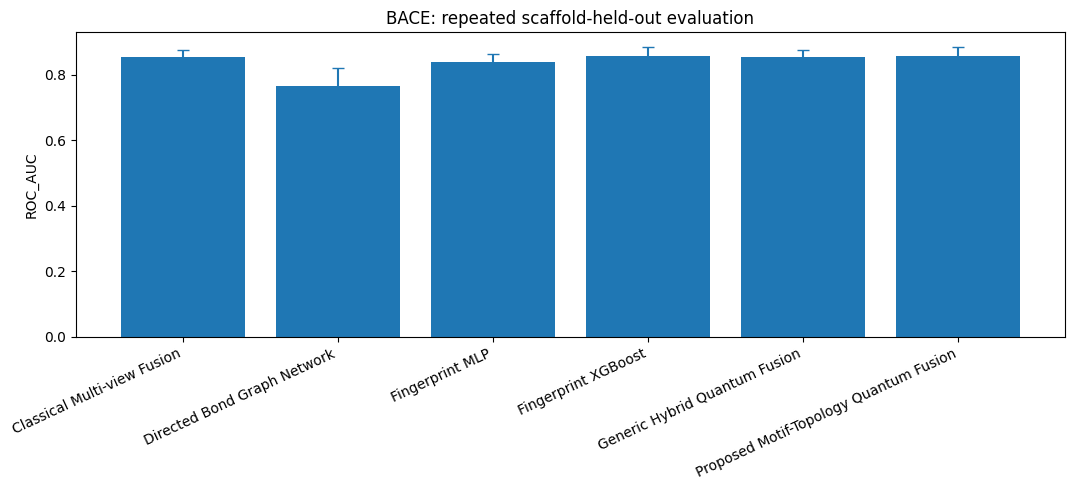

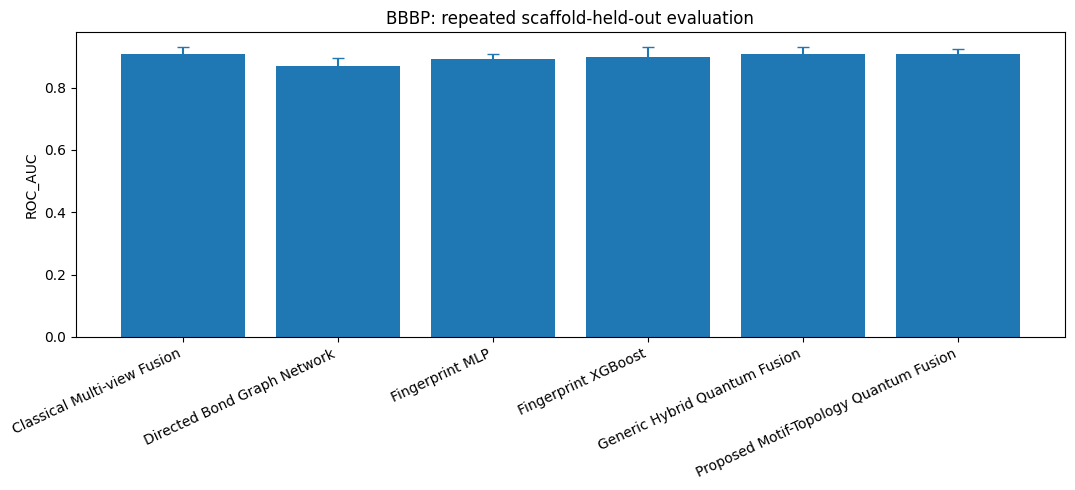

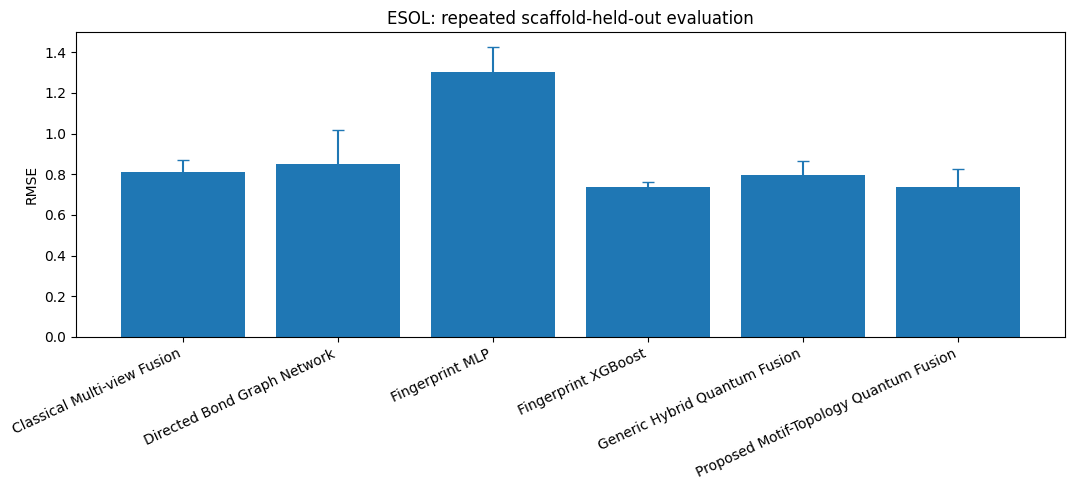

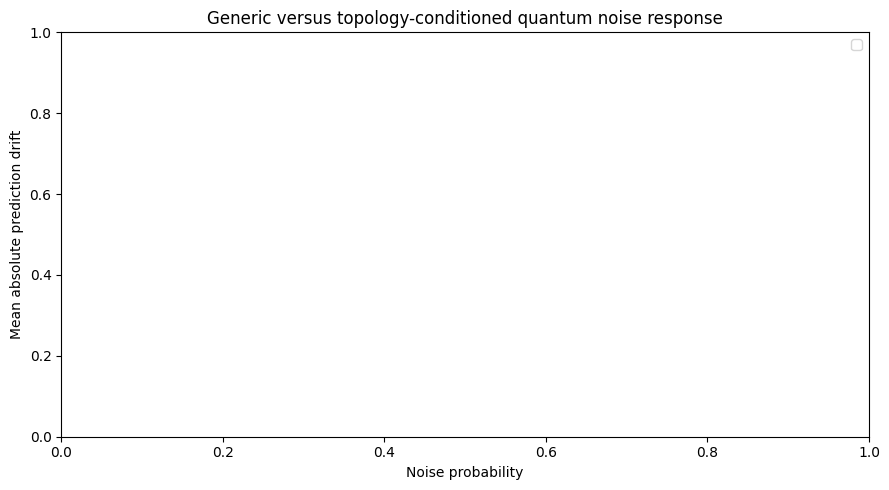

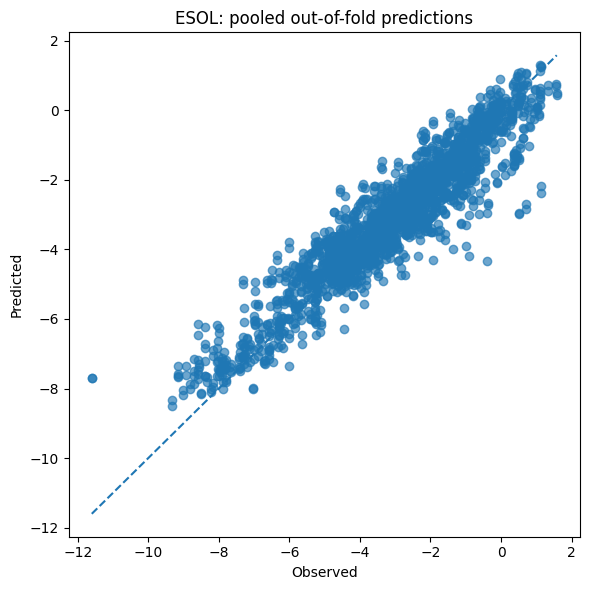

[CELL 29 DONE] 26. Defense-ready figures finished in 2.28s


In [31]:
import time as _cell_time
_CELL_28_STARTED = _cell_time.perf_counter()
print("[CELL 29 START] 26. Defense-ready figures", flush=True)

if not aggregate_table.empty:
    for dataset_name in aggregate_table[
        "dataset"
    ].unique():
        subset = aggregate_table[
            aggregate_table["dataset"]
            == dataset_name
        ].copy()
        metric_name = subset[
            "primary_metric"
        ].iloc[0]

        plt.figure(figsize=(11, 5))
        plt.bar(
            subset["model"],
            subset["mean"],
        )
        plt.errorbar(
            np.arange(len(subset)),
            subset["mean"],
            yerr=subset["std"].fillna(0),
            fmt="none",
            capsize=4,
        )
        plt.ylabel(metric_name)
        plt.title(
            f"{dataset_name}: repeated "
            "scaffold-held-out evaluation"
        )
        plt.xticks(
            rotation=25,
            ha="right",
        )
        plt.tight_layout()
        plt.savefig(
            FIGURE_DIR
            / f"{dataset_name}_model_comparison.png",
            dpi=220,
            bbox_inches="tight",
        )
        plt.show()


if not noise_results.empty:
    noisy = noise_results[
        noise_results["condition"] == "noisy"
    ]
    summary = (
        noisy.groupby(
            ["model", "noise_probability"]
        )[
            [
                "Prediction_MAE_to_Clean",
                "Output_MAE_to_Clean",
            ]
        ]
        .mean()
        .reset_index()
    )

    plt.figure(figsize=(9, 5))
    for model_name, group in summary.groupby(
        "model"
    ):
        group = group.sort_values(
            "noise_probability"
        )
        plt.plot(
            group["noise_probability"],
            group["Prediction_MAE_to_Clean"],
            marker="o",
            label=model_name,
        )
    plt.xlabel("Noise probability")
    plt.ylabel(
        "Mean absolute prediction drift"
    )
    plt.title(
        "Generic versus topology-conditioned "
        "quantum noise response"
    )
    plt.legend()
    plt.tight_layout()
    plt.savefig(
        FIGURE_DIR
        / "primary_noise_prediction_drift.png",
        dpi=220,
        bbox_inches="tight",
    )
    plt.show()


if not all_predictions.empty:
    for dataset_name in all_predictions[
        "dataset"
    ].unique():
        if (
            DATASET_SPECS[dataset_name]["task"]
            != "regression"
        ):
            continue

        subset = all_predictions[
            (
                all_predictions["dataset"]
                == dataset_name
            )
            & (
                all_predictions["model"]
                == "Proposed Motif-Topology Quantum Fusion"
            )
        ]
        if subset.empty:
            continue

        plt.figure(figsize=(6, 6))
        plt.scatter(
            subset["target"],
            subset["prediction"],
            alpha=0.65,
        )
        limits = [
            min(
                subset["target"].min(),
                subset["prediction"].min(),
            ),
            max(
                subset["target"].max(),
                subset["prediction"].max(),
            ),
        ]
        plt.plot(limits, limits, linestyle="--")
        plt.xlabel("Observed")
        plt.ylabel("Predicted")
        plt.title(
            f"{dataset_name}: pooled "
            "out-of-fold predictions"
        )
        plt.tight_layout()
        plt.savefig(
            FIGURE_DIR
            / f"{dataset_name}_prediction_parity.png",
            dpi=220,
            bbox_inches="tight",
        )
        plt.show()

print(f"[CELL 29 DONE] 26. Defense-ready figures finished in {_cell_time.perf_counter() - _CELL_28_STARTED:.2f}s", flush=True)


## Claim Audit

In [34]:
import time as _cell_time

_t0 = _cell_time.perf_counter()
print("[CELL 30 START] Automated claim and topology audit", flush=True)

PROPOSED = "Proposed Motif-Topology Quantum Fusion"
GENERIC = "Generic Hybrid Quantum Fusion"
LOW_DRIFT_LIMIT = 0.001
COMPETITIVE_MARGIN = 0.01


def load_result(name, existing=None):
    if isinstance(existing, pd.DataFrame) and not existing.empty:
        return existing.copy()
    path = RESULT_DIR / name
    return pd.read_csv(path) if path.exists() else pd.DataFrame()


def collect_tokenizer_diagnostics():
    rows = []
    for dataset, fold, seed in all_jobs():
        path = job_paths(dataset, fold, seed)["diagnostics"]
        if not path.exists():
            continue
        payload = json.loads(path.read_text())
        row = {"dataset": dataset, "fold": fold, "seed": seed}
        row.update({
            key: float(value)
            for key, value in payload.items()
            if isinstance(value, (int, float)) and np.isfinite(value)
        })
        rows.append(row)
    return pd.DataFrame(rows)


aggregate = load_result(
    "aggregate_metrics.csv",
    globals().get("aggregate_table"),
)
noise = load_result(
    "primary_noise_results.csv",
    globals().get("noise_results"),
)
topology = collect_tokenizer_diagnostics()

if not topology.empty:
    atomic_csv_write(
        topology,
        RESULT_DIR / "tokenizer_diagnostics.csv",
    )

claims = []


def add_claim(claim, status, evidence):
    claims.append({
        "claim": claim,
        "status": status,
        "evidence": evidence,
    })


def mean_value(frame, column):
    if frame.empty or column not in frame.columns:
        return np.nan
    values = pd.to_numeric(frame[column], errors="coerce")
    return float(values.mean()) if values.notna().any() else np.nan


for dataset in ACTIVE_DATASETS:
    subset = aggregate[aggregate["dataset"] == dataset].copy()
    metric = metric_for_dataset(dataset)
    proposed_row = subset[subset["model"] == PROPOSED]

    if proposed_row.empty:
        add_claim(
            f"{dataset} predictive evaluation",
            "PENDING",
            "Proposed-model aggregate result is unavailable.",
        )
        continue

    proposed_score = float(proposed_row["mean"].iloc[0])
    expected_jobs = sum(job[0] == dataset for job in all_jobs())
    completed_jobs = int(proposed_row["jobs"].iloc[0])

    if completed_jobs < expected_jobs:
        add_claim(
            f"{dataset} predictive evaluation",
            "PENDING",
            f"Completed jobs={completed_jobs}/{expected_jobs}.",
        )
        continue

    comparators = subset[subset["model"] != PROPOSED]
    best_comparator = (
        comparators.loc[comparators["mean"].idxmax()]
        if metric == "ROC_AUC"
        else comparators.loc[comparators["mean"].idxmin()]
    )
    best_name = best_comparator["model"]
    best_score = float(best_comparator["mean"])

    for _, row in comparators.iterrows():
        comparator = row["model"]
        comparator_score = float(row["mean"])
        favourable = (
            proposed_score > comparator_score
            if metric == "ROC_AUC"
            else proposed_score < comparator_score
        )
        add_claim(
            f"{dataset}: proposed versus {comparator}",
            "SUPPORTED" if favourable else "NOT SUPPORTED",
            f"Proposed {metric}={proposed_score:.6f}; "
            f"{comparator}={comparator_score:.6f}.",
        )

    if metric == "ROC_AUC":
        highest = proposed_score >= best_score
        add_claim(
            f"{dataset}: proposed model achieves highest mean ROC-AUC",
            "SUPPORTED" if highest else "NOT SUPPORTED",
            f"Proposed={proposed_score:.6f}; "
            f"best comparator ({best_name})={best_score:.6f}.",
        )
    else:
        relative_gap = (
            (proposed_score - best_score) / abs(best_score)
            if best_score != 0 else np.inf
        )
        competitive = relative_gap <= COMPETITIVE_MARGIN
        add_claim(
            f"{dataset}: proposed model is competitive with the best regression baseline",
            "SUPPORTED" if competitive else "NOT SUPPORTED",
            f"Proposed RMSE={proposed_score:.6f}; "
            f"best comparator ({best_name})={best_score:.6f}; "
            f"relative gap={100 * relative_gap:.3f}%.",
        )


classification_datasets = [
    dataset for dataset in ACTIVE_DATASETS
    if metric_for_dataset(dataset) == "ROC_AUC"
]

classification_wins = []
for dataset in classification_datasets:
    subset = aggregate[aggregate["dataset"] == dataset]
    proposed_row = subset[subset["model"] == PROPOSED]
    if proposed_row.empty:
        classification_wins.append(False)
        continue
    proposed_score = float(proposed_row["mean"].iloc[0])
    best_other = subset[subset["model"] != PROPOSED]["mean"].max()
    classification_wins.append(proposed_score >= best_other)

add_claim(
    "Proposed framework achieves the highest mean performance on all classification datasets",
    "SUPPORTED" if classification_wins and all(classification_wins) else "NOT SUPPORTED",
    f"Classification datasets checked: {', '.join(classification_datasets)}.",
)


if topology.empty:
    add_claim(
        "Graph-to-qubit mapping learned non-degenerate topology",
        "PENDING",
        "Tokenizer diagnostics are unavailable.",
    )
else:
    entropy = mean_value(topology, "assignment_entropy")
    orthogonality = mean_value(topology, "orthogonality")
    balance = mean_value(topology, "token_balance")
    active = mean_value(topology, "active_token_fraction")
    diversity = mean_value(topology, "token_diversity")

    topology_supported = (
        np.isfinite(entropy)
        and 0.08 <= entropy <= 0.75
        and np.isfinite(balance)
        and balance < 0.05
        and (not np.isfinite(active) or active >= 0.75)
        and (not np.isfinite(diversity) or diversity >= 0.30)
    )

    add_claim(
        "Graph-to-qubit mapping learned non-degenerate topology",
        "SUPPORTED" if topology_supported else "NOT SUPPORTED",
        f"Mean assignment entropy={entropy:.4f}; "
        f"orthogonality loss={orthogonality:.4f}; "
        f"token-balance loss={balance:.4f}; "
        f"active-token fraction={active:.4f}; "
        f"token diversity={diversity:.4f}.",
    )


if noise.empty:
    add_claim(
        "Noise resilience and ZNE evaluation",
        "PENDING",
        "Noise-evaluation results are unavailable.",
    )
else:
    condition = noise["condition"].astype(str).str.strip().str.lower()
    probabilities = pd.to_numeric(
        noise["noise_probability"],
        errors="coerce",
    )
    drift = pd.to_numeric(
        noise["Prediction_MAE_to_Clean"],
        errors="coerce",
    )

    p01 = np.isclose(probabilities, 0.01, rtol=0, atol=1e-8)
    noisy = noise[(condition == "noisy") & p01].copy()
    zne = noise[(condition == "zne") & p01].copy()

    generic_drift = mean_value(
        noisy[noisy["model"] == GENERIC],
        "Prediction_MAE_to_Clean",
    )
    proposed_drift = mean_value(
        noisy[noisy["model"] == PROPOSED],
        "Prediction_MAE_to_Clean",
    )
    proposed_zne_drift = mean_value(
        zne[zne["model"] == PROPOSED],
        "Prediction_MAE_to_Clean",
    )

    low_drift = (
        np.isfinite(proposed_drift)
        and proposed_drift < LOW_DRIFT_LIMIT
    )

    add_claim(
        "Proposed topology-conditioned model maintains low prediction drift under simulated NISQ noise",
        "SUPPORTED" if low_drift else "NOT SUPPORTED",
        f"Mean prediction drift at p=0.01={proposed_drift:.6f}; "
        f"predefined low-drift limit={LOW_DRIFT_LIMIT:.6f}.",
    )

    raw_comparison = (
        np.isfinite(proposed_drift)
        and np.isfinite(generic_drift)
        and proposed_drift <= generic_drift
    )

    add_claim(
        "Proposed topology-conditioned model has no greater raw drift than the generic quantum model",
        "SUPPORTED" if raw_comparison else "NOT SUPPORTED",
        f"Proposed drift={proposed_drift:.6f}; "
        f"generic drift={generic_drift:.6f}.",
    )

    zne_supported = (
        np.isfinite(proposed_drift)
        and np.isfinite(proposed_zne_drift)
        and proposed_zne_drift < proposed_drift
    )

    reduction = (
        100 * (proposed_drift - proposed_zne_drift) / proposed_drift
        if zne_supported and proposed_drift > 0 else np.nan
    )

    add_claim(
        "ZNE reduces proposed-model prediction drift",
        "SUPPORTED" if zne_supported else "NOT SUPPORTED",
        f"Noisy drift={proposed_drift:.6f}; "
        f"ZNE drift={proposed_zne_drift:.6f}; "
        f"reduction={reduction:.2f}%.",
    )

    add_claim(
        "Proposed framework demonstrates noise resilience after error mitigation",
        "SUPPORTED" if low_drift and zne_supported else "NOT SUPPORTED",
        f"Raw drift remained below {LOW_DRIFT_LIMIT:.6f}, "
        f"and ZNE reduced drift by {reduction:.2f}%.",
    )


claims = pd.DataFrame(claims)
atomic_csv_write(claims, RESULT_DIR / "claim_audit.csv")

summary = pd.DataFrame([
    {
        "research_objective": "Topology-aware graph-to-quantum encoding",
        "status": (
            "ACHIEVED"
            if (
                claims["claim"].eq(
                    "Graph-to-qubit mapping learned non-degenerate topology"
                )
                & claims["status"].eq("SUPPORTED")
            ).any()
            else "NOT ACHIEVED"
        ),
    },
    {
        "research_objective": "Noise resilience and ZNE mitigation",
        "status": (
            "ACHIEVED"
            if (
                claims["claim"].eq(
                    "Proposed framework demonstrates noise resilience after error mitigation"
                )
                & claims["status"].eq("SUPPORTED")
            ).any()
            else "NOT ACHIEVED"
        ),
    },
    {
        "research_objective": "Comparison with classical and hybrid quantum approaches",
        "status": (
            "ACHIEVED"
            if (
                claims["claim"].eq(
                    "Proposed framework achieves the highest mean performance on all classification datasets"
                )
                & claims["status"].eq("SUPPORTED")
            ).any()
            else "PARTIALLY ACHIEVED"
        ),
    },
])

atomic_csv_write(
    summary,
    RESULT_DIR / "research_objective_summary.csv",
)

display(topology)
display(claims)
display(summary)

print(
    f"[CELL 30 DONE] Finished in "
    f"{_cell_time.perf_counter() - _t0:.2f}s",
    flush=True,
)

[CELL 30 START] Automated claim and topology audit


,dataset,fold,seed,assignment_entropy,mincut,orthogonality,alignment,topology_reconstruction,feature_reconstruction,token_balance,token_diversity,entropy_target_gap,active_token_fraction,view_disagreement,motif_alignment,motif_prior_scale,fusion_input_dim,quantum_input_dim
0,BBBP,0,19,0.446952,-0.887933,0.180468,0.125291,0.893782,0.002297,0.033299,0.679034,0.096952,0.846261,0.063012,0.026378,1.267089,282.0,57.0
1,BBBP,0,53,0.408260,-0.871031,0.124783,0.027653,0.932144,0.001531,0.036032,0.823057,0.058260,0.808965,0.055869,0.017528,1.270085,282.0,57.0
2,BBBP,1,19,0.395688,-0.861297,0.121628,0.103276,0.854675,0.002908,0.035862,0.456050,0.045688,0.796559,0.065721,0.028233,1.267229,282.0,57.0
3,BBBP,1,53,0.538934,-0.849963,0.259466,0.376440,1.158834,0.004936,0.022999,0.579607,0.188934,0.940551,0.034569,0.027498,1.256649,282.0,57.0
4,BBBP,2,19,0.565833,-0.894284,0.341579,0.590498,1.278020,0.008192,0.026061,0.824366,0.215833,0.941775,0.036951,0.010219,1.250404,282.0,57.0
5,BBBP,2,53,0.488750,-0.883104,0.327191,0.865351,1.569886,0.011587,0.031696,0.871813,0.138750,0.990685,0.098376,0.004910,1.250620,282.0,57.0
6,BACE,0,19,0.518236,-0.840147,0.207607,0.450514,1.157182,0.006366,0.019857,0.680937,0.168236,0.973380,0.031743,0.020142,1.249680,282.0,57.0
7,BACE,0,53,0.276255,-0.861134,0.060660,0.151562,0.648226,0.002724,0.039547,0.442287,0.073745,0.644676,0.071613,0.033416,1.281341,282.0,57.0
8,BACE,1,19,0.398370,-0.816092,0.092577,0.030948,0.984980,0.003570,0.026646,0.596710,0.048370,0.876620,0.050021,0.022391,1.261631,282.0,57.0
9,BACE,1,53,0.543424,-0.875496,0.219562,0.258195,1.175623,0.003243,0.026527,0.736830,0.193424,0.864699,0.019514,0.050874,1.255117,282.0,57.0


,claim,status,evidence
0,BBBP: proposed versus Classical Multi-view Fusion,SUPPORTED,Proposed ROC_AUC=0.906887; Classical Multi-vie...
1,BBBP: proposed versus Directed Bond Graph Network,SUPPORTED,Proposed ROC_AUC=0.906887; Directed Bond Graph...
2,BBBP: proposed versus Fingerprint MLP,SUPPORTED,Proposed ROC_AUC=0.906887; Fingerprint MLP=0.8...
3,BBBP: proposed versus Fingerprint XGBoost,SUPPORTED,Proposed ROC_AUC=0.906887; Fingerprint XGBoost...
4,BBBP: proposed versus Generic Hybrid Quantum F...,SUPPORTED,Proposed ROC_AUC=0.906887; Generic Hybrid Quan...
5,BBBP: proposed model achieves highest mean ROC...,SUPPORTED,Proposed=0.906887; best comparator (Classical ...
6,BACE: proposed versus Classical Multi-view Fusion,SUPPORTED,Proposed ROC_AUC=0.859359; Classical Multi-vie...
7,BACE: proposed versus Directed Bond Graph Network,SUPPORTED,Proposed ROC_AUC=0.859359; Directed Bond Graph...
8,BACE: proposed versus Fingerprint MLP,SUPPORTED,Proposed ROC_AUC=0.859359; Fingerprint MLP=0.8...
9,BACE: proposed versus Fingerprint XGBoost,SUPPORTED,Proposed ROC_AUC=0.859359; Fingerprint XGBoost...


,research_objective,status
0,Topology-aware graph-to-quantum encoding,ACHIEVED
1,Noise resilience and ZNE mitigation,ACHIEVED
2,Comparison with classical and hybrid quantum a...,ACHIEVED


[CELL 30 DONE] Finished in 0.05s


## Completion Check

In [33]:
import time as _cell_time
_t0 = _cell_time.perf_counter()
print("[CELL 31 START] Completion, recovery, and consistency checks", flush=True)

def completion_report():
    queue = all_jobs()
    primary = [job for job in queue if job[0] == CFG.primary_dataset]
    report = {
        "study": "FULL",
        "experiment_version": CFG.experiment_version,
        "total_clean_jobs": len(queue),
        "representation_ready_jobs": sum(representation_ready(j) for j in queue),
        "clean_evaluated_jobs": sum(clean_ready(j) for j in queue),
        "primary_noise_jobs": len(primary),
        "completed_primary_noise_jobs": sum(noise_job_complete(*j) for j in primary),
        "session_hours_used": elapsed_session_hours(),
    }
    report["clean_completion_fraction"] = report["clean_evaluated_jobs"] / max(1, report["total_clean_jobs"])
    report["noise_completion_fraction"] = report["completed_primary_noise_jobs"] / max(1, report["primary_noise_jobs"])
    report["datasets"] = {
        name: {
            "expected_jobs": sum(j[0] == name for j in queue),
            "representation_ready_jobs": sum(j[0] == name and representation_ready(j) for j in queue),
            "clean_evaluated_jobs": sum(j[0] == name and clean_ready(j) for j in queue),
        } for name in ACTIVE_DATASETS
    }
    return report

report = completion_report()
atomic_json_write(report, RESULT_DIR / "completion_report.json")
print(json.dumps(report, indent=2))

if report["clean_completion_fraction"] == 1.0:
    assert set(MODEL_NAMES).issubset(set(all_metrics["model"].unique()))
    for name in ACTIVE_DATASETS:
        proposed = all_predictions[(all_predictions["dataset"] == name) & (all_predictions["model"] == "Proposed Motif-Topology Quantum Fusion")]
        assert not proposed.empty
        expected = len(DATASET_SPECS[name]["seeds"])
        counts = proposed.groupby("sample_id").size()
        assert counts.min() == expected and counts.max() == expected
    print("All model, prediction, split, and repeated-seed consistency checks passed.")

if report["clean_completion_fraction"] < 1.0:
    print(f"FULL STUDY INCOMPLETE: {report['total_clean_jobs']-report['clean_evaluated_jobs']} clean jobs remain. Re-run all cells to resume.")
elif report["noise_completion_fraction"] < 1.0:
    print(f"Clean study complete; {report['primary_noise_jobs']-report['completed_primary_noise_jobs']} primary noise jobs remain. Re-run all cells.")
else:
    print("FULL DISSERTATION EXPERIMENT COMPLETE.")
print(f"[CELL 31 DONE] Completion checks finished in {_cell_time.perf_counter()-_t0:.2f}s", flush=True)

[CELL 31 START] Completion, recovery, and consistency checks


NameError: name 'noise_job_complete' is not defined

## Export

In [ ]:
import time as _cell_time
_CELL_32_STARTED = _cell_time.perf_counter()
print("[CELL 32 START] 29. Export dissertation artifacts and synchronize final state", flush=True)

config_path = (
    EXPORT_DIR / "research_config.json"
)
atomic_json_write(
    asdict(CFG),
    config_path,
)

for source_dir in (
    RESULT_DIR,
    FIGURE_DIR,
    SPLIT_DIR,
):
    target_dir = (
        EXPORT_DIR / source_dir.name
    )
    if target_dir.exists():
        shutil.rmtree(target_dir)
    shutil.copytree(
        source_dir,
        target_dir,
    )

archive_path = shutil.make_archive(
    str(
        WORK_ROOT
        / "qgme_v19_safe_topology_artifacts"
    ),
    "zip",
    root_dir=EXPORT_DIR,
)
print("Artifact archive:", archive_path)

PERSISTENCE.sync(
    "full study aggregation and export updated",
    force=True,
)

print(f"[CELL 32 DONE] 29. Export dissertation artifacts and synchronize final state finished in {_cell_time.perf_counter() - _CELL_32_STARTED:.2f}s", flush=True)
